# Tarification automobile — approche classique, sans séparation des sinistres graves

**Projet d'actuariat — Groupe 1**

Ce document met en œuvre une tarification automobile complète à partir de deux bases :
un fichier **Contrats** et un fichier **Sinistres**. Il suit les six points de l'énoncé,
de A à F, et le cadre méthodologique du cours :

$$\text{Prime pure} = \mathbb{E}(N) \times \mathbb{E}(X) = \text{Fréquence} \times \text{Coût moyen}$$

**Ce qui distingue cette variante.** Les sinistres graves ne font l'objet d'**aucun
traitement particulier** : pas de seuil de gravité, pas d'écrêtement, pas de modèle
dédié. Tous les sinistres sont conservés et modélisés ensemble, par une fréquence et un
coût moyen. C'est l'approche de tarification la plus simple ; le document en montre
aussi honnêtement les limites.

## Plan du document

| § | Contenu | Point de l'énoncé |
|---|---|---|
| 0 | Cadrage, environnement, fonctions utilitaires | — |
| 1 | Fiabilisation et préparation des données | **A** |
| 2 | Montants de sinistres : une seule population, sans seuil de gravité | **B** |
| 3 | Approche Fréquence × Coût | **C** |
| 4 | Modélisation GLM : fréquence et coût moyen | **D** |
| 5 | Séparation Train / Test : aléatoire et temporelle | **E** |
| 6 | Comparaison des approches de pricing | **F** |
| 7 | Tarif final, tarif commercial, synthèse et limites | — |

> **Ordre des parties D et E.** Les modèles sont spécifiés au §4 sur le portefeuille
> complet (choix de la loi, sélection des variables, lecture des coefficients). Au §5,
> ils sont **réestimés sur l'échantillon d'apprentissage seul** avant d'être confrontés
> à l'échantillon de test, et la sélection de variables y est rejouée pour vérifier
> qu'elle ne dépend pas des données de test.

---
## §0 — Cadrage et environnement

### 0.1 Imports

**Note technique importante.** Sur cette machine, `import statsmodels.api` échoue :
Windows Smart App Control bloque le chargement d'une DLL du sous-module de séries
temporelles (`_cfa_simulation_smoother`), dont nous n'avons aucun besoin ici.
On importe donc **directement les sous-modules utiles**, ce qui contourne le problème
sans rien perdre. Si vous exécutez ce notebook sur une autre machine, ces imports
fonctionnent de la même façon.

In [1]:
import sys
import time
import warnings
from pathlib import Path

# La sortie console de Windows utilise cp1252 par defaut, qui ne connait pas
# certains caracteres typographiques francais. On force l'UTF-8.
try:
    sys.stdout.reconfigure(encoding="utf-8")
except Exception:
    pass

import numpy as np
import pandas as pd
import matplotlib


def dans_jupyter():
    """Indique si le code tourne dans un noyau Jupyter (vrai) ou comme script (faux)."""
    try:
        return get_ipython().__class__.__name__ == "ZMQInteractiveShell"
    except NameError:
        return False


# Hors Jupyter, on utilise un backend non interactif : les figures sont enregistrees
# dans outputs/figures/ sans ouvrir de fenetre bloquante.
if not dans_jupyter():
    matplotlib.use("Agg")

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats

# --- Import statsmodels : sous-modules ciblés (voir note ci-dessus) ---
import statsmodels.formula.api as smf
from statsmodels.genmod import families
from statsmodels.genmod.families import links

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}".replace(",", " "))

print("pandas      ", pd.__version__)
print("numpy       ", np.__version__)
import statsmodels
print("statsmodels ", statsmodels.__version__)
import scipy
print("scipy       ", scipy.__version__)

pandas       3.0.5
numpy        2.5.3
statsmodels  0.14 (re-implementation locale)
scipy        1.18.1


### 0.2 Paramètres de l'étude

Toutes les constantes de pilotage sont regroupées ici : modifier une valeur et
réexécuter le document suffit à produire une variante complète de l'étude.

La valeur de `AGE_PERMIS_MEDIAN` n'est **pas arbitraire** : elle est établie et
justifiée au §1.6. Aucun seuil de gravité ne figure parmi les paramètres : cette
variante de l'étude n'en applique pas.

In [2]:
DOSSIER = Path.cwd()
DATA = DOSSIER / "data"
FIGURES = DOSSIER / "outputs_classique" / "figures"
TABLES = DOSSIER / "outputs_classique" / "tables"
for d in (FIGURES, TABLES):
    d.mkdir(parents=True, exist_ok=True)

# --- Paramètres méthodologiques ---
DATE_CUT = pd.Timestamp("2024-01-01")   # frontière du découpage temporel (§5.1)
PART_TRAIN = 0.80             # part d'apprentissage du découpage aléatoire (§5.2)
AGE_PERMIS_MEDIAN = 20        # âge médian d'obtention du permis, mesuré au §1.6
AGE_MIN, AGE_MAX = 18, 90     # bornes de plausibilité de l'âge du conducteur
BM_MIN, BM_MAX = 0.50, 3.50   # bornes réglementaires du coefficient bonus-malus
PUISS_MIN, PUISS_MAX = 1, 40  # bornes de plausibilité de la puissance fiscale
GRAINE = 2026                 # graine aléatoire, fixée pour la reproductibilité

rng = np.random.default_rng(GRAINE)

### 0.3 Fonctions utilitaires

Mise en forme française des nombres (espace comme séparateur de milliers, virgule
décimale), style graphique homogène, et deux helpers d'export. Regrouper ces
fonctions ici évite de répéter du code de présentation dans tout le document.

In [3]:
PALETTE = {
    "encre": "#0B2B33",
    "petrole": "#177C8C",
    "ambre": "#D99A2B",
    "brique": "#A8443A",
    "gris": "#8C9BA0",
}
CYCLE = [PALETTE["petrole"], PALETTE["ambre"], PALETTE["brique"],
         PALETTE["encre"], PALETTE["gris"]]

plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "figure.dpi": 110,
    "savefig.dpi": 160,
    "savefig.bbox": "tight",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "-",
    "axes.titlesize": 11.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.prop_cycle": plt.cycler(color=CYCLE),
    "font.size": 9.5,
})


def fr(x, dec=0):
    """Formate un nombre à la française : espace fin pour les milliers, virgule décimale."""
    if x is None or (isinstance(x, float) and not np.isfinite(x)):
        return "n.d."
    return f"{x:,.{dec}f}".replace(",", " ").replace(".", ",")


def pct(x, dec=1):
    """Formate une proportion (0-1) en pourcentage à la française."""
    if x is None or (isinstance(x, float) and not np.isfinite(x)):
        return "n.d."
    return f"{100 * x:,.{dec}f}".replace(",", " ").replace(".", ",") + " %"


def axe_fr(ax, axis="y"):
    """Applique le format numérique français à un axe."""
    fmt = mticker.FuncFormatter(lambda v, _: fr(v))
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)
    return ax


def _ecrire_avec_reprise(fonction_ecriture, chemin, tentatives=6, attente=0.6):
    """Execute une ecriture fichier en reessayant si le systeme la refuse.

    Le dossier du projet se trouve sur le Bureau, qui peut etre synchronise par un
    service de sauvegarde en ligne. Celui-ci verrouille brievement les fichiers qu'il
    est en train d'indexer, ce qui fait echouer une ecriture par OSError de facon
    intermittente. Quelques tentatives espacees suffisent a passer.
    """
    derniere = None
    for essai in range(tentatives):
        try:
            fonction_ecriture()
            return
        except OSError as exc:
            derniere = exc
            time.sleep(attente * (essai + 1))
    raise OSError(f"Ecriture impossible dans {chemin} apres {tentatives} tentatives "
                  f"({derniere}).")


def sauver_fig(nom):
    """Enregistre la figure courante dans outputs/figures/ et l'affiche."""
    chemin = FIGURES / f"{nom}.png"
    _ecrire_avec_reprise(lambda: plt.savefig(chemin), chemin)
    if dans_jupyter():
        plt.show()
    plt.close()


def exporter_table(df, nom, index=True):
    """Enregistre un tableau dans outputs/tables/ au format Excel."""
    chemin = TABLES / f"{nom}.xlsx"
    _ecrire_avec_reprise(lambda: df.to_excel(chemin, index=index), chemin)
    return df


def display(obj):
    """Affiche un tableau. Dans Jupyter, la fonction native prend le relais et rend
    un tableau mis en forme ; hors Jupyter, on retombe sur un affichage texte."""
    try:
        from IPython.display import display as _d
        _d(obj)
    except Exception:
        print(obj.to_string() if hasattr(obj, "to_string") else obj)


def titre(txt, niveau=1):
    """Affiche un séparateur lisible dans les sorties texte."""
    barre = "=" if niveau == 1 else "-"
    print(f"\n{barre * 78}\n{txt}\n{barre * 78}")

---
# §1 — Partie A · Fiabilisation et préparation des données

> **Ce que demande l'énoncé (point A)**
> 1. Contrôle de la qualité et de la cohérence des données ;
> 2. Identification et traitement des valeurs manquantes, aberrantes ou incohérentes ;
> 3. Contrôle de la cohérence entre les bases Contrats et Sinistres ;
> 4. Création des variables nécessaires à la tarification, notamment l'exposition.

**Principe directeur de cette partie.** Une donnée fausse ne se remplace pas par une
moyenne tant qu'on n'a pas cherché à la **reconstruire**. L'ordre de priorité appliqué
systématiquement est le suivant :

1. **Reconstruire** la valeur à partir d'une autre variable de la même ligne ;
2. **Imputer** statistiquement, seulement si aucun recoupement n'est possible ;
3. **Supprimer**, uniquement si la ligne n'apporte aucune information exploitable.

Chaque correction est tracée par une variable indicatrice, et le §1.8 dresse le bilan
avant / après pour qu'aucune ligne ne disparaisse sans être comptée.

## 1.1 Chargement et inventaire

In [4]:
contrats_brut = pd.read_excel(DATA / "groupe1_base1_contrats.xlsx")
sinistres_brut = pd.read_excel(DATA / "groupe1_base2_sinistres.xlsx")

titre("BASE CONTRATS — inventaire")
print(f"Dimensions : {fr(contrats_brut.shape[0])} lignes x {contrats_brut.shape[1]} colonnes")
print(contrats_brut.dtypes.to_string())
print("\nApercu :")
display(contrats_brut.head(5))

titre("BASE SINISTRES — inventaire")
print(f"Dimensions : {fr(sinistres_brut.shape[0])} lignes x {sinistres_brut.shape[1]} colonnes")
print(sinistres_brut.dtypes.to_string())
print("\nApercu :")
display(sinistres_brut.head(5))


BASE CONTRATS — inventaire
Dimensions : 20 120 lignes x 14 colonnes
id_police                 str
date_effet_contrat     object
duree_exposition      float64
age_conducteur        float64
sexe                      str
anciennete_permis     float64
bonus_malus           float64
zone_geo                  str
usage_vehicule            str
puissance_fiscale       int64
classe_vehicule           str
age_vehicule            int64
carburant                 str
type_couverture           str

Apercu :


,id_police,date_effet_contrat,duree_exposition,age_conducteur,sexe,anciennete_permis,bonus_malus,zone_geo,usage_vehicule,puissance_fiscale,classe_vehicule,age_vehicule,carburant,type_couverture
0,POL104142,2023-02-05 00:00:00,0.510,46.000,M,23.000,0.840,B,Privé,9,SUV,25,Essence,Tiers étendu
1,POL109134,2023-12-04 00:00:00,0.526,NaN,F,8.000,0.860,B,Privé,12,Berline,0,Diesel,Tiers
2,POL109665,2023-10-24 00:00:00,0.966,46.000,M,23.000,0.950,C,Privé,7,SUV,1,Hybride,Tous risques
3,POL110918,2023-09-07 00:00:00,0.497,30.000,F,10.000,0.710,C,Privé,8,Citadine,2,Essence,Tiers étendu
4,POL102552,2023-07-02 00:00:00,0.846,36.000,F,16.000,0.840,A,Privé,8,Citadine,12,Essence,Tiers étendu



BASE SINISTRES — inventaire
Dimensions : 1 348 lignes x 7 colonnes
id_sinistre               str
id_police                 str
date_sinistre          object
nature_sinistre           str
montant_sinistre       object
responsabilite_pct    float64
statut                    str

Apercu :


,id_sinistre,id_police,date_sinistre,nature_sinistre,montant_sinistre,responsabilite_pct,statut
0,SIN500473,POL107932,2023-10-06 00:00:00,Vol partiel,-500,100.000,Clos
1,SIN500702,POL111924,2023-12-04 00:00:00,Dégât matériel léger,NaN,25.000,Clos
2,SIN501321,POL101955,2024-02-07 00:00:00,Collision mineure,630.380,100.000,Clos
3,SIN500895,POL102543,2024-04-07 00:00:00,Vandalisme,1 859.550,50.000,Clos
4,SIN501001,POL113465,2024-03-05 00:00:00,Dégât matériel léger,1 933.680,0.000,Clos


**Première alerte, visible dès les types.** La colonne `montant_sinistre` est de type
`object` et non numérique : au moins une valeur n'est pas un nombre. De même,
`duree_exposition` est bien numérique, mais il faudra vérifier qu'elle reste dans
l'intervalle `]0 ; 1]` attendu pour une exposition exprimée en années-police.

### Dictionnaire des variables

In [5]:
dico = pd.DataFrame([
    ("id_police",          "Contrats",  "Identifiant du contrat",              "Clé de jointure"),
    ("date_effet_contrat", "Contrats",  "Date de prise d'effet",               "Début de la période de couverture"),
    ("duree_exposition",   "Contrats",  "Exposition en années-police",         "Offset du GLM de fréquence"),
    ("age_conducteur",     "Contrats",  "Âge du conducteur principal (ans)",   "Variable tarifaire"),
    ("sexe",               "Contrats",  "Sexe du conducteur",                  "Variable tarifaire"),
    ("anciennete_permis",  "Contrats",  "Ancienneté du permis (ans)",          "Variable tarifaire"),
    ("bonus_malus",        "Contrats",  "Coefficient de réduction-majoration", "Tarification a posteriori"),
    ("zone_geo",           "Contrats",  "Zone géographique (A à E)",           "Variable tarifaire"),
    ("usage_vehicule",     "Contrats",  "Usage déclaré du véhicule",           "Variable tarifaire"),
    ("puissance_fiscale",  "Contrats",  "Puissance fiscale (CV)",              "Variable tarifaire"),
    ("classe_vehicule",    "Contrats",  "Segment du véhicule",                 "Variable tarifaire"),
    ("age_vehicule",       "Contrats",  "Âge du véhicule (ans)",               "Variable tarifaire"),
    ("carburant",          "Contrats",  "Type de motorisation",                "Variable tarifaire"),
    ("type_couverture",    "Contrats",  "Étendue des garanties",               "Variable tarifaire / périmètre"),
    ("id_sinistre",        "Sinistres", "Identifiant du sinistre",             "Détection des doublons"),
    ("date_sinistre",      "Sinistres", "Date de survenance",                  "Découpage temporel (§5)"),
    ("nature_sinistre",    "Sinistres", "Nature du dommage",                   "Reconstruction des montants (§1.6)"),
    ("montant_sinistre",   "Sinistres", "Charge du sinistre",                  "Variable cible de sévérité"),
    ("responsabilite_pct", "Sinistres", "Taux de responsabilité (%)",          "Contrôle de cohérence"),
    ("statut",             "Sinistres", "Sinistre clos ou ouvert",             "Test de sensibilité (§2.3)"),
], columns=["Variable", "Base", "Description", "Rôle dans la tarification"])
exporter_table(dico, "1_1_dictionnaire_variables", index=False)
display(dico)

,Variable,Base,Description,Rôle dans la tarification
0,id_police,Contrats,Identifiant du contrat,Clé de jointure
1,date_effet_contrat,Contrats,Date de prise d'effet,Début de la période de couverture
2,duree_exposition,Contrats,Exposition en années-police,Offset du GLM de fréquence
3,age_conducteur,Contrats,Âge du conducteur principal (ans),Variable tarifaire
4,sexe,Contrats,Sexe du conducteur,Variable tarifaire
5,anciennete_permis,Contrats,Ancienneté du permis (ans),Variable tarifaire
6,bonus_malus,Contrats,Coefficient de réduction-majoration,Tarification a posteriori
7,zone_geo,Contrats,Zone géographique (A à E),Variable tarifaire
8,usage_vehicule,Contrats,Usage déclaré du véhicule,Variable tarifaire
9,puissance_fiscale,Contrats,Puissance fiscale (CV),Variable tarifaire


## 1.2 Contrôle qualité — base Contrats

### 1.2.1 Doublons et valeurs manquantes

In [6]:
titre("DOUBLONS — base Contrats", 2)
n_dup_lignes = int(contrats_brut.duplicated().sum())
n_dup_id = int(contrats_brut["id_police"].duplicated().sum())
print(f"Lignes strictement dupliquees    : {fr(n_dup_lignes)}")
print(f"Identifiants de police dupliques : {fr(n_dup_id)}")
print(f"Polices distinctes               : {fr(contrats_brut['id_police'].nunique())}")
print("\n-> Les deux compteurs coincident : les doublons sont des duplications integrales")
print("   de lignes, et non deux contrats distincts partageant un identifiant.")

titre("VALEURS MANQUANTES — base Contrats", 2)
manq = pd.DataFrame({
    "Manquants": contrats_brut.isna().sum(),
    "Part": contrats_brut.isna().mean(),
})
manq = manq[manq["Manquants"] > 0].sort_values("Manquants", ascending=False)
manq["Part"] = manq["Part"].map(lambda v: pct(v, 2))
display(manq)


------------------------------------------------------------------------------
DOUBLONS — base Contrats
------------------------------------------------------------------------------
Lignes strictement dupliquees    : 120
Identifiants de police dupliques : 120
Polices distinctes               : 20 000

-> Les deux compteurs coincident : les doublons sont des duplications integrales
   de lignes, et non deux contrats distincts partageant un identifiant.

------------------------------------------------------------------------------
VALEURS MANQUANTES — base Contrats
------------------------------------------------------------------------------


,Manquants,Part
carburant,403,"2,00 %"
age_conducteur,402,"2,00 %"
anciennete_permis,299,"1,49 %"
bonus_malus,299,"1,49 %"
zone_geo,201,"1,00 %"


### 1.2.2 Modalités des variables qualitatives

On recense les modalités observées pour repérer les problèmes d'**harmonisation**
(casse, accents, espaces parasites) qui feraient éclater artificiellement une même
catégorie en plusieurs niveaux dans les modèles.

In [7]:
for col in ["sexe", "zone_geo", "usage_vehicule", "classe_vehicule",
            "carburant", "type_couverture"]:
    vc = contrats_brut[col].value_counts(dropna=False)
    print(f"\n--- {col} : {len(vc)} modalites observees ---")
    print(vc.to_string())


--- sexe : 7 modalites observees ---
sexe
M        10922
F         8595
Homme      224
Femme      178
m          111
f           89
homme        1

--- zone_geo : 6 modalites observees ---
zone_geo
C      6087
B      4007
D      3887
E      3026
A      2912
NaN     201

--- usage_vehicule : 6 modalites observees ---
usage_vehicule
Privé            12907
Mixte             4015
Professionnel     2896
PRIVÉ              187
MIXTE               69
PROFESSIONNEL       46

--- classe_vehicule : 10 modalites observees ---
classe_vehicule
Citadine          7022
Berline           4856
SUV               4312
Utilitaire        2712
Sportive           917
  Citadine         103
  SUV               71
  Berline           68
  Utilitaire        40
  Sportive          19

--- carburant : 6 modalites observees ---
carburant
Essence       9027
Diesel        6773
Hybride       2483
Électrique    1420
NaN            403
Electrique      14

--- type_couverture : 3 modalites observees ---
type_couverture


**Constats.** Quatre variables sont polluées par des variantes d'écriture :

| Variable | Modalités attendues | Modalités observées | Problème |
|---|---|---|---|
| `sexe` | 2 | 7 | Casse et libellés longs : `M`, `F`, `Homme`, `Femme`, `m`, `f`, `homme` |
| `usage_vehicule` | 3 | 6 | Variantes en majuscules : `PRIVÉ`, `MIXTE`, `PROFESSIONNEL` |
| `classe_vehicule` | 5 | 10 | **Espaces de tête** : `"  Citadine"` est distinct de `"Citadine"` |
| `carburant` | 4 | 5 | Accent manquant : `Electrique` vs `Électrique` |

Ce sont des corrections sans perte d'information : une normalisation suffit.

### 1.2.3 Valeurs aberrantes des variables numériques

On confronte chaque variable à ses **bornes de plausibilité métier** plutôt qu'à un
critère purement statistique du type « au-delà de trois écarts-types ». Un âge de
210 ans n'est pas un point extrême d'une distribution : c'est une impossibilité.

In [8]:
titre("STATISTIQUES DESCRIPTIVES — variables numeriques", 2)
display(contrats_brut.describe().T)

controles = [
    ("age_conducteur",    f"hors [{AGE_MIN} ; {AGE_MAX}] ans",
     (contrats_brut["age_conducteur"] < AGE_MIN) | (contrats_brut["age_conducteur"] > AGE_MAX)),
    ("anciennete_permis", "negative",
     contrats_brut["anciennete_permis"] < 0),
    ("bonus_malus",       f"hors [{BM_MIN} ; {BM_MAX}]",
     (contrats_brut["bonus_malus"] < BM_MIN) | (contrats_brut["bonus_malus"] > BM_MAX)),
    ("puissance_fiscale", f"hors [{PUISS_MIN} ; {PUISS_MAX}] CV",
     (contrats_brut["puissance_fiscale"] < PUISS_MIN) | (contrats_brut["puissance_fiscale"] > PUISS_MAX)),
    ("age_vehicule",      "negatif ou superieur a 40 ans",
     (contrats_brut["age_vehicule"] < 0) | (contrats_brut["age_vehicule"] > 40)),
    ("duree_exposition",  "hors ]0 ; 1] annee-police",
     (contrats_brut["duree_exposition"] <= 0) | (contrats_brut["duree_exposition"] > 1)),
]

rows = []
for var, regle, masque in controles:
    n = int(masque.sum())
    vals = sorted(contrats_brut.loc[masque, var].dropna().unique())
    rows.append({
        "Variable": var, "Regle violee": regle, "Lignes": n,
        "Valeurs distinctes observees": ", ".join(fr(v, 2) for v in vals[:8]) if n else "-",
    })
diag_num = pd.DataFrame(rows)
exporter_table(diag_num, "1_2_anomalies_numeriques", index=False)
display(diag_num)


------------------------------------------------------------------------------
STATISTIQUES DESCRIPTIVES — variables numeriques
------------------------------------------------------------------------------


,count,mean,std,min,25%,50%,75%,max
duree_exposition,20 120.000,0.578,0.251,0.000,0.359,0.576,0.791,2.000
age_conducteur,19 718.000,42.354,13.918,3.000,33.000,42.000,51.000,210.000
anciennete_permis,19 821.000,21.989,12.918,0.000,13.000,22.000,30.000,89.000
bonus_malus,19 821.000,0.872,0.482,-0.500,0.680,0.850,1.020,12.000
puissance_fiscale,20 120.000,7.707,4.044,0.000,6.000,7.000,9.000,99.000
age_vehicule,20 120.000,5.859,5.607,0.000,2.000,4.000,8.000,25.000


,Variable,Regle violee,Lignes,Valeurs distinctes observees
0,age_conducteur,hors [18 ; 90] ans,80,"3,00, 5,00, 150,00, 210,00"
1,anciennete_permis,negative,0,-
2,bonus_malus,hors [0.5 ; 3.5],80,"-0,50, 0,00, 12,00"
3,puissance_fiscale,hors [1 ; 40] CV,60,"0,00, 45,00, 99,00"
4,age_vehicule,negatif ou superieur a 40 ans,0,-
5,duree_exposition,hors ]0 ; 1] annee-police,61,"0,00, 1,35, 2,00"


**Lecture décisive.** Les valeurs aberrantes ne sont pas dispersées : elles se
concentrent sur **un très petit nombre de valeurs distinctes** (`3`, `5`, `150`, `210`
pour l'âge ; `-0,5`, `0,0`, `12,0` pour le bonus-malus ; `0`, `45`, `99` pour la
puissance). Ce ne sont donc pas des erreurs de saisie accidentelles mais des valeurs
**injectées volontairement** dans le jeu de données.

Cette observation oriente tout le traitement : il est inutile de chercher une faute de
frappe — le §1.6.1 le vérifie explicitement et rejette cette hypothèse — il faut
chercher un **recoupement avec une autre variable**.

### 1.2.4 Cohérence interne : ancienneté du permis et âge du conducteur

Un conducteur ne peut pas détenir le permis avant 18 ans. La relation
`anciennete_permis <= age_conducteur - 18` doit donc être vérifiée partout.

In [9]:
titre("COHERENCE AGE / ANCIENNETE DU PERMIS", 2)
age_sain = contrats_brut["age_conducteur"].between(AGE_MIN, AGE_MAX)
incoherents = contrats_brut[age_sain & (contrats_brut["anciennete_permis"] >
                                        contrats_brut["age_conducteur"] - 18)]
ecart = incoherents["anciennete_permis"] - (incoherents["age_conducteur"] - 18)
print(f"Contrats ou anciennete > age - 18, l'age etant par ailleurs plausible : {fr(len(incoherents))}")
print("\nAmpleur du depassement (annees) :")
print(ecart.describe().to_string())
print("\nExemples :")
display(incoherents[["id_police", "age_conducteur", "anciennete_permis"]].head(8))


------------------------------------------------------------------------------
COHERENCE AGE / ANCIENNETE DU PERMIS
------------------------------------------------------------------------------
Contrats ou anciennete > age - 18, l'age etant par ailleurs plausible : 60

Ampleur du depassement (annees) :
count   60.000
mean    51.783
std     12.889
min     21.000
25%     43.000
50%     50.500
75%     63.000
max     80.000

Exemples :


,id_police,age_conducteur,anciennete_permis
83,POL113178,38.000,68.000
127,POL108121,54.000,70.000
254,POL106324,46.000,81.000
531,POL106779,62.000,67.000
811,POL102695,54.000,71.000
1014,POL103477,39.000,62.000
1285,POL118919,41.000,70.000
1419,POL118308,35.000,80.000


**Le dépassement est massif** — médiane de plus de 50 ans, minimum 21 ans — et non de
l'ordre de un ou deux ans. Il ne s'agit donc pas d'un arrondi mais d'une ancienneté
franchement fausse (68, 70, 81 ans de permis). Sur ces lignes, **c'est l'ancienneté
qu'il faut corriger, et non l'âge**, qui y est parfaitement plausible.
Cette asymétrie est exploitée au §1.6.2.

## 1.3 Contrôle qualité — base Sinistres

In [10]:
titre("DOUBLONS ET MANQUANTS — base Sinistres", 2)
print(f"Lignes strictement dupliquees     : {fr(sinistres_brut.duplicated().sum())}")
print(f"Identifiants de sinistre dupliques: {fr(sinistres_brut['id_sinistre'].duplicated().sum())}")
print(f"Sinistres distincts               : {fr(sinistres_brut['id_sinistre'].nunique())}")
print("\nValeurs manquantes :")
manq_s = pd.DataFrame({
    "Manquants": sinistres_brut.isna().sum(),
    "Part": sinistres_brut.isna().mean().map(lambda v: pct(v, 2)),
})
display(manq_s[manq_s["Manquants"] > 0])


------------------------------------------------------------------------------
DOUBLONS ET MANQUANTS — base Sinistres
------------------------------------------------------------------------------
Lignes strictement dupliquees     : 13
Identifiants de sinistre dupliques: 13
Sinistres distincts               : 1 335

Valeurs manquantes :


,Manquants,Part
nature_sinistre,14,"1,04 %"
montant_sinistre,28,"2,08 %"
responsabilite_pct,26,"1,93 %"
statut,13,"0,96 %"


### 1.3.1 La colonne des montants n'est pas numérique

Le type `object` relevé au §1.1 se confirme : certaines valeurs sont stockées comme du
texte, avec un symbole monétaire accolé.

In [11]:
titre("MONTANT_SINISTRE — diagnostic du type", 2)
print("Types Python presents dans la colonne :")
print(sinistres_brut["montant_sinistre"].map(type).value_counts().to_string())

montant_direct = pd.to_numeric(sinistres_brut["montant_sinistre"], errors="coerce")
texte = sinistres_brut["montant_sinistre"][montant_direct.isna()
                                           & sinistres_brut["montant_sinistre"].notna()]
print(f"\nValeurs non convertibles directement : {fr(len(texte))}")
print(texte.to_string())
print("\n-> Ce sont des nombres valides accompagnes du symbole monetaire.")
print("   Ils seront recuperes par nettoyage de la chaine, et non perdus.")


def nettoyer_montant(serie):
    """Convertit une colonne de montants en flottant, en tolerant le symbole monetaire,
    les separateurs de milliers et la virgule decimale."""
    return pd.to_numeric(
        serie.astype(str)
        .str.replace("€", "", regex=False)
        .str.replace(" ", "", regex=False)
        .str.replace(" ", "", regex=False)
        .str.replace(" ", "", regex=False)
        .str.replace(",", ".", regex=False)
        .str.strip()
        .replace({"nan": None, "None": None, "": None}),
        errors="coerce")


------------------------------------------------------------------------------
MONTANT_SINISTRE — diagnostic du type
------------------------------------------------------------------------------
Types Python presents dans la colonne :
montant_sinistre
<class 'float'>    1299
<class 'int'>        45
<class 'str'>         4

Valeurs non convertibles directement : 4
529     515.32 €
583     756.68 €
960     951.59 €
1225    999.46 €

-> Ce sont des nombres valides accompagnes du symbole monetaire.
   Ils seront recuperes par nettoyage de la chaine, et non perdus.


In [12]:
titre("MONTANT_SINISTRE — valeurs impossibles", 2)
mt = nettoyer_montant(sinistres_brut["montant_sinistre"])
print(f"Montants recuperes par nettoyage : {fr(mt.notna().sum() - montant_direct.notna().sum())}")
print(f"Montants negatifs : {fr((mt < 0).sum())}   -> valeurs : {sorted(mt[mt < 0].unique())}")
print(f"Montants nuls     : {fr((mt == 0).sum())}")
print(f"Montants manquants: {fr(mt.isna().sum())}")
print("\nDistribution des montants strictement positifs :")
print(mt[mt > 0].describe().to_string())


------------------------------------------------------------------------------
MONTANT_SINISTRE — valeurs impossibles
------------------------------------------------------------------------------
Montants recuperes par nettoyage : 4
Montants negatifs : 3   -> valeurs : [np.float64(-500.0)]
Montants nuls     : 7
Montants manquants: 28

Distribution des montants strictement positifs :
count     1 310.000
mean      7 230.844
std      24 833.821
min          98.150
25%         489.170
50%         865.525
75%       1 580.450
max     429 207.490


**Interprétation des montants négatifs.** Les trois valeurs à `-500` sont identiques,
ce qui exclut un aléa de saisie. Deux lectures sont possibles : un **recours encaissé**
auprès du tiers responsable, qui rendrait la charge nette négative, ou une valeur
sentinelle. Dans les deux cas, le montant ne peut pas alimenter un modèle de sévérité,
qui exige une variable strictement positive. Ils sont donc exclus du calcul du coût
moyen, et leur traitement est arrêté au §1.5.

### 1.3.2 Taux de responsabilité, statut et nature

In [13]:
titre("RESPONSABILITE, STATUT ET NATURE", 2)
print("responsabilite_pct — valeurs observees :")
print(sinistres_brut["responsabilite_pct"].value_counts(dropna=False).sort_index().to_string())
hors = sinistres_brut["responsabilite_pct"].notna() & (
    (sinistres_brut["responsabilite_pct"] < 0) | (sinistres_brut["responsabilite_pct"] > 100))
print(f"\n-> {fr(hors.sum())} valeurs hors de l'intervalle [0 ; 100] : "
      f"{sorted(sinistres_brut.loc[hors, 'responsabilite_pct'].unique())}")

print("\nstatut — valeurs observees :")
print(sinistres_brut["statut"].value_counts(dropna=False).to_string())
print("-> Meme probleme de casse que dans la base Contrats.")

print("\nnature_sinistre — valeurs observees :")
print(sinistres_brut["nature_sinistre"].value_counts(dropna=False).to_string())
print("-> Espaces de tete sur plusieurs libelles, qui dedoublent des modalites identiques.")


------------------------------------------------------------------------------
RESPONSABILITE, STATUT ET NATURE
------------------------------------------------------------------------------
responsabilite_pct — valeurs observees :
responsabilite_pct
-10.000      2
0.000      191
25.000     116
50.000     188
75.000     118
100.000    701
120.000      3
150.000      3
NaN         26

-> 8 valeurs hors de l'intervalle [0 ; 100] : [np.float64(-10.0), np.float64(120.0), np.float64(150.0)]

statut — valeurs observees :
statut
Clos      1046
Ouvert     269
clos        18
NaN         13
ouvert       2
-> Meme probleme de casse que dans la base Contrats.

nature_sinistre — valeurs observees :
nature_sinistre
Dégât matériel léger     351
Bris de glace            345
Collision mineure        221
Vol partiel              159
Corporel grave            77
Vandalisme                56
Collision majeure         37
Incendie total            36
Catastrophe naturelle     21
Vol total                 1

## 1.4 Contrôle de cohérence entre les deux bases

Troisième exigence du point A. Trois contrôles sont menés : l'intégrité référentielle
(tout sinistre doit se rattacher à un contrat connu), la cohérence temporelle (un
sinistre doit survenir pendant la période de couverture), et la cohérence
exposition / sinistralité (un contrat sans exposition ne peut pas produire de sinistre).

In [14]:
titre("CONTROLE INTER-BASES")

polices_contrats = set(contrats_brut["id_police"])
polices_sinistres = set(sinistres_brut["id_police"])
orphelines = polices_sinistres - polices_contrats

print("1) Integrite referentielle")
print(f"   Polices presentes dans Sinistres mais absentes de Contrats : {fr(len(orphelines))}")
print(f"   Lignes de sinistres concernees                             : "
      f"{fr(sinistres_brut['id_police'].isin(orphelines).sum())}")
print(f"   Identifiants : {sorted(orphelines)}")
print("   -> Leur format (POL9xxxxx) differe du portefeuille (POL1xxxxx) : il s'agit")
print("      de contrats d'un autre perimetre, non de contrats manquants.")

# --- cohérence temporelle ---
ctr_dates = contrats_brut.drop_duplicates("id_police").copy()
ctr_dates["debut"] = pd.to_datetime(ctr_dates["date_effet_contrat"])
ctr_dates["fin"] = ctr_dates["debut"] + pd.to_timedelta(
    ctr_dates["duree_exposition"].clip(lower=0) * 365.25, unit="D")

sin_dates = sinistres_brut.copy()
sin_dates["date_sin"] = pd.to_datetime(sin_dates["date_sinistre"])
jointure = sin_dates.merge(ctr_dates[["id_police", "debut", "fin"]], on="id_police", how="left")
rattaches = jointure["debut"].notna()

avant_effet = int((jointure.loc[rattaches, "date_sin"] < jointure.loc[rattaches, "debut"]).sum())
apres_fin = int((jointure.loc[rattaches, "date_sin"] > jointure.loc[rattaches, "fin"]).sum())

print("\n2) Coherence temporelle")
print(f"   Sinistres survenus AVANT la date d'effet du contrat  : {fr(avant_effet)}")
print(f"   Sinistres survenus APRES la fin de l'exposition      : {fr(apres_fin)}")
print(f"   Periode couverte par les sinistres : {sin_dates['date_sin'].min():%d/%m/%Y} "
      f"au {sin_dates['date_sin'].max():%d/%m/%Y}")
print(f"   Periode des dates d'effet          : {ctr_dates['debut'].min():%d/%m/%Y} "
      f"au {ctr_dates['debut'].max():%d/%m/%Y}")

# --- cohérence exposition / sinistralité ---
expo_nulle = contrats_brut[contrats_brut["duree_exposition"] <= 0]
expo_nulle_sin = expo_nulle["id_police"].isin(polices_sinistres).sum()
print("\n3) Coherence exposition / sinistralite")
print(f"   Contrats a exposition nulle                       : {fr(len(expo_nulle))}")
print(f"   ... dont porteurs d'au moins un sinistre          : {fr(expo_nulle_sin)}")
print("   -> Contradiction franche : un sinistre atteste que le contrat etait en vigueur.")
print("      L'exposition est donc fausse pour ces lignes, pas le sinistre.")

print("\n4) Repartition des sinistres par police")
print(sinistres_brut.groupby("id_police").size().value_counts().sort_index().to_string())


CONTROLE INTER-BASES
1) Integrite referentielle
   Polices presentes dans Sinistres mais absentes de Contrats : 8
   Lignes de sinistres concernees                             : 8
   Identifiants : ['POL913882', 'POL932264', 'POL939113', 'POL966582', 'POL969332', 'POL970861', 'POL990821', 'POL992484']
   -> Leur format (POL9xxxxx) differe du portefeuille (POL1xxxxx) : il s'agit
      de contrats d'un autre perimetre, non de contrats manquants.

2) Coherence temporelle
   Sinistres survenus AVANT la date d'effet du contrat  : 1
   Sinistres survenus APRES la fin de l'exposition      : 3
   Periode couverte par les sinistres : 10/01/2023 au 27/10/2024
   Periode des dates d'effet          : 01/01/2023 au 31/12/2023

3) Coherence exposition / sinistralite
   Contrats a exposition nulle                       : 22
   ... dont porteurs d'au moins un sinistre          : 2
   -> Contradiction franche : un sinistre atteste que le contrat etait en vigueur.
      L'exposition est donc fausse pou

### 1.4.1 Cohérence entre la garantie souscrite et la nature du sinistre

Un contrôle que la structure des données n'impose pas mais que le métier exige : un
sinistre doit relever d'une garantie **effectivement souscrite**. Selon la grille
usuelle du marché automobile :

| Formule | Ce qu'elle couvre |
|---|---|
| **Tiers** | La seule responsabilité civile : les dommages causés **aux autres** |
| **Tiers étendu** | Responsabilité civile + vol, incendie, bris de glace (selon contrat) |
| **Tous risques** | L'ensemble, y compris les dommages au véhicule assuré |

Un contrat au tiers ne devrait donc porter **aucun sinistre de dommages propres** :
bris de glace, vol, incendie, vandalisme ou catastrophe naturelle sur le véhicule assuré.

In [15]:
titre("COHERENCE GARANTIE SOUSCRITE / NATURE DU SINISTRE", 2)
DOMMAGES_PROPRES = ["Bris de glace", "Vol partiel", "Vol total", "Incendie total",
                    "Vandalisme", "Catastrophe naturelle"]

garanties = (sinistres_brut.drop_duplicates()
             .assign(nature=lambda d: d["nature_sinistre"].astype("object").str.strip())
             .merge(contrats_brut.drop_duplicates("id_police")[["id_police", "type_couverture"]],
                    on="id_police", how="inner"))
display(pd.crosstab(garanties["nature"], garanties["type_couverture"],
                    margins=True, margins_name="Total"))

sin_tiers = garanties[garanties["type_couverture"] == "Tiers"]
hors_garantie = sin_tiers[sin_tiers["nature"].isin(DOMMAGES_PROPRES)]
rc_sans_resp = sin_tiers[~sin_tiers["nature"].isin(DOMMAGES_PROPRES)
                         & (sin_tiers["responsabilite_pct"] == 0)]
print(f"\nSinistres de DOMMAGES PROPRES sur des contrats au TIERS : {fr(len(hors_garantie))} "
      f"sur {fr(len(sin_tiers))} sinistres de ces contrats ({pct(len(hors_garantie) / len(sin_tiers))})")
print(f"Sinistres de responsabilite civile, contrat au tiers, responsabilite 0 % : "
      f"{fr(len(rc_sans_resp))}")
print("   (en responsabilite civile, l'assureur n'indemnise que si son assure est")
print("    responsable ; a 0 %, c'est l'assureur adverse qui paie)")

print("\nPart de sinistres par formule, rapportee a la part de contrats :")
part_sin = garanties["type_couverture"].value_counts(normalize=True)
part_ctr = contrats_brut.drop_duplicates("id_police")["type_couverture"].value_counts(normalize=True)
display(pd.DataFrame({"Part des sinistres": part_sin.map(lambda v: pct(v)),
                      "Part des contrats": part_ctr.map(lambda v: pct(v)),
                      "Rapport": (part_sin / part_ctr).round(2)}))


------------------------------------------------------------------------------
COHERENCE GARANTIE SOUSCRITE / NATURE DU SINISTRE
------------------------------------------------------------------------------


type_couverture,Tiers,Tiers étendu,Tous risques,Total
nature,,,,
Bris de glace,79,98,162,339
Catastrophe naturelle,4,10,7,21
Collision majeure,9,10,19,38
Collision mineure,45,74,98,217
Corporel grave,26,15,35,76
Dégât matériel léger,92,109,155,356
Incendie total,10,11,14,35
Vandalisme,15,12,30,57
Vol partiel,44,53,60,157



Sinistres de DOMMAGES PROPRES sur des contrats au TIERS : 154 sur 332 sinistres de ces contrats (46,4 %)
Sinistres de responsabilite civile, contrat au tiers, responsabilite 0 % : 35
   (en responsabilite civile, l'assureur n'indemnise que si son assure est
    responsable ; a 0 %, c'est l'assureur adverse qui paie)

Part de sinistres par formule, rapportee a la part de contrats :


,Part des sinistres,Part des contrats,Rapport
type_couverture,,,
Tous risques,"44,8 %","45,1 %",1.000
Tiers étendu,"30,1 %","30,0 %",1.010
Tiers,"25,0 %","25,0 %",1.000


**Une incohérence de fond, et non de saisie.** Près de la moitié des sinistres
déclarés sur des contrats au tiers relèvent de garanties que ces contrats ne couvrent
pas. Et surtout, **les trois formules présentent la même sinistralité** : chacune porte
une part de sinistres égale à sa part de contrats. Dans un portefeuille réel, un
contrat tous risques déclare mécaniquement beaucoup plus de sinistres qu'un contrat au
tiers, puisqu'il couvre beaucoup plus d'événements.

La conclusion s'impose : **les sinistres de ce jeu de données ont été générés
indépendamment de la garantie souscrite.** C'est ce qui explique que `type_couverture`
ne ressorte dans aucun modèle (§3.3), alors qu'elle devrait être la première variable
tarifaire d'un portefeuille automobile.

**Traitement retenu : conserver et signaler.** Exclure ces sinistres supposerait de
connaître la grille de garanties propre à ce portefeuille, que les données ne
documentent pas. Le scénario de base les conserve ; le §2.4 mesure l'impact de leur
exclusion. Ce point est à remonter au fournisseur des données : en situation réelle,
on tarifierait **garantie par garantie**, ce que ces données ne permettent pas.

**Un constat majeur pour la suite : toutes les dates d'effet se situent en 2023.**
Le portefeuille ne comporte donc **qu'une seule année de souscription**, alors que les
sinistres courent jusqu'en octobre 2024 — ce qui est normal, puisqu'un contrat
souscrit en cours d'année 2023 reste exposé une partie de 2024.

Cette particularité rend la formulation littérale de l'**approche 2 du point E**
(« années antérieures à N en apprentissage, année N+1 en test ») inapplicable telle
quelle. Le §5.1 propose et justifie un contournement.

## 1.5 Tableau de décision

Chaque anomalie identifiée reçoit un traitement explicite et argumenté. Ce tableau
est la pièce centrale de la fiabilisation : il rend chaque choix vérifiable.

In [16]:
decisions = pd.DataFrame([
    ("Contrats", "120 lignes strictement dupliquées", "Supprimer",
     "Duplication intégrale, y compris l'identifiant : aucune information perdue."),
    ("Contrats", "sexe en 7 modalités", "Harmoniser",
     "Normalisation casse et libellés longs vers M / F."),
    ("Contrats", "usage_vehicule en 6 modalités", "Harmoniser",
     "Variantes en majuscules ramenées à la forme canonique."),
    ("Contrats", "classe_vehicule en 10 modalités", "Harmoniser",
     "Suppression des espaces de tête qui dédoublaient les 5 classes réelles."),
    ("Contrats", "carburant : Electrique / Électrique", "Harmoniser",
     "Réconciliation de l'accent."),
    ("Contrats", "age_conducteur dans {3, 5, 150, 210}", "Reconstruire",
     "âge = ancienneté du permis + 20 ans (règle validée et back-testée au §1.6.2)."),
    ("Contrats", "age_conducteur manquant (402)", "Reconstruire puis imputer",
     "Même règle ; imputation médiane pour le résidu sans ancienneté disponible."),
    ("Contrats", "ancienneté > âge - 18 (60 lignes)", "Reconstruire",
     "Dépassement médian de 50 ans : c'est l'ancienneté qui est fausse, pas l'âge."),
    ("Contrats", "anciennete_permis manquante (299)", "Imputer",
     "Médiane conditionnelle à la tranche d'âge, avec indicatrice de correction."),
    ("Contrats", "bonus_malus hors [0,50 ; 3,50]", "Imputer",
     "Aucune variable auxiliaire ne permet de le reconstruire : médiane + indicatrice."),
    ("Contrats", "bonus_malus manquant (299)", "Imputer", "Idem."),
    ("Contrats", "puissance_fiscale dans {0, 45, 99}", "Imputer",
     "La classe de véhicule ne discrimine pas la puissance (§1.6.3) : médiane globale."),
    ("Contrats", "zone_geo manquante (201)", "Modalité dédiée",
     "Le non-renseignement peut être informatif : modalité « Non renseignée »."),
    ("Contrats", "carburant manquant (403)", "Modalité dédiée", "Idem."),
    ("Contrats", "duree_exposition > 1 (39 lignes)", "Borner",
     "Exposition plafonnée à 1 année-police sur une période d'observation annuelle."),
    ("Contrats", "duree_exposition = 0 sans sinistre", "Supprimer",
     "Un contrat sans exposition n'apporte aucune information de tarification."),
    ("Contrats", "duree_exposition = 0 avec sinistre", "Imputer",
     "Le sinistre atteste la mise en vigueur : exposition ramenée à la médiane."),
    ("Sinistres", "13 lignes strictement dupliquées", "Supprimer",
     "Duplication intégrale, identifiant de sinistre compris."),
    ("Sinistres", "4 montants stockés en texte", "Convertir",
     "Nombres valides accompagnés du symbole monétaire : récupérés intégralement."),
    ("Sinistres", "3 montants négatifs (-500)", "Reconstruire",
     "Charge inexploitable : remplacée par la médiane de la nature du sinistre."),
    ("Sinistres", "28 montants manquants", "Reconstruire",
     "Médiane de la nature du sinistre, qui sépare nettement les ordres de grandeur."),
    ("Sinistres", "7 montants nuls", "Conserver",
     "Sinistre déclaré sans suite : compte en fréquence, exclu du GLM de sévérité."),
    ("Sinistres", "responsabilite_pct hors [0 ; 100]", "Borner",
     "Ramenée dans l'intervalle admissible ; variable de contrôle, non tarifaire."),
    ("Sinistres", "nature_sinistre avec espaces de tête", "Harmoniser",
     "Suppression des espaces parasites."),
    ("Sinistres", "statut Clos / clos", "Harmoniser", "Normalisation de la casse."),
    ("Sinistres", "8 polices orphelines", "Supprimer",
     "Hors périmètre du portefeuille (format d'identifiant différent)."),
    ("Sinistres", "4 sinistres hors période de couverture", "Conserver et signaler",
     "Volume négligeable ; l'exclusion ne modifie aucun résultat (vérifié au §1.8)."),
    ("Sinistres", "271 sinistres au statut Ouvert", "Conserver",
     "Montant lu comme charge évaluée (règlements + provisions) ; sensibilité au §2.3."),
    ("Inter-bases", "154 dommages propres sur contrats au tiers", "Conserver et signaler",
     "Grille de garanties non documentée ; impact de l'exclusion mesuré au §2.4."),
    ("Inter-bases", "Sinistralité identique quelle que soit la formule", "Signaler",
     "Sinistres générés indépendamment de la garantie : limite majeure (§7.4)."),
], columns=["Base", "Anomalie", "Traitement", "Justification"])

exporter_table(decisions, "1_5_tableau_decision", index=False)
with pd.option_context("display.max_colwidth", 95):
    display(decisions)

,Base,Anomalie,Traitement,Justification
0,Contrats,120 lignes strictement dupliquées,Supprimer,"Duplication intégrale, y compris l'identifiant : aucune information perdue."
1,Contrats,sexe en 7 modalités,Harmoniser,Normalisation casse et libellés longs vers M / F.
2,Contrats,usage_vehicule en 6 modalités,Harmoniser,Variantes en majuscules ramenées à la forme canonique.
3,Contrats,classe_vehicule en 10 modalités,Harmoniser,Suppression des espaces de tête qui dédoublaient les 5 classes réelles.
4,Contrats,carburant : Electrique / Électrique,Harmoniser,Réconciliation de l'accent.
5,Contrats,"age_conducteur dans {3, 5, 150, 210}",Reconstruire,âge = ancienneté du permis + 20 ans (règle validée et back-testée au §1.6.2).
6,Contrats,age_conducteur manquant (402),Reconstruire puis imputer,Même règle ; imputation médiane pour le résidu sans ancienneté disponible.
7,Contrats,ancienneté > âge - 18 (60 lignes),Reconstruire,"Dépassement médian de 50 ans : c'est l'ancienneté qui est fausse, pas l'âge."
8,Contrats,anciennete_permis manquante (299),Imputer,"Médiane conditionnelle à la tranche d'âge, avec indicatrice de correction."
9,Contrats,"bonus_malus hors [0,50 ; 3,50]",Imputer,Aucune variable auxiliaire ne permet de le reconstruire : médiane + indicatrice.


## 1.6 Application des corrections

### 1.6.1 Test préalable : s'agit-il de fautes de frappe ?

Avant de reconstruire, il faut écarter l'hypothèse la plus simple. Deux mécanismes
d'erreur de saisie sont plausibles pour les âges :

- un **zéro de trop** : `210` serait en réalité `21`, `150` serait `15` ;
- un **chiffre manquant** : `3` serait `30`, `5` serait `50`.

Chaque hypothèse est testable : l'âge corrigé doit être **compatible avec l'ancienneté
du permis** de la même ligne, c'est-à-dire vérifier `âge >= ancienneté + 18`.

In [17]:
titre("TEST DES HYPOTHESES DE FAUTE DE FRAPPE", 2)
ab_age = contrats_brut[(contrats_brut["age_conducteur"] < AGE_MIN)
                       | (contrats_brut["age_conducteur"] > AGE_MAX)].copy()

grands = ab_age[ab_age["age_conducteur"] > AGE_MAX].copy()
grands["hypothese"] = grands["age_conducteur"] / 10
coh_grands = (grands["hypothese"] >= grands["anciennete_permis"] + 18).mean()

petits = ab_age[ab_age["age_conducteur"] < AGE_MIN].copy()
petits["hypothese"] = petits["age_conducteur"] * 10
coh_petits = (petits["hypothese"] >= petits["anciennete_permis"] + 18).mean()

print(f"Valeurs distinctes prises par les ages aberrants : "
      f"{sorted(ab_age['age_conducteur'].unique())}")
print(f"\nHypothese 'un zero de trop'   (age / 10) : coherence = {pct(coh_grands)} "
      f"sur {fr(len(grands))} lignes")
print(f"Hypothese 'un chiffre manquant' (age x 10) : coherence = {pct(coh_petits)} "
      f"sur {fr(len(petits))} lignes")
print("\n-> LES DEUX HYPOTHESES SONT REJETEES.")
print("   Les ages aberrants ne prennent que 4 valeurs distinctes et les corrections")
print("   mecaniques restent incompatibles avec l'anciennete du permis. Ce sont des")
print("   valeurs injectees, non des erreurs de saisie. Il faut donc reconstruire")
print("   l'age a partir d'une autre variable.")


------------------------------------------------------------------------------
TEST DES HYPOTHESES DE FAUTE DE FRAPPE
------------------------------------------------------------------------------
Valeurs distinctes prises par les ages aberrants : [np.float64(3.0), np.float64(5.0), np.float64(150.0), np.float64(210.0)]

Hypothese 'un zero de trop'   (age / 10) : coherence = 6,5 % sur 31 lignes
Hypothese 'un chiffre manquant' (age x 10) : coherence = 51,0 % sur 49 lignes

-> LES DEUX HYPOTHESES SONT REJETEES.
   Les ages aberrants ne prennent que 4 valeurs distinctes et les corrections
   mecaniques restent incompatibles avec l'anciennete du permis. Ce sont des
   valeurs injectees, non des erreurs de saisie. Il faut donc reconstruire
   l'age a partir d'une autre variable.


**Résultat négatif documenté.** Les deux hypothèses de faute de frappe sont rejetées.
C'est un point important : il aurait été tentant de « corriger » `210` en `21`, ce qui
aurait introduit des âges faux tout en donnant l'apparence d'un traitement soigné.

### 1.6.2 Construction et validation de la règle de reconstruction

L'ancienneté du permis est, elle, parfaitement plausible sur ces mêmes lignes. Si
l'**âge d'obtention du permis** est stable dans le portefeuille, alors
`âge = ancienneté + âge d'obtention` fournit une reconstruction fiable.
On commence par mesurer cette stabilité sur la population saine.


------------------------------------------------------------------------------
AGE D'OBTENTION DU PERMIS — mesure sur la population saine
------------------------------------------------------------------------------
Effectif de reference : 19 285 contrats
count   19 285.000
mean        20.396
std          1.729
min         18.000
25%         19.000
50%         20.000
75%         22.000
max         23.000

Repartition :
age_obtention
18.000    3741
19.000    3226
20.000    3071
21.000    3117
22.000    3161
23.000    2969


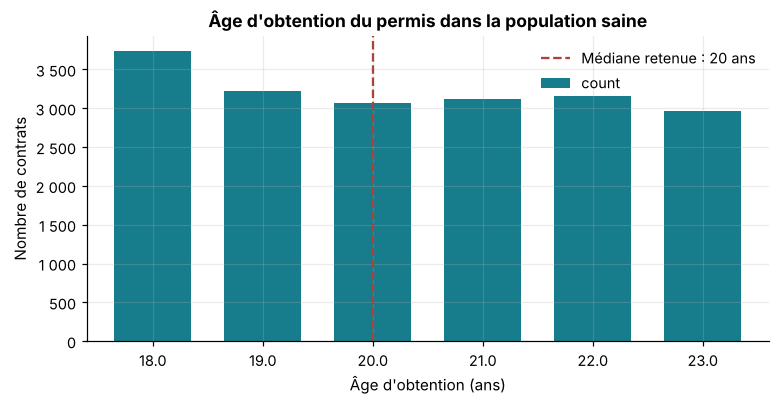


Ecart-type = 1,73 an(s).
-> La dispersion est faible : la relation est assez resserree pour reconstruire
   un age a environ 2 ans pres, ce qui est negligeable devant des tranches
   tarifaires de 5 a 10 ans.


In [18]:
titre("AGE D'OBTENTION DU PERMIS — mesure sur la population saine", 2)
pop_saine = contrats_brut[
    contrats_brut["age_conducteur"].between(AGE_MIN, AGE_MAX)
    & contrats_brut["anciennete_permis"].notna()
].copy()
pop_saine["age_obtention"] = pop_saine["age_conducteur"] - pop_saine["anciennete_permis"]
pop_saine = pop_saine[pop_saine["age_obtention"].between(15, 60)]

print(f"Effectif de reference : {fr(len(pop_saine))} contrats")
print(pop_saine["age_obtention"].describe().to_string())
print("\nRepartition :")
print(pop_saine["age_obtention"].value_counts().sort_index().to_string())

fig, ax = plt.subplots(figsize=(8, 3.6))
pop_saine["age_obtention"].value_counts().sort_index().plot(
    kind="bar", ax=ax, color=PALETTE["petrole"], width=0.7)
ax.set_title("Âge d'obtention du permis dans la population saine")
ax.set_xlabel("Âge d'obtention (ans)")
ax.set_ylabel("Nombre de contrats")
ax.axvline(x=list(sorted(pop_saine["age_obtention"].unique())).index(AGE_PERMIS_MEDIAN),
           color=PALETTE["brique"], linestyle="--", lw=1.5,
           label=f"Médiane retenue : {AGE_PERMIS_MEDIAN} ans")
ax.legend(frameon=False)
axe_fr(ax)
plt.xticks(rotation=0)
sauver_fig("1_6_age_obtention_permis")

ecart_type_obt = pop_saine["age_obtention"].std()
print(f"\nEcart-type = {fr(ecart_type_obt, 2)} an(s).")
print("-> La dispersion est faible : la relation est assez resserree pour reconstruire")
print("   un age a environ 2 ans pres, ce qui est negligeable devant des tranches")
print("   tarifaires de 5 a 10 ans.")

**Back-test de la règle.** Une règle d'imputation doit être mesurée, pas postulée.
On l'applique donc à des lignes dont l'âge est connu et correct, puis on compare
l'âge reconstruit à l'âge réel.

In [19]:
titre("BACK-TEST DE LA REGLE DE RECONSTRUCTION", 2)
age_reconstruit_test = pop_saine["anciennete_permis"] + AGE_PERMIS_MEDIAN
erreur = (age_reconstruit_test - pop_saine["age_conducteur"]).abs()

print(f"Regle testee : age = anciennete_permis + {AGE_PERMIS_MEDIAN}")
print(f"Erreur absolue moyenne   : {fr(erreur.mean(), 2)} an(s)")
print(f"Erreur absolue mediane   : {fr(erreur.median(), 2)} an(s)")
print(f"Erreur <= 2 ans          : {pct((erreur <= 2).mean())} des cas")
print(f"Erreur <= 3 ans          : {pct((erreur <= 3).mean())} des cas")

# Impact reel : la reconstruction change-t-elle la tranche tarifaire ?
BORNES_AGE = [17, 25, 30, 40, 50, 60, 70, 95]
tr_reelle = pd.cut(pop_saine["age_conducteur"], BORNES_AGE)
tr_reconstr = pd.cut(age_reconstruit_test.clip(AGE_MIN, AGE_MAX), BORNES_AGE)
print(f"\nMeme tranche tarifaire apres reconstruction : "
      f"{pct((tr_reelle.astype(str) == tr_reconstr.astype(str)).mean())} des cas")
print("-> C'est le critere qui compte reellement : le tarif est etabli par tranche,")
print("   pas a l'annee pres.")


------------------------------------------------------------------------------
BACK-TEST DE LA REGLE DE RECONSTRUCTION
------------------------------------------------------------------------------
Regle testee : age = anciennete_permis + 20
Erreur absolue moyenne   : 1,51 an(s)
Erreur absolue mediane   : 2,00 an(s)
Erreur <= 2 ans          : 84,6 % des cas
Erreur <= 3 ans          : 100,0 % des cas

Meme tranche tarifaire apres reconstruction : 84,4 % des cas
-> C'est le critere qui compte reellement : le tarif est etabli par tranche,
   pas a l'annee pres.


### 1.6.3 La puissance fiscale est-elle reconstructible ?

Même démarche pour la puissance fiscale : existe-t-il une variable auxiliaire
permettant de la reconstruire ? Le candidat naturel est la classe de véhicule.

In [20]:
titre("PUISSANCE FISCALE — recherche d'un recoupement", 2)
pf_saine = contrats_brut[contrats_brut["puissance_fiscale"].between(PUISS_MIN, PUISS_MAX)]
tab_pf = pf_saine.groupby(pf_saine["classe_vehicule"].str.strip())["puissance_fiscale"].agg(
    Effectif="count", Mediane="median", Moyenne="mean", Ecart_type="std")
display(tab_pf.round(2))
print("-> La puissance mediane vaut 7 CV dans LES CINQ classes de vehicule.")
print("   La classe n'apporte aucune information sur la puissance : aucun recoupement")
print("   n'est possible. La puissance sera donc imputee par la mediane globale,")
print("   traitement assume comme moins satisfaisant mais sans alternative.")


------------------------------------------------------------------------------
PUISSANCE FISCALE — recherche d'un recoupement
------------------------------------------------------------------------------


,Effectif,Mediane,Moyenne,Ecart_type
classe_vehicule,,,,
Berline,4912,7.000,7.630,2.260
Citadine,7101,7.000,7.570,2.220
SUV,4367,7.000,7.520,2.230
Sportive,934,7.000,7.450,2.230
Utilitaire,2746,7.000,7.570,2.190


-> La puissance mediane vaut 7 CV dans LES CINQ classes de vehicule.
   La classe n'apporte aucune information sur la puissance : aucun recoupement
   n'est possible. La puissance sera donc imputee par la mediane globale,
   traitement assume comme moins satisfaisant mais sans alternative.


### 1.6.4 Application effective des corrections

Les règles établies ci-dessus sont maintenant appliquées, dans l'ordre :
harmonisation, reconstruction, imputation résiduelle. Chaque correction laisse une
**trace sous forme d'indicatrice**, ce qui permettra de vérifier au §4 que les lignes
corrigées ne se comportent pas différemment des autres.

In [21]:
titre("NETTOYAGE DE LA BASE CONTRATS")

contrats = contrats_brut.drop_duplicates().copy()
print(f"Suppression des doublons : {fr(len(contrats_brut))} -> {fr(len(contrats))} lignes")

# --- a) Harmonisation des variables qualitatives ---
contrats["sexe"] = (contrats["sexe"].astype("object").str.strip().str.upper().str[0]
                    .map({"M": "M", "H": "M", "F": "F"}))
for col in ["usage_vehicule", "classe_vehicule", "carburant"]:
    contrats[col] = contrats[col].astype("object").str.strip().str.title()
contrats["carburant"] = contrats["carburant"].replace({"Electrique": "Électrique"})
contrats["zone_geo"] = contrats["zone_geo"].astype("object").str.strip().str.upper()

print("\nModalites apres harmonisation :")
for col in ["sexe", "usage_vehicule", "classe_vehicule", "carburant", "zone_geo"]:
    mods = sorted(contrats[col].dropna().unique())
    print(f"   {col:<18} : {len(mods)} modalites -> {mods}")

# --- b) Mise en NaN des valeurs impossibles ---
contrats["date_effet"] = pd.to_datetime(contrats["date_effet_contrat"])
n_age_ab = int(((contrats["age_conducteur"] < AGE_MIN)
                | (contrats["age_conducteur"] > AGE_MAX)).sum())
contrats.loc[(contrats["age_conducteur"] < AGE_MIN)
             | (contrats["age_conducteur"] > AGE_MAX), "age_conducteur"] = np.nan
n_bm_ab = int(((contrats["bonus_malus"] < BM_MIN) | (contrats["bonus_malus"] > BM_MAX)).sum())
contrats.loc[(contrats["bonus_malus"] < BM_MIN)
             | (contrats["bonus_malus"] > BM_MAX), "bonus_malus"] = np.nan
n_pf_ab = int(((contrats["puissance_fiscale"] < PUISS_MIN)
               | (contrats["puissance_fiscale"] > PUISS_MAX)).sum())
contrats.loc[(contrats["puissance_fiscale"] < PUISS_MIN)
             | (contrats["puissance_fiscale"] > PUISS_MAX), "puissance_fiscale"] = np.nan
print(f"\nValeurs impossibles neutralisees : age {fr(n_age_ab)}, "
      f"bonus-malus {fr(n_bm_ab)}, puissance {fr(n_pf_ab)}")

# --- c) Reconstruction de l'âge par l'ancienneté du permis ---
a_reconstruire = contrats["age_conducteur"].isna() & contrats["anciennete_permis"].notna()
contrats["flag_age_reconstruit"] = a_reconstruire.astype(int)
contrats.loc[a_reconstruire, "age_conducteur"] = (
    contrats.loc[a_reconstruire, "anciennete_permis"] + AGE_PERMIS_MEDIAN
).clip(AGE_MIN, AGE_MAX)
print(f"\nAges reconstruits par recoupement : {fr(a_reconstruire.sum())}")

# --- d) Reconstruction de l'ancienneté quand elle contredit l'âge ---
anc_fausse = (contrats["age_conducteur"].notna() & contrats["anciennete_permis"].notna()
              & (contrats["anciennete_permis"] > contrats["age_conducteur"] - 18))
contrats["flag_anc_reconstruite"] = anc_fausse.astype(int)
contrats.loc[anc_fausse, "anciennete_permis"] = (
    contrats.loc[anc_fausse, "age_conducteur"] - AGE_PERMIS_MEDIAN).clip(lower=0)
print(f"Anciennetes reconstruites par recoupement : {fr(anc_fausse.sum())}")

# --- e) Imputation du résidu non reconstructible ---
med_age = contrats["age_conducteur"].median()
contrats["flag_age_impute"] = contrats["age_conducteur"].isna().astype(int)
contrats["age_conducteur"] = contrats["age_conducteur"].fillna(med_age)

contrats["flag_anc_imputee"] = contrats["anciennete_permis"].isna().astype(int)
tranche_tmp = pd.cut(contrats["age_conducteur"], BORNES_AGE)
med_anc_par_age = contrats.groupby(tranche_tmp, observed=True)["anciennete_permis"].transform("median")
contrats["anciennete_permis"] = contrats["anciennete_permis"].fillna(med_anc_par_age)
contrats["anciennete_permis"] = contrats["anciennete_permis"].fillna(
    contrats["anciennete_permis"].median())
contrats["anciennete_permis"] = contrats["anciennete_permis"].clip(
    lower=0, upper=(contrats["age_conducteur"] - 18).clip(lower=0))

contrats["flag_bm_impute"] = contrats["bonus_malus"].isna().astype(int)
contrats["bonus_malus"] = contrats["bonus_malus"].fillna(contrats["bonus_malus"].median())

contrats["flag_pf_imputee"] = contrats["puissance_fiscale"].isna().astype(int)
contrats["puissance_fiscale"] = contrats["puissance_fiscale"].fillna(
    contrats["puissance_fiscale"].median())

contrats["zone_geo"] = contrats["zone_geo"].fillna("Non renseignée")
contrats["carburant"] = contrats["carburant"].fillna("Non renseigné")
contrats["sexe"] = contrats["sexe"].fillna("Non renseigné")

print(f"\nImputations residuelles : age {fr(contrats['flag_age_impute'].sum())}, "
      f"anciennete {fr(contrats['flag_anc_imputee'].sum())}, "
      f"bonus-malus {fr(contrats['flag_bm_impute'].sum())}, "
      f"puissance {fr(contrats['flag_pf_imputee'].sum())}")

# --- f) Contrôles de non-régression ---
assert contrats["age_conducteur"].between(AGE_MIN, AGE_MAX).all(), "age hors bornes"
assert (contrats["anciennete_permis"] <= contrats["age_conducteur"] - 18 + 1e-9).all(), \
    "anciennete incoherente avec l'age"
assert contrats["bonus_malus"].between(BM_MIN, BM_MAX).all(), "bonus-malus hors bornes"
assert contrats[["age_conducteur", "anciennete_permis", "bonus_malus",
                 "puissance_fiscale"]].notna().all().all(), "valeurs manquantes residuelles"
print("\n[OK] Controles passes : plus aucune valeur hors bornes, manquante ou incoherente.")


NETTOYAGE DE LA BASE CONTRATS
Suppression des doublons : 20 120 -> 20 000 lignes

Modalites apres harmonisation :
   sexe               : 2 modalites -> ['F', 'M']
   usage_vehicule     : 3 modalites -> ['Mixte', 'Privé', 'Professionnel']
   classe_vehicule    : 5 modalites -> ['Berline', 'Citadine', 'Sportive', 'Suv', 'Utilitaire']
   carburant          : 4 modalites -> ['Diesel', 'Essence', 'Hybride', 'Électrique']
   zone_geo           : 5 modalites -> ['A', 'B', 'C', 'D', 'E']

Valeurs impossibles neutralisees : age 80, bonus-malus 80, puissance 60

Ages reconstruits par recoupement : 474
Anciennetes reconstruites par recoupement : 60

Imputations residuelles : age 6, anciennete 298, bonus-malus 379, puissance 60

[OK] Controles passes : plus aucune valeur hors bornes, manquante ou incoherente.


### 1.6.5 Traitement de l'exposition

L'exposition est la variable la plus sensible de toute la tarification : elle sert
d'**offset** dans le GLM de fréquence et de dénominateur à toutes les fréquences
calculées. Une exposition fausse fausse mécaniquement tout le tarif.

In [22]:
titre("TRAITEMENT DE L'EXPOSITION", 2)
polices_avec_sinistre = set(sinistres_brut["id_police"])

n_sup1 = int((contrats["duree_exposition"] > 1).sum())
contrats["exposition"] = contrats["duree_exposition"].clip(upper=1.0)
print(f"Expositions superieures a 1 ramenees a 1 : {fr(n_sup1)}")

expo_nulle_m = contrats["exposition"] <= 0
avec_sin = expo_nulle_m & contrats["id_police"].isin(polices_avec_sinistre)
sans_sin = expo_nulle_m & ~contrats["id_police"].isin(polices_avec_sinistre)
med_expo = contrats.loc[contrats["exposition"] > 0, "exposition"].median()

contrats["flag_expo_imputee"] = avec_sin.astype(int)
contrats.loc[avec_sin, "exposition"] = med_expo
print(f"Expositions nulles AVEC sinistre, imputees a la mediane ({fr(med_expo, 3)}) : "
      f"{fr(avec_sin.sum())}")
print(f"Expositions nulles SANS sinistre, supprimees                     : "
      f"{fr(sans_sin.sum())}")

contrats = contrats[contrats["exposition"] > 0].copy()
assert (contrats["exposition"] > 0).all() and (contrats["exposition"] <= 1).all()
print(f"\nBase Contrats fiabilisee : {fr(len(contrats))} contrats, "
      f"{fr(contrats['exposition'].sum(), 1)} annees-police d'exposition")


------------------------------------------------------------------------------
TRAITEMENT DE L'EXPOSITION
------------------------------------------------------------------------------
Expositions superieures a 1 ramenees a 1 : 39
Expositions nulles AVEC sinistre, imputees a la mediane (0,577) : 2
Expositions nulles SANS sinistre, supprimees                     : 19

Base Contrats fiabilisee : 19 981 contrats, 11 532,0 annees-police d'exposition


### 1.6.6 Nettoyage de la base Sinistres

Les montants manquants ou inexploitables sont **reconstruits par la médiane de leur
nature de sinistre**. C'est le même principe de recoupement que pour l'âge : la nature
du sinistre sépare très nettement les ordres de grandeur (quelques centaines d'unités
pour un bris de glace, plusieurs dizaines de milliers pour un incendie total), et
constitue donc un prédicteur bien plus pertinent qu'une médiane globale.

In [23]:
titre("NETTOYAGE DE LA BASE SINISTRES")

sinistres = sinistres_brut.drop_duplicates().copy()
print(f"Suppression des doublons : {fr(len(sinistres_brut))} -> {fr(len(sinistres))} lignes")

sinistres["nature_sinistre"] = sinistres["nature_sinistre"].astype("object").str.strip()
sinistres["statut"] = sinistres["statut"].astype("object").str.strip().str.title()
sinistres["date_sin"] = pd.to_datetime(sinistres["date_sinistre"])
sinistres["montant"] = nettoyer_montant(sinistres["montant_sinistre"])

n_hors = int(((sinistres["responsabilite_pct"] < 0)
              | (sinistres["responsabilite_pct"] > 100)).sum())
sinistres["responsabilite_pct"] = sinistres["responsabilite_pct"].clip(0, 100)
print(f"Taux de responsabilite ramenes dans [0 ; 100] : {fr(n_hors)}")

# --- suppression des sinistres orphelins ---
n_av = len(sinistres)
sinistres = sinistres[sinistres["id_police"].isin(set(contrats["id_police"]))].copy()
print(f"Sinistres orphelins ou rattaches a un contrat supprime : {fr(n_av - len(sinistres))}")

# --- reconstruction des montants par la médiane de la nature ---
a_corriger = sinistres["montant"].isna() | (sinistres["montant"] < 0)
sinistres["flag_montant_reconstruit"] = a_corriger.astype(int)
med_par_nature = sinistres.loc[~a_corriger].groupby("nature_sinistre")["montant"].median()
med_globale = sinistres.loc[~a_corriger, "montant"].median()

print(f"\nMontants a reconstruire : {fr(a_corriger.sum())} "
      f"({fr(sinistres['montant'].isna().sum())} manquants, "
      f"{fr((sinistres['montant'] < 0).sum())} negatifs)")
print("\nMediane de reference par nature de sinistre :")
print(med_par_nature.sort_values().map(lambda v: fr(v, 2)).to_string())

sinistres.loc[a_corriger, "montant"] = (
    sinistres.loc[a_corriger, "nature_sinistre"].map(med_par_nature).fillna(med_globale))
assert sinistres["montant"].notna().all() and (sinistres["montant"] >= 0).all()

print(f"\nBase Sinistres fiabilisee : {fr(len(sinistres))} sinistres, "
      f"charge totale {fr(sinistres['montant'].sum())}")
print(f"Sinistres de montant nul conserves (declares sans suite) : "
      f"{fr((sinistres['montant'] == 0).sum())}")


NETTOYAGE DE LA BASE SINISTRES
Suppression des doublons : 1 348 -> 1 335 lignes
Taux de responsabilite ramenes dans [0 ; 100] : 8
Sinistres orphelins ou rattaches a un contrat supprime : 8

Montants a reconstruire : 28 (25 manquants, 3 negatifs)

Mediane de reference par nature de sinistre :
nature_sinistre
Vandalisme                  570,13
Collision mineure           721,81
Bris de glace               752,81
Dégât matériel léger        757,82
Vol partiel                 806,25
Vol total                23 737,02
Corporel grave           27 496,68
Collision majeure        30 764,39
Incendie total           32 459,93
Catastrophe naturelle    37 275,66

Base Sinistres fiabilisee : 1 327 sinistres, charge totale 9 521 346
Sinistres de montant nul conserves (declares sans suite) : 7


## 1.7 Création des variables de tarification

Quatrième exigence du point A. Deux chantiers : le **découpage en tranches** des
variables continues, puis la construction de la **base de tarification** — une ligne
par contrat, portant son exposition et sa sinistralité.

### 1.7.1 Pourquoi découper les variables continues en tranches

Un GLM à lien logarithmique appliqué à une variable continue impose un effet
**monotone et exponentiel** : chaque année d'âge supplémentaire multiplierait le
risque par un facteur constant. Or le risque automobile est notoirement **en U** selon
l'âge — élevé chez les jeunes conducteurs, décroissant, puis remontant chez les
conducteurs âgés. Le découpage en tranches laisse le modèle libre d'estimer un
coefficient propre à chaque tranche, donc de restituer cette forme.

Les bornes sont choisies pour respecter deux contraintes : correspondre aux usages
du marché (seuil des 25 ans, permis de moins de 2 ans) et garantir un **effectif
suffisant dans chaque tranche** pour que les coefficients soient estimables.

In [24]:
BORNES_ANC = [-0.01, 2, 5, 10, 20, 30, 100]
BORNES_BM = [0.49, 0.60, 0.75, 0.90, 1.00, 1.20, 3.51]
BORNES_AGE_VEH = [-0.01, 2, 5, 10, 15, 40]
BORNES_PUISS = [0, 5, 7, 9, 11, 40]

LIB_AGE = ["18-25 ans", "26-30 ans", "31-40 ans", "41-50 ans", "51-60 ans", "61-70 ans", "71 ans et +"]
LIB_ANC = ["0-2 ans", "3-5 ans", "6-10 ans", "11-20 ans", "21-30 ans", "31 ans et +"]
LIB_BM = ["0,50-0,60", "0,61-0,75", "0,76-0,90", "0,91-1,00", "1,01-1,20", "1,21 et +"]
LIB_AGE_VEH = ["0-2 ans", "3-5 ans", "6-10 ans", "11-15 ans", "16 ans et +"]
LIB_PUISS = ["1-5 CV", "6-7 CV", "8-9 CV", "10-11 CV", "12 CV et +"]


def ajouter_tranches(df):
    """Ajoute les variables tarifaires categorielles a une base de contrats."""
    df = df.copy()
    df["tr_age"] = pd.cut(df["age_conducteur"], BORNES_AGE, labels=LIB_AGE)
    df["tr_anciennete"] = pd.cut(df["anciennete_permis"], BORNES_ANC, labels=LIB_ANC)
    df["tr_bonus"] = pd.cut(df["bonus_malus"], BORNES_BM, labels=LIB_BM)
    df["tr_age_vehicule"] = pd.cut(df["age_vehicule"], BORNES_AGE_VEH, labels=LIB_AGE_VEH)
    df["tr_puissance"] = pd.cut(df["puissance_fiscale"], BORNES_PUISS, labels=LIB_PUISS)
    df["jeune_conducteur"] = np.where(
        (df["age_conducteur"] <= 25) | (df["anciennete_permis"] <= 2), "Oui", "Non")
    return df


contrats = ajouter_tranches(contrats)

titre("EFFECTIFS PAR TRANCHE TARIFAIRE", 2)
for col in ["tr_age", "tr_anciennete", "tr_bonus", "tr_age_vehicule", "tr_puissance"]:
    eff = contrats.groupby(col, observed=True)["exposition"].agg(
        Contrats="size", Exposition="sum")
    eff["Part expo"] = (eff["Exposition"] / eff["Exposition"].sum()).map(lambda v: pct(v))
    eff["Exposition"] = eff["Exposition"].map(lambda v: fr(v, 1))
    print(f"\n--- {col} ---")
    print(eff.to_string())


------------------------------------------------------------------------------
EFFECTIFS PAR TRANCHE TARIFAIRE
------------------------------------------------------------------------------

--- tr_age ---
             Contrats Exposition Part expo
tr_age                                    
18-25 ans        2071    1 199,2    10,4 %
26-30 ans        1678      941,6     8,2 %
31-40 ans        5311    3 086,3    26,8 %
41-50 ans        5799    3 345,5    29,0 %
51-60 ans        3499    2 017,9    17,5 %
61-70 ans        1338      770,4     6,7 %
71 ans et +       285      171,1     1,5 %

--- tr_anciennete ---
               Contrats Exposition Part expo
tr_anciennete                               
0-2 ans            1479      860,4     7,5 %
3-5 ans             738      418,3     3,6 %
6-10 ans           1756      999,9     8,7 %
11-20 ans          5383    3 124,0    27,1 %
21-30 ans          5734    3 290,5    28,5 %
31 ans et +        4891    2 838,8    24,6 %

--- tr_bonus ---
     

Tous les effectifs sont largement suffisants : la tranche la moins peuplée dépasse
plusieurs centaines de contrats. Aucun regroupement n'est nécessaire à ce stade.

### 1.7.2 Construction de la base de tarification

On agrège les sinistres au niveau du contrat. Chaque ligne porte alors son exposition,
son nombre de sinistres et sa charge — soit exactement les trois quantités dont la
tarification a besoin.

In [25]:
agg_sin = sinistres.groupby("id_police").agg(
    nb_sinistres=("id_sinistre", "size"),
    charge_totale=("montant", "sum"),
)

base_tarif = contrats.merge(agg_sin, on="id_police", how="left")
base_tarif[["nb_sinistres", "charge_totale"]] = (
    base_tarif[["nb_sinistres", "charge_totale"]].fillna(0))
base_tarif["nb_sinistres"] = base_tarif["nb_sinistres"].astype(int)

titre("BASE DE TARIFICATION")
print(f"Contrats            : {fr(len(base_tarif))}")
print(f"Exposition totale   : {fr(base_tarif['exposition'].sum(), 1)} annees-police")
print(f"Sinistres rattaches : {fr(base_tarif['nb_sinistres'].sum())}")
print(f"Charge totale       : {fr(base_tarif['charge_totale'].sum())}")
print(f"\nFrequence brute     : {fr(base_tarif['nb_sinistres'].sum() / base_tarif['exposition'].sum(), 4)} "
      f"sinistre par annee-police")
print(f"Prime pure brute    : {fr(base_tarif['charge_totale'].sum() / base_tarif['exposition'].sum())} "
      f"par annee-police")

print("\nDistribution du nombre de sinistres par contrat :")
dist_nb = base_tarif["nb_sinistres"].value_counts().sort_index()
print(pd.DataFrame({"Contrats": dist_nb,
                    "Part": (dist_nb / len(base_tarif)).map(lambda v: pct(v, 2))}).to_string())

assert abs(base_tarif["nb_sinistres"].sum() - len(sinistres)) < 1e-9
assert abs(base_tarif["charge_totale"].sum() - sinistres["montant"].sum()) < 1e-6
print("\n[OK] La base de tarification reconcilie exactement avec la base Sinistres.")


BASE DE TARIFICATION
Contrats            : 19 981
Exposition totale   : 11 532,0 annees-police
Sinistres rattaches : 1 327
Charge totale       : 9 521 346

Frequence brute     : 0,1151 sinistre par annee-police
Prime pure brute    : 826 par annee-police

Distribution du nombre de sinistres par contrat :
              Contrats     Part
nb_sinistres                   
0                18709  93,63 %
1                 1219   6,10 %
2                   51   0,26 %
3                    2   0,01 %

[OK] La base de tarification reconcilie exactement avec la base Sinistres.


## 1.8 Journal de fiabilisation

Bilan avant / après. Aucune ligne ne doit disparaître sans être comptée : c'est la
condition pour qu'un tiers puisse auditer le travail.

In [26]:
journal = pd.DataFrame([
    ("Contrats — lignes", len(contrats_brut), len(contrats)),
    ("Contrats — polices distinctes", contrats_brut["id_police"].nunique(),
     contrats["id_police"].nunique()),
    ("Contrats — valeurs manquantes", int(contrats_brut.isna().sum().sum()),
     int(contrats[[c for c in contrats_brut.columns]].isna().sum().sum())),
    ("Exposition totale (années-police)", round(contrats_brut["duree_exposition"].sum(), 1),
     round(contrats["exposition"].sum(), 1)),
    ("Sinistres — lignes", len(sinistres_brut), len(sinistres)),
    ("Sinistres — montants exploitables",
     int(pd.to_numeric(sinistres_brut["montant_sinistre"], errors="coerce").gt(0).sum()),
     int(sinistres["montant"].ge(0).sum())),
    ("Charge totale",
     round(float(nettoyer_montant(sinistres_brut["montant_sinistre"]).clip(lower=0).sum()), 0),
     round(float(sinistres["montant"].sum()), 0)),
], columns=["Indicateur", "Avant fiabilisation", "Après fiabilisation"])
journal["Écart"] = journal["Après fiabilisation"] - journal["Avant fiabilisation"]
exporter_table(journal, "1_8_journal_fiabilisation", index=False)
display(journal)

corrections = pd.DataFrame({
    "Correction": ["Âges reconstruits", "Anciennetés reconstruites", "Âges imputés",
                   "Anciennetés imputées", "Bonus-malus imputés", "Puissances imputées",
                   "Expositions imputées", "Montants reconstruits"],
    "Lignes": [int(contrats["flag_age_reconstruit"].sum()),
               int(contrats["flag_anc_reconstruite"].sum()),
               int(contrats["flag_age_impute"].sum()),
               int(contrats["flag_anc_imputee"].sum()),
               int(contrats["flag_bm_impute"].sum()),
               int(contrats["flag_pf_imputee"].sum()),
               int(contrats["flag_expo_imputee"].sum()),
               int(sinistres["flag_montant_reconstruit"].sum())],
})
corrections["Méthode"] = ["Recoupement", "Recoupement", "Médiane", "Médiane conditionnelle",
                          "Médiane", "Médiane", "Médiane", "Recoupement"]
exporter_table(corrections, "1_8_corrections_appliquees", index=False)
display(corrections)

n_recoup = int(corrections.loc[corrections["Méthode"] == "Recoupement", "Lignes"].sum())
n_imput = int(corrections.loc[corrections["Méthode"] != "Recoupement", "Lignes"].sum())
print(f"\nValeurs restaurees par RECOUPEMENT entre variables : {fr(n_recoup)}")
print(f"Valeurs restaurees par IMPUTATION statistique      : {fr(n_imput)}")
print(f"\n-> {pct(n_recoup / (n_recoup + n_imput))} des corrections s'appuient sur une")
print("   information reellement presente dans la donnee, et non sur une moyenne.")

,Indicateur,Avant fiabilisation,Après fiabilisation,Écart
0,Contrats — lignes,20 120.000,19 981.000,-139.000
1,Contrats — polices distinctes,20 000.000,19 981.000,-19.000
2,Contrats — valeurs manquantes,1 604.000,0.000,-1 604.000
3,Exposition totale (années-police),11 620.500,11 532.000,-88.500
4,Sinistres — lignes,1 348.000,1 327.000,-21.000
5,Sinistres — montants exploitables,1 306.000,1 327.000,21.000
6,Charge totale,9 472 406.000,9 521 346.000,48 940.000


,Correction,Lignes,Méthode
0,Âges reconstruits,473,Recoupement
1,Anciennetés reconstruites,60,Recoupement
2,Âges imputés,6,Médiane
3,Anciennetés imputées,297,Médiane conditionnelle
4,Bonus-malus imputés,378,Médiane
5,Puissances imputées,60,Médiane
6,Expositions imputées,2,Médiane
7,Montants reconstruits,28,Recoupement



Valeurs restaurees par RECOUPEMENT entre variables : 561
Valeurs restaurees par IMPUTATION statistique      : 743

-> 43,0 % des corrections s'appuient sur une
   information reellement presente dans la donnee, et non sur une moyenne.


### Ce qu'il faut retenir de la partie A

- Les deux bases contenaient des anomalies **systématiques et non aléatoires** :
  valeurs injectées sur un petit nombre de codes, variantes d'écriture, doublons
  intégraux, montants stockés en texte. Une exploitation naïve aurait produit un tarif
  faux sans qu'aucun message d'erreur n'apparaisse.
- L'hypothèse la plus intuitive — des fautes de frappe — a été **testée et rejetée**
  sur données (§1.6.1).
- La majorité des corrections s'appuie sur un **recoupement entre variables** plutôt
  que sur une imputation par la moyenne, et la règle de reconstruction a été
  **back-testée** avant d'être appliquée.
- Le portefeuille fiabilisé ne compte **qu'une seule année de souscription**, ce qui
  contraint le dispositif de validation (§5).
- Les sinistres sont **indépendants de la garantie souscrite** : un contrat au tiers
  déclare autant de sinistres qu'un contrat tous risques, y compris des vols et des bris
  de glace qu'il ne couvre pas (§1.4.1). C'est une limite de la source, à signaler.

---
# §2 — Partie B · Les montants de sinistres : une seule population tarifaire

> **Ce que demande l'énoncé (point B)**
> Détermination d'un seuil de gravité, séparation des sinistres en attritionnels et
> graves, justification de la méthode.

**Le parti pris de ce notebook.** Cette variante de l'étude suit l'approche de
tarification la plus classique : **aucun seuil de gravité n'est appliqué**. Tous les
sinistres, petits et grands, sont conservés dans la base et modélisés ensemble — une
fréquence, un coût moyen. Les sinistres importants ne sont ni écartés, ni écrêtés, ni
tarifés à part.

Cette partie ne sépare donc rien. Elle fait ce qui reste indispensable avant de
modéliser un coût moyen : **décrire la distribution des montants**, mesurer à quel
point la charge est concentrée sur quelques sinistres, et chiffrer ce que cela implique
pour la précision du coût moyen. Elle se termine par les deux tests de sensibilité
annoncés dans la partie A.

## 2.1 Forme de la distribution des montants


DISTRIBUTION DES MONTANTS DE SINISTRES
Effectif exploitable : 1 320 sinistres de montant strictement positif
count     1 320.000
mean      7 213.141
std      24 748.529
min          98.150
25%         497.625
50%         849.790
75%       1 579.257
max     429 207.490

Quantiles :
0.500        850
0.750      1 579
0.800      1 933
0.850      3 497
0.900     21 189
0.950     38 556
0.975     62 893
0.990    104 978

Rapport moyenne / mediane : 8,49
Coefficient de variation  : 3,43
Coefficient d'asymetrie   : 8,41
-> Une moyenne tres superieure a la mediane signe une distribution fortement
   asymetrique a droite : quelques sinistres pesent l'essentiel de la charge.


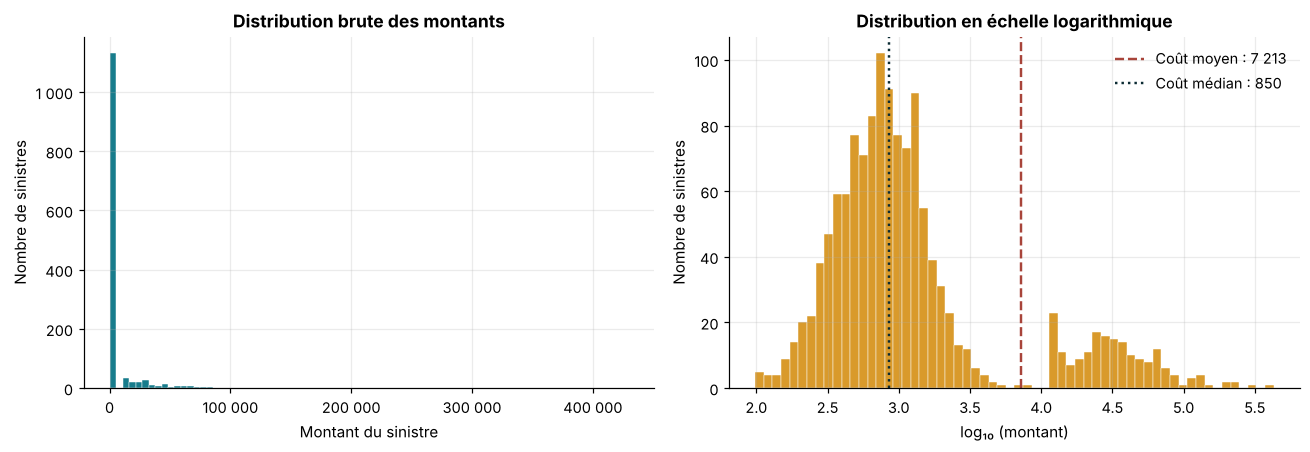

In [27]:
montants = sinistres.loc[sinistres["montant"] > 0, "montant"].copy()
expo_tot = base_tarif["exposition"].sum()

titre("DISTRIBUTION DES MONTANTS DE SINISTRES")
print(f"Effectif exploitable : {fr(len(montants))} sinistres de montant strictement positif")
print(montants.describe().to_string())
print("\nQuantiles :")
q = montants.quantile([.5, .75, .80, .85, .90, .95, .975, .99])
print(q.map(lambda v: fr(v)).to_string())
print(f"\nRapport moyenne / mediane : {fr(montants.mean() / montants.median(), 2)}")
print(f"Coefficient de variation  : {fr(montants.std() / montants.mean(), 2)}")
print(f"Coefficient d'asymetrie   : {fr(stats.skew(montants), 2)}")
print("-> Une moyenne tres superieure a la mediane signe une distribution fortement")
print("   asymetrique a droite : quelques sinistres pesent l'essentiel de la charge.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].hist(montants, bins=80, color=PALETTE["petrole"], edgecolor="white", linewidth=0.3)
axes[0].set_title("Distribution brute des montants")
axes[0].set_xlabel("Montant du sinistre")
axes[0].set_ylabel("Nombre de sinistres")
axe_fr(axes[0]); axe_fr(axes[0], "x")

axes[1].hist(np.log10(montants), bins=60, color=PALETTE["ambre"],
             edgecolor="white", linewidth=0.3)
axes[1].set_title("Distribution en échelle logarithmique")
axes[1].set_xlabel("log₁₀ (montant)")
axes[1].set_ylabel("Nombre de sinistres")
axes[1].axvline(np.log10(montants.mean()), color=PALETTE["brique"], linestyle="--", lw=1.6,
                label=f"Coût moyen : {fr(montants.mean())}")
axes[1].axvline(np.log10(montants.median()), color=PALETTE["encre"], linestyle=":", lw=1.6,
                label=f"Coût médian : {fr(montants.median())}")
axes[1].legend(frameon=False)
axe_fr(axes[1])
plt.tight_layout()
sauver_fig("2_1_distribution_montants")

**Lecture.** En échelle logarithmique, la distribution présente deux bosses : une masse
de sinistres courants autour de quelques centaines d'unités, et un groupe de sinistres
beaucoup plus lourds. Le coût moyen tombe dans le creux entre les deux : **il ne
ressemble à aucun sinistre réellement observé**. C'est la première chose à garder en
tête quand on tarifie tous les sinistres ensemble.

## 2.2 Concentration de la charge et précision du coût moyen

On mesure d'abord la part de la charge portée par les sinistres les plus coûteux, puis
l'incertitude qui en résulte sur le coût moyen, par **bootstrap** : on rééchantillonne
les sinistres avec remise un grand nombre de fois et on observe comment le coût moyen
varie d'un tirage à l'autre.

In [28]:
titre("CONCENTRATION DE LA CHARGE", 2)
tries = np.sort(montants.values)[::-1]
lignes_conc = []
for part in [0.01, 0.05, 0.10, 0.25, 0.50]:
    k = int(round(part * len(tries)))
    lignes_conc.append({
        "Sinistres les plus coûteux": f"les {pct(part, 0)} ({fr(k)} sinistres)",
        "Montant minimum du groupe": fr(tries[k - 1]),
        "Part de la charge totale": pct(tries[:k].sum() / tries.sum()),
    })
tab_conc = pd.DataFrame(lignes_conc)
exporter_table(tab_conc, "2_2_concentration_charge", index=False)
display(tab_conc)

titre("PRECISION DU COUT MOYEN (bootstrap, 2 000 tirages)", 2)
gen = np.random.default_rng(GRAINE)
y_m = montants.values
tirages = gen.integers(0, len(y_m), (2000, len(y_m)))
moyennes_boot = y_m[tirages].mean(axis=1)
medianes_boot = np.median(y_m[tirages], axis=1)
ic_moy = np.percentile(moyennes_boot, [2.5, 97.5])
ic_med = np.percentile(medianes_boot, [2.5, 97.5])
tab_prec = pd.DataFrame({
    "Indicateur": ["Coût moyen", "Coût médian"],
    "Valeur": [fr(y_m.mean()), fr(np.median(y_m))],
    "IC 95 %": [f"[{fr(ic_moy[0])} ; {fr(ic_moy[1])}]", f"[{fr(ic_med[0])} ; {fr(ic_med[1])}]"],
    "Largeur relative de l'IC": [pct((ic_moy[1] - ic_moy[0]) / y_m.mean()),
                                 pct((ic_med[1] - ic_med[0]) / np.median(y_m))],
})
exporter_table(tab_prec, "2_2_precision_cout_moyen", index=False)
display(tab_prec)

plus_gros = tries[0]
print(f"\nLe plus gros sinistre ({fr(plus_gros)}) represente a lui seul "
      f"{pct(plus_gros / tries.sum())} de la charge.")
print(f"Sans lui, le cout moyen passerait de {fr(y_m.mean())} a "
      f"{fr((tries.sum() - plus_gros) / (len(tries) - 1))}.")


------------------------------------------------------------------------------
CONCENTRATION DE LA CHARGE
------------------------------------------------------------------------------


,Sinistres les plus coûteux,Montant minimum du groupe,Part de la charge totale
0,les 1 % (13 sinistres),114 382,"26,7 %"
1,les 5 % (66 sinistres),39 371,"60,2 %"
2,les 10 % (132 sinistres),21 367,"80,4 %"
3,les 25 % (330 sinistres),1 580,"92,5 %"
4,les 50 % (660 sinistres),850,"96,5 %"



------------------------------------------------------------------------------
PRECISION DU COUT MOYEN (bootstrap, 2 000 tirages)
------------------------------------------------------------------------------


,Indicateur,Valeur,IC 95 %,Largeur relative de l'IC
0,Coût moyen,7 213,[5 964 ; 8 681],"37,7 %"
1,Coût médian,850,[804 ; 903],"11,6 %"



Le plus gros sinistre (429 207) represente a lui seul 4,5 % de la charge.
Sans lui, le cout moyen passerait de 7 213 a 6 893.


**Ce que cela implique pour la suite.** La charge est très concentrée, et le coût moyen
— la grandeur que cette approche place au cœur du tarif — n'est connu qu'avec une marge
d'erreur large, alors que la médiane, elle, est nettement plus précise. Ce n'est pas un défaut du
calcul : c'est la conséquence directe du choix de garder tous les sinistres dans un
même coût moyen. Le niveau global du tarif reste estimable ; en revanche, **découper ce
coût moyen par profil d'assuré divisera encore le nombre de gros sinistres par
cellule**, et la partie D devra vérifier si une telle segmentation tient.

## 2.3 Sensibilité au traitement des sinistres ouverts

Environ un sinistre sur cinq est au statut « Ouvert » : son montant est une **charge
évaluée** (règlements déjà effectués plus provision du gestionnaire), non un coût
définitif. Deux traitements sont possibles.

- **Les conserver** — retenu ici. C'est la pratique actuarielle : la provision est la
  meilleure estimation disponible, et les exclure amputerait la fréquence de 20 %.
- **Les exclure** — plus rigoureux sur le coût, mais il faudrait alors retraiter
  l'exposition en conséquence, faute de quoi la fréquence serait biaisée à la baisse.

On mesure l'écart que ce choix produit sur le tarif.

In [29]:
titre("SENSIBILITE AU TRAITEMENT DES SINISTRES OUVERTS", 2)
print("Repartition par statut :")
print(sinistres["statut"].value_counts(dropna=False).to_string())

comp = sinistres.groupby("statut")["montant"].agg(
    Nombre="count", Coût_moyen="mean", Médiane="median")
display(comp.round(0))

clos = sinistres[sinistres["statut"] == "Clos"]
pp_tous = sinistres["montant"].sum() / expo_tot
pp_clos = clos["montant"].sum() / expo_tot
freq_tous = len(sinistres) / expo_tot
freq_clos = len(clos) / expo_tot

bilan_ouv = pd.DataFrame({
    "Périmètre": ["Tous sinistres (retenu)", "Sinistres clos seulement"],
    "Nombre": [fr(len(sinistres)), fr(len(clos))],
    "Fréquence": [fr(freq_tous, 4), fr(freq_clos, 4)],
    "Coût moyen": [fr(sinistres["montant"].mean()), fr(clos["montant"].mean())],
    "Prime pure": [fr(pp_tous), fr(pp_clos)],
})
exporter_table(bilan_ouv, "2_3_sensibilite_sinistres_ouverts", index=False)
display(bilan_ouv)
print(f"\nEcart de prime pure induit par l'exclusion des sinistres ouverts : "
      f"{pct(pp_clos / pp_tous - 1)}")
print(f"   dont effet FREQUENCE  : {pct(freq_clos / freq_tous - 1)}")
print(f"   dont effet COUT MOYEN : "
      f"{pct(clos['montant'].mean() / sinistres['montant'].mean() - 1)}")
print("\n-> Les deux effets se cumulent. Se limiter aux dossiers clos retirerait un")
print("   cinquieme des sinistres, et un cout moyen plus bas : les dossiers les plus")
print("   lourds sont aussi les plus longs a regler. Le choix de conserver les")
print("   sinistres ouverts est donc confirme.")


------------------------------------------------------------------------------
SENSIBILITE AU TRAITEMENT DES SINISTRES OUVERTS
------------------------------------------------------------------------------
Repartition par statut :
statut
Clos      1048
Ouvert     266
NaN         13


,Nombre,Coût_moyen,Médiane
statut,,,
Clos,1048,5 393.000,806.000
Ouvert,266,14 231.000,1 144.000


,Périmètre,Nombre,Fréquence,Coût moyen,Prime pure
0,Tous sinistres (retenu),1 327,"0,1151",7 175,826
1,Sinistres clos seulement,1 048,"0,0909",5 393,490



Ecart de prime pure induit par l'exclusion des sinistres ouverts : -40,6 %
   dont effet FREQUENCE  : -21,0 %
   dont effet COUT MOYEN : -24,8 %

-> Les deux effets se cumulent. Se limiter aux dossiers clos retirerait un
   cinquieme des sinistres, et un cout moyen plus bas : les dossiers les plus
   lourds sont aussi les plus longs a regler. Le choix de conserver les
   sinistres ouverts est donc confirme.


## 2.4 Sensibilité à l'incohérence des garanties

Le §1.4.1 a montré que des sinistres de dommages propres sont déclarés sur des contrats
au tiers. On mesure ce que deviendrait le tarif si l'on appliquait la grille de
garanties usuelle, en excluant ces sinistres ainsi que les sinistres de responsabilité
civile sans responsabilité de l'assuré sur ces mêmes contrats.

In [30]:
titre("SENSIBILITE : EXCLUSION DES SINISTRES HORS GARANTIE", 2)
sin_gar = sinistres.merge(contrats[["id_police", "type_couverture"]], on="id_police")
hors_gar = ((sin_gar["type_couverture"] == "Tiers")
            & (sin_gar["nature_sinistre"].isin(DOMMAGES_PROPRES)
               | (sin_gar["responsabilite_pct"] == 0)))
print(f"Sinistres exclus : {fr(hors_gar.sum())} ({pct(hors_gar.mean())} du nombre, "
      f"{pct(sin_gar.loc[hors_gar, 'montant'].sum() / sin_gar['montant'].sum())} de la charge)")

expo_cov = contrats.groupby("type_couverture")["exposition"].sum()
avant = sin_gar.groupby("type_couverture").size() / expo_cov
apres = sin_gar[~hors_gar].groupby("type_couverture").size() / expo_cov
pp_avant = sin_gar.groupby("type_couverture")["montant"].sum() / expo_cov
pp_apres = sin_gar[~hors_gar].groupby("type_couverture")["montant"].sum() / expo_cov
sens_gar = pd.DataFrame({
    "Fréquence (base)": avant.map(lambda v: fr(v, 4)),
    "Fréquence (garanties appliquées)": apres.map(lambda v: fr(v, 4)),
    "Prime pure (base)": pp_avant.map(fr),
    "Prime pure (garanties appliquées)": pp_apres.map(fr),
})
exporter_table(sens_gar, "2_4_sensibilite_garanties")
display(sens_gar)

pp_tot_apres = sin_gar.loc[~hors_gar, "montant"].sum() / expo_tot
print(f"\nPrime pure globale : {fr(sin_gar['montant'].sum() / expo_tot)} -> {fr(pp_tot_apres)} "
      f"({pct(pp_tot_apres / (sin_gar['montant'].sum() / expo_tot) - 1)})")
print("\n-> Appliquer la grille de garanties ferait apparaitre un ecart de frequence de")
print(f"   {pct(apres.max() / apres.min() - 1, 0)} entre formules, la ou les donnees brutes n'en")
print("   montrent aucun. La variable type_couverture deviendrait alors tarifante.")
print("   Mais cet ecart serait CREE par notre hypothese sur la grille, non observe")
print("   dans les donnees : c'est pourquoi le scenario de base ne l'applique pas.")


------------------------------------------------------------------------------
SENSIBILITE : EXCLUSION DES SINISTRES HORS GARANTIE
------------------------------------------------------------------------------
Sinistres exclus : 190 (14,3 % du nombre, 12,4 % de la charge)


,Fréquence (base),Fréquence (garanties appliquées),Prime pure (base),Prime pure (garanties appliquées)
type_couverture,,,,
Tiers,"0,1148","0,0491",915,506
Tiers étendu,"0,1162","0,1162",760,760
Tous risques,"0,1145","0,1145",820,820



Prime pure globale : 826 -> 723 (-12,4 %)

-> Appliquer la grille de garanties ferait apparaitre un ecart de frequence de
   137 % entre formules, la ou les donnees brutes n'en
   montrent aucun. La variable type_couverture deviendrait alors tarifante.
   Mais cet ecart serait CREE par notre hypothese sur la grille, non observe
   dans les donnees : c'est pourquoi le scenario de base ne l'applique pas.


### Ce qu'il faut retenir de la partie B

- **Aucun seuil de gravité n'est appliqué** : tous les sinistres restent dans une seule
  population, modélisée par une fréquence et un coût moyen.
- La distribution des montants est très asymétrique et la charge très concentrée : le
  coût moyen est tiré par une minorité de sinistres lourds.
- Conséquence mesurée : le coût moyen global n'est connu qu'avec un intervalle de
  confiance large. C'est le prix de cette approche, à garder en tête dans la partie D.
- Les sinistres ouverts sont conservés ; la grille de garanties, non documentée, n'est
  pas appliquée.

---
# §3 — Partie C · Approche Fréquence × Coût

> **Ce que demande l'énoncé (point C)**
> Calcul de la prime pure selon l'approche :
> `Prime pure = Fréquence des sinistres × Coût moyen des sinistres`

## 3.1 Le principe, et pourquoi il fonctionne

La charge totale d'un contrat est une **somme aléatoire** : un nombre aléatoire `N` de
sinistres, chacun de coût aléatoire `X` :

$$S = \sum_{i=1}^{N} X_i$$

Si les coûts sont indépendants du nombre de sinistres, la formule de Wald donne
directement :

$$\mathbb{E}(S) = \mathbb{E}(N) \times \mathbb{E}(X) = \text{Fréquence} \times \text{Coût moyen}$$

C'est cette décomposition qui donne toute sa valeur à l'approche : elle sépare **deux
questions de nature différente** — « à quelle fréquence ce profil déclare-t-il un
sinistre ? » et « combien coûte un sinistre de ce profil ? » — qui n'obéissent pas aux
mêmes déterminants. Un jeune conducteur peut déclarer beaucoup de petits sinistres,
un conducteur de véhicule puissant peu de sinistres mais très coûteux.

La **fréquence** se calcule toujours par rapport à l'**exposition**, jamais par rapport
au nombre de contrats : un contrat en vigueur trois mois ne peut pas être comparé à un
contrat annuel.

In [31]:
titre("PRIME PURE GLOBALE — APPROCHE FREQUENCE x COUT")

expo_tot = base_tarif["exposition"].sum()
nb_tot = base_tarif["nb_sinistres"].sum()
charge_tot = base_tarif["charge_totale"].sum()

freq_glob = nb_tot / expo_tot
cout_glob = charge_tot / nb_tot
pp_glob = freq_glob * cout_glob

print(f"Exposition totale            : {fr(expo_tot, 1)} annees-police")
print(f"Nombre de sinistres          : {fr(nb_tot)}")
print(f"Charge totale                : {fr(charge_tot)}")
print()
print(f"Frequence    = {fr(nb_tot)} / {fr(expo_tot, 1)}      = {fr(freq_glob, 4)}")
print(f"Cout moyen   = {fr(charge_tot)} / {fr(nb_tot)} = {fr(cout_glob)}")
print(f"PRIME PURE   = {fr(freq_glob, 4)} x {fr(cout_glob)}       = {fr(pp_glob)}")
print()
print(f"Controle direct : charge / exposition = {fr(charge_tot / expo_tot)}")
assert abs(pp_glob - charge_tot / expo_tot) < 1e-6
print("[OK] Les deux voies de calcul coincident exactement, comme le garantit")
print("     la formule de Wald.")


PRIME PURE GLOBALE — APPROCHE FREQUENCE x COUT
Exposition totale            : 11 532,0 annees-police
Nombre de sinistres          : 1 327
Charge totale                : 9 521 346

Frequence    = 1 327 / 11 532,0      = 0,1151
Cout moyen   = 9 521 346 / 1 327 = 7 175
PRIME PURE   = 0,1151 x 7 175       = 826

Controle direct : charge / exposition = 826
[OK] Les deux voies de calcul coincident exactement, comme le garantit
     la formule de Wald.


## 3.2 Incertitude sur la prime pure

La prime pure du portefeuille est une estimation, pas une constante. On mesure sa
précision par bootstrap **sur les contrats** : chaque tirage reconstitue un portefeuille
de même taille, avec ses sinistres, et recalcule fréquence, coût moyen et prime pure.

In [32]:
titre("INCERTITUDE SUR LA PRIME PURE (bootstrap sur les contrats, 1 000 tirages)", 2)
gen = np.random.default_rng(GRAINE)
e_c = base_tarif["exposition"].values
n_c = base_tarif["nb_sinistres"].values
c_c = base_tarif["charge_totale"].values
tirages = gen.integers(0, len(base_tarif), (1000, len(base_tarif)))
expo_b = e_c[tirages].sum(axis=1)
nb_b = n_c[tirages].sum(axis=1)
charge_b = c_c[tirages].sum(axis=1)

def ic95(v):
    return np.percentile(v, [2.5, 97.5])

lignes_inc = []
for lib, val, boot, dec in [("Fréquence", freq_glob, nb_b / expo_b, 4),
                            ("Coût moyen", cout_glob, charge_b / nb_b, 0),
                            ("Prime pure", pp_glob, charge_b / expo_b, 0)]:
    bas, haut = ic95(boot)
    lignes_inc.append({"Grandeur": lib, "Estimation": fr(val, dec),
                       "IC 95 %": f"[{fr(bas, dec)} ; {fr(haut, dec)}]",
                       "Demi-largeur relative": pct((haut - bas) / 2 / val)})
tab_inc = pd.DataFrame(lignes_inc)
exporter_table(tab_inc, "3_2_incertitude_prime_pure", index=False)
display(tab_inc)

print("\n-> La frequence est connue avec precision ; le cout moyen beaucoup moins.")
print("   L'incertitude de la prime pure vient presque entierement du cout moyen,")
print("   c'est-a-dire des quelques sinistres lourds releves au §2.2.")


------------------------------------------------------------------------------
INCERTITUDE SUR LA PRIME PURE (bootstrap sur les contrats, 1 000 tirages)
------------------------------------------------------------------------------


,Grandeur,Estimation,IC 95 %,Demi-largeur relative
0,Fréquence,"0,1151","[0,1092 ; 0,1214]","5,3 %"
1,Coût moyen,7 175,[5 879 ; 8 440],"17,8 %"
2,Prime pure,826,[675 ; 983],"18,7 %"



-> La frequence est connue avec precision ; le cout moyen beaucoup moins.
   L'incertitude de la prime pure vient presque entierement du cout moyen,
   c'est-a-dire des quelques sinistres lourds releves au §2.2.


**Lecture.** La décomposition Fréquence × Coût sépare ici une grandeur stable d'une
grandeur instable. C'est un premier indice sur l'endroit où la segmentation du tarif
pourra s'appuyer sur des données solides — la fréquence — et sur l'endroit où elle
devra rester prudente — le coût.

## 3.3 Analyses univariées

Pour chaque variable tarifaire, on calcule la fréquence, le coût moyen et la prime
pure par modalité. La fréquence relative (rapportée à la moyenne du portefeuille)
donne directement la lecture tarifaire : une valeur de 1,40 signifie « 40 % de
sinistres en plus que la moyenne ».

**Chaque fréquence est accompagnée de son intervalle de confiance à 95 %**, calculé
sous hypothèse de Poisson. Sans cet intervalle, il est impossible de distinguer un
vrai effet tarifaire d'une fluctuation d'échantillonnage — et c'est particulièrement
critique ici, où certaines modalités reposent sur peu de sinistres.

In [33]:
def analyse_univariee(df, col, cible_nb="nb_sinistres", cible_charge="charge_totale"):
    """Calcule frequence, cout moyen et prime pure par modalite, avec IC a 95 % sur la
    frequence (approximation normale de la loi de Poisson)."""
    g = df.groupby(col, observed=True).agg(
        Contrats=("id_police", "size"),
        Exposition=("exposition", "sum"),
        Sinistres=(cible_nb, "sum"),
        Charge=(cible_charge, "sum"),
    )
    g["Fréquence"] = g["Sinistres"] / g["Exposition"]
    freq_ref = df[cible_nb].sum() / df["exposition"].sum()
    g["Fréq. relative"] = g["Fréquence"] / freq_ref
    demi = 1.96 * np.sqrt(g["Sinistres"]) / g["Exposition"]
    g["IC bas"] = (g["Fréquence"] - demi).clip(lower=0)
    g["IC haut"] = g["Fréquence"] + demi
    g["Coût moyen"] = np.where(g["Sinistres"] > 0, g["Charge"] / g["Sinistres"], np.nan)
    g["Prime pure"] = g["Charge"] / g["Exposition"]
    # Significativite : l'IC de la modalite contient-il la frequence moyenne ?
    g["Écart significatif"] = np.where(
        (g["IC haut"] < freq_ref) | (g["IC bas"] > freq_ref), "Oui", "Non")
    return g


def afficher_univariee(g, titre_txt):
    aff = pd.DataFrame({
        "Contrats": g["Contrats"].map(fr),
        "Exposition": g["Exposition"].map(lambda v: fr(v, 1)),
        "Sinistres": g["Sinistres"].map(fr),
        "Fréquence": g["Fréquence"].map(lambda v: fr(v, 4)),
        "IC 95 %": [f"[{fr(b, 4)} ; {fr(h, 4)}]" for b, h in zip(g["IC bas"], g["IC haut"])],
        "Fréq. rel.": g["Fréq. relative"].map(lambda v: fr(v, 2)),
        "Signif.": g["Écart significatif"],
        "Coût moyen": g["Coût moyen"].map(fr),
        "Prime pure": g["Prime pure"].map(fr),
    })
    print(f"\n--- {titre_txt} ---")
    display(aff)
    return aff


VARS_TARIF = ["tr_age", "tr_anciennete", "sexe", "zone_geo", "usage_vehicule",
              "classe_vehicule", "carburant", "type_couverture", "tr_bonus",
              "tr_age_vehicule", "tr_puissance", "jeune_conducteur"]

titre("ANALYSES UNIVARIEES — ENSEMBLE DES SINISTRES")
univariees = {}
for v in VARS_TARIF:
    g = analyse_univariee(base_tarif, v)
    univariees[v] = g
    afficher_univariee(g, v)


ANALYSES UNIVARIEES — ENSEMBLE DES SINISTRES

--- tr_age ---


,Contrats,Exposition,Sinistres,Fréquence,IC 95 %,Fréq. rel.,Signif.,Coût moyen,Prime pure
tr_age,,,,,,,,,
18-25 ans,2 071,"1 199,2",195,"0,1626","[0,1398 ; 0,1854]","1,41",Oui,9 258,1 506
26-30 ans,1 678,"941,6",101,"0,1073","[0,0863 ; 0,1282]","0,93",Non,3 364,361
31-40 ans,5 311,"3 086,3",358,"0,1160","[0,1040 ; 0,1280]","1,01",Non,6 639,770
41-50 ans,5 799,"3 345,5",379,"0,1133","[0,1019 ; 0,1247]","0,98",Non,6 537,741
51-60 ans,3 499,"2 017,9",206,"0,1021","[0,0881 ; 0,1160]","0,89",Non,7 756,792
61-70 ans,1 338,"770,4",71,"0,0922","[0,0707 ; 0,1136]","0,80",Oui,10 712,987
71 ans et +,285,"171,1",17,"0,0994","[0,0521 ; 0,1466]","0,86",Non,9 608,955



--- tr_anciennete ---


,Contrats,Exposition,Sinistres,Fréquence,IC 95 %,Fréq. rel.,Signif.,Coût moyen,Prime pure
tr_anciennete,,,,,,,,,
0-2 ans,1 479,"860,4",146,"0,1697","[0,1422 ; 0,1972]","1,47",Oui,10 820,1 836
3-5 ans,738,"418,3",57,"0,1363","[0,1009 ; 0,1716]","1,18",Non,4 041,551
6-10 ans,1 756,"999,9",109,"0,1090","[0,0885 ; 0,1295]","0,95",Non,5 047,550
11-20 ans,5 383,"3 124,0",361,"0,1156","[0,1036 ; 0,1275]","1,00",Non,6 416,741
21-30 ans,5 734,"3 290,5",370,"0,1124","[0,1010 ; 0,1239]","0,98",Non,6 964,783
31 ans et +,4 891,"2 838,8",284,"0,1000","[0,0884 ; 0,1117]","0,87",Oui,7 986,799



--- sexe ---


,Contrats,Exposition,Sinistres,Fréquence,IC 95 %,Fréq. rel.,Signif.,Coût moyen,Prime pure
sexe,,,,,,,,,
F,8 796,"5 088,5",581,"0,1142","[0,1049 ; 0,1235]","0,99",Non,6 432,734
M,11 185,"6 443,5",746,"0,1158","[0,1075 ; 0,1241]","1,01",Non,7 754,898


... (14 outputs left out)


--- tr_puissance ---


,Contrats,Exposition,Sinistres,Fréquence,IC 95 %,Fréq. rel.,Signif.,Coût moyen,Prime pure
tr_puissance,,,,,,,,,
1-5 CV,3 235,"1 866,1",218,"0,1168","[0,1013 ; 0,1323]","1,02",Non,10 139,1 184
6-7 CV,7 557,"4 377,2",495,"0,1131","[0,1031 ; 0,1230]","0,98",Non,7 145,808
8-9 CV,5 595,"3 222,1",355,"0,1102","[0,0987 ; 0,1216]","0,96",Non,6 077,670
10-11 CV,2 536,"1 466,1",182,"0,1241","[0,1061 ; 0,1422]","1,08",Non,6 890,855
12 CV et +,1 058,"600,4",77,"0,1282","[0,0996 ; 0,1569]","1,11",Non,4 714,604



--- jeune_conducteur ---


,Contrats,Exposition,Sinistres,Fréquence,IC 95 %,Fréq. rel.,Signif.,Coût moyen,Prime pure
jeune_conducteur,,,,,,,,,
Non,17 910,"10 332,8",1 132,"0,1096","[0,1032 ; 0,1159]","0,95",Non,6 816,747
Oui,2 071,"1 199,2",195,"0,1626","[0,1398 ; 0,1854]","1,41",Oui,9 258,1 506


In [34]:
# Synthese : quelles variables discriminent reellement ?
titre("QUELLES VARIABLES DISCRIMINENT LA FREQUENCE ?")
resume = []
for v, g in univariees.items():
    etendue = g["Fréq. relative"].max() - g["Fréq. relative"].min()
    n_signif = int((g["Écart significatif"] == "Oui").sum())
    # Test du chi2 d'homogeneite des frequences entre modalites
    obs = g["Sinistres"].values
    att = g["Exposition"].values * (base_tarif["nb_sinistres"].sum() / expo_tot)
    chi2 = float(((obs - att) ** 2 / att).sum())
    ddl = len(obs) - 1
    pval = 1 - stats.chi2.cdf(chi2, ddl)
    resume.append({
        "Variable": v, "Modalités": len(g),
        "Fréq. rel. min": round(g["Fréq. relative"].min(), 2),
        "Fréq. rel. max": round(g["Fréq. relative"].max(), 2),
        "Étendue": round(etendue, 2),
        "Modalités significatives": n_signif,
        "Chi² (homogénéité)": round(chi2, 1),
        "p-value": f"{pval:.4f}" if pval >= 1e-4 else "< 0,0001",
        "Discriminante ?": "Oui" if pval < 0.05 else "Non",
    })
tab_resume = pd.DataFrame(resume).sort_values("Étendue", ascending=False)
exporter_table(tab_resume, "3_3_pouvoir_discriminant", index=False)
display(tab_resume)

print("\nLecture du test : sous l'hypothese nulle, la frequence est identique dans")
print("toutes les modalites et les ecarts observes ne sont que du bruit. Une p-value")
print("inferieure a 5 % conduit a rejeter cette hypothese.")
print("\n-> Resultats POSITIFS : l'anciennete du permis et l'age du conducteur")
print("   discriminent nettement, la zone geographique egalement.")
print("-> Resultats NEGATIFS, a documenter plutot qu'a taire : le sexe et le type de")
print("   couverture ne discriminent pas. Ils ne seront pas retenus dans le tarif.")
print("   Pour le sexe, c'est d'ailleurs conforme au droit europeen, qui interdit")
print("   depuis 2012 de l'utiliser comme variable tarifaire en assurance.")


QUELLES VARIABLES DISCRIMINENT LA FREQUENCE ?


,Variable,Modalités,Fréq. rel. min,Fréq. rel. max,Étendue,Modalités significatives,Chi² (homogénéité),p-value,Discriminante ?
0,tr_age,7,0.800,1.410,0.610,2,31.000,"< 0,0001",Oui
1,tr_anciennete,6,0.870,1.470,0.610,2,30.000,"< 0,0001",Oui
11,jeune_conducteur,2,0.950,1.410,0.460,1,26.300,"< 0,0001",Oui
3,zone_geo,6,0.850,1.160,0.310,3,19.300,0.0017,Oui
9,tr_age_vehicule,5,0.850,1.090,0.240,0,7.100,0.1308,Non
6,carburant,5,0.850,1.100,0.240,0,4.300,0.3677,Non
5,classe_vehicule,5,0.950,1.120,0.170,0,2.400,0.6672,Non
8,tr_bonus,6,0.920,1.080,0.160,0,3.300,0.6496,Non
10,tr_puissance,5,0.960,1.110,0.160,0,2.800,0.5881,Non
4,usage_vehicule,3,0.970,1.040,0.070,0,0.600,0.7539,Non



Lecture du test : sous l'hypothese nulle, la frequence est identique dans
toutes les modalites et les ecarts observes ne sont que du bruit. Une p-value
inferieure a 5 % conduit a rejeter cette hypothese.

-> Resultats POSITIFS : l'anciennete du permis et l'age du conducteur
   discriminent nettement, la zone geographique egalement.
-> Resultats NEGATIFS, a documenter plutot qu'a taire : le sexe et le type de
   couverture ne discriminent pas. Ils ne seront pas retenus dans le tarif.
   Pour le sexe, c'est d'ailleurs conforme au droit europeen, qui interdit
   depuis 2012 de l'utiliser comme variable tarifaire en assurance.


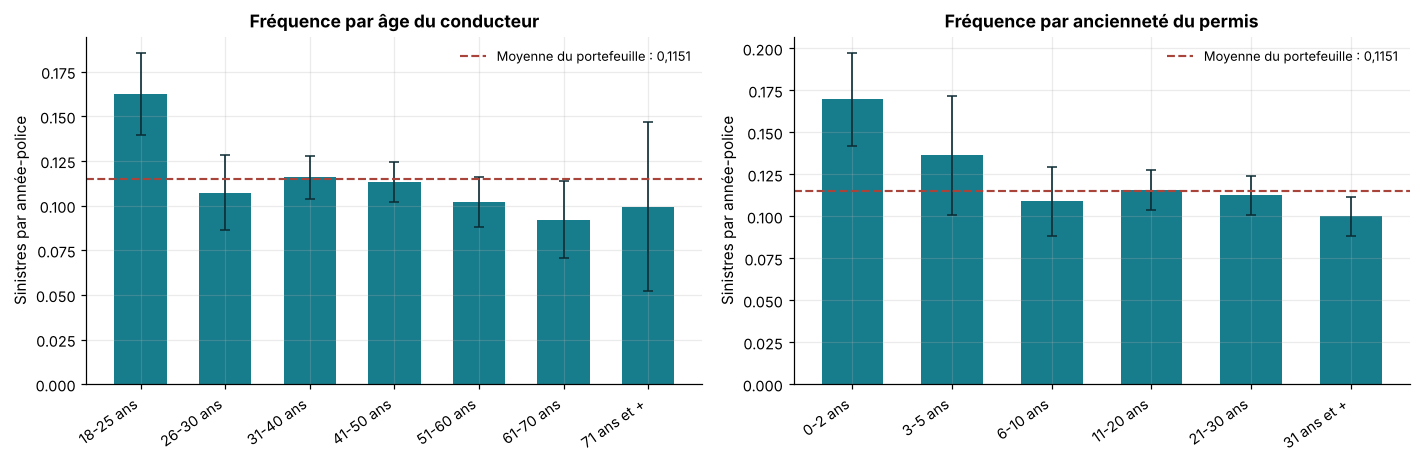

In [35]:
# Visualisation des deux variables les plus discriminantes
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for ax, v, lib in zip(axes, ["tr_age", "tr_anciennete"],
                      ["Âge du conducteur", "Ancienneté du permis"]):
    g = univariees[v]
    x = np.arange(len(g))
    ax.bar(x, g["Fréquence"], color=PALETTE["petrole"], width=0.62)
    ax.errorbar(x, g["Fréquence"], yerr=1.96 * np.sqrt(g["Sinistres"]) / g["Exposition"],
                fmt="none", ecolor=PALETTE["encre"], capsize=3, lw=1.1)
    ax.axhline(freq_glob, color=PALETTE["brique"], linestyle="--", lw=1.4,
               label=f"Moyenne du portefeuille : {fr(freq_glob, 4)}")
    ax.set_xticks(x)
    ax.set_xticklabels(g.index, rotation=35, ha="right")
    ax.set_title(f"Fréquence par {lib.lower()}")
    ax.set_ylabel("Sinistres par année-police")
    ax.legend(frameon=False, fontsize=8.5)
plt.tight_layout()
sauver_fig("3_3_frequence_age_anciennete")

**Les barres d'erreur changent la lecture.** Seule la première tranche se détache
franchement : pour l'âge, les 18-25 ans ; pour l'ancienneté, les permis de moins de
deux ans. Les autres tranches ont des intervalles de confiance qui se recouvrent
largement et se confondent avec la moyenne du portefeuille. Autrement dit, **le risque
n'est pas graduel : il est binaire — conducteur novice ou non.** C'est une information
tarifaire directement exploitable, et elle justifie la variable `jeune_conducteur`.

## 3.4 Analyse croisée et effets confondus

Les analyses univariées ont une limite majeure : elles sont **marginales**. Quand on
observe que les 18-25 ans ont une surfréquence de 40 %, on ne sait pas si c'est un
effet de l'âge ou du fait qu'ils ont, par construction, un permis récent. Les deux
variables sont largement redondantes.

In [36]:
titre("CROISEMENT AGE x ANCIENNETE DU PERMIS", 2)
croise = base_tarif.pivot_table(index="tr_age", columns="tr_anciennete",
                                values="nb_sinistres", aggfunc="sum", observed=True)
expo_croise = base_tarif.pivot_table(index="tr_age", columns="tr_anciennete",
                                     values="exposition", aggfunc="sum", observed=True)
freq_croise = (croise / expo_croise)
print("Frequence par croisement (cellules de moins de 100 annees-police masquees) :")
display((freq_croise.where(expo_croise >= 100)).round(3))
print("\nExposition correspondante :")
display(expo_croise.round(0))

corr = base_tarif[["age_conducteur", "anciennete_permis"]].corr().iloc[0, 1]
print(f"\nCorrelation lineaire entre age et anciennete du permis : {fr(corr, 3)}")
print("-> Correlation tres forte : les deux variables portent largement la MEME")
print("   information. Les introduire ensemble dans un GLM produira des coefficients")
print("   instables et non significatifs, alors meme que chacune prise isolement est")
print("   clairement discriminante. C'est le probleme de la COLINEARITE, arbitre au §4.2.")


------------------------------------------------------------------------------
CROISEMENT AGE x ANCIENNETE DU PERMIS
------------------------------------------------------------------------------
Frequence par croisement (cellules de moins de 100 annees-police masquees) :


tr_anciennete,0-2 ans,3-5 ans,6-10 ans,11-20 ans,21-30 ans,31 ans et +
tr_age,,,,,,
18-25 ans,0.170,0.142,NaN,NaN,NaN,NaN
26-30 ans,NaN,0.127,0.102,0.113,NaN,NaN
31-40 ans,NaN,NaN,0.115,0.116,0.111,NaN
41-50 ans,NaN,NaN,NaN,0.110,0.115,0.097
51-60 ans,NaN,NaN,NaN,NaN,0.090,0.104
61-70 ans,NaN,NaN,NaN,NaN,NaN,0.092
71 ans et +,NaN,NaN,NaN,NaN,NaN,0.099



Exposition correspondante :


tr_anciennete,0-2 ans,3-5 ans,6-10 ans,11-20 ans,21-30 ans,31 ans et +
tr_age,,,,,,
18-25 ans,860.000,260.000,78.000,NaN,NaN,NaN
26-30 ans,NaN,158.000,677.000,106.000,NaN,NaN
31-40 ans,NaN,NaN,244.000,2 671.000,171.000,NaN
41-50 ans,NaN,NaN,NaN,347.000,2 864.000,134.000
51-60 ans,NaN,NaN,NaN,NaN,255.000,1 763.000
61-70 ans,NaN,NaN,NaN,NaN,NaN,770.000
71 ans et +,NaN,NaN,NaN,NaN,NaN,171.000



Correlation lineaire entre age et anciennete du permis : 0,991
-> Correlation tres forte : les deux variables portent largement la MEME
   information. Les introduire ensemble dans un GLM produira des coefficients
   instables et non significatifs, alors meme que chacune prise isolement est
   clairement discriminante. C'est le probleme de la COLINEARITE, arbitre au §4.2.


## 3.5 Limites de l'approche marginale

Les analyses univariées de cette partie donnent une première lecture du risque, mais
elles ne peuvent pas servir de tarif, pour trois raisons :

1. **Elles confondent les effets.** La surfréquence observée sur les 18-25 ans mélange
   l'effet de l'âge, celui de l'ancienneté du permis et celui de la structure du
   portefeuille sur les autres variables.
2. **Elles ne permettent pas de combiner les critères.** Un tarif doit fournir une
   prime pour un profil complet — jeune conducteur, zone C, véhicule puissant — et non
   une prime par critère isolé. Multiplier les coefficients univariés reviendrait à
   compter plusieurs fois le même effet.
3. **Elles ne quantifient pas l'incertitude de façon exploitable.** Les intervalles de
   confiance calculés ici sont marginaux, sans contrôle des autres variables.

Le **modèle linéaire généralisé** répond exactement à ces trois limites : il estime
l'effet propre de chaque variable **à autres caractéristiques égales**, fournit une
prime multiplicative pour tout profil, et livre la significativité de chaque
coefficient. C'est l'objet du §4.

---
# §4 — Partie D · Modélisation par GLM

> **Ce que demande l'énoncé (point D)**
> Mettre en place un ou plusieurs GLM pour modéliser la fréquence et le coût moyen, en
> précisant pour chacun : la variable cible, les variables explicatives, la loi, la
> fonction de lien, et les critères de sélection et de validation.

Dans cette variante, **deux modèles suffisent** : un GLM de fréquence et un GLM de coût
moyen, tous deux estimés sur **l'ensemble des sinistres**. Il n'y a pas de modèle
spécifique aux sinistres graves.

**Organisation.** Cette partie spécifie les modèles — choix de la loi, sélection des
variables, lecture des coefficients — sur le portefeuille complet. La partie E
réestime ensuite ces mêmes modèles sur un échantillon d'apprentissage et les confronte
à un échantillon de test, et vérifie que la sélection de variables faite ici se
retrouve sur l'apprentissage seul.

## 4.1 Le cadre

Un **modèle linéaire généralisé** étend la régression linéaire sur trois points :

1. **Une loi de la famille exponentielle**, choisie selon la nature de la cible :
   Poisson ou binomiale négative pour un comptage, Gamma ou log-normale pour un
   montant positif et asymétrique.
2. **Une fonction de lien** `g` reliant l'espérance au prédicteur linéaire :
   `g(E[Y]) = β₀ + β₁x₁ + … + βₚxₚ`. Le **lien logarithmique** est celui de la
   tarification, pour une raison pratique décisive : il rend le tarif
   **multiplicatif**. En effet `E[Y] = exp(β₀) × exp(β₁x₁) × … `, si bien que chaque
   coefficient s'interprète directement comme un **coefficient tarifaire**
   `exp(βⱼ)` appliqué à une prime de base.
3. **Un offset**, terme du prédicteur linéaire dont le coefficient est fixé à 1.

### Pourquoi l'exposition est un offset et non une variable explicative

Un contrat exposé six mois a, toutes choses égales par ailleurs, exactement **deux fois
moins** de chances de déclarer un sinistre qu'un contrat exposé douze mois. Ce n'est
pas une hypothèse à estimer : c'est une propriété du processus de comptage.

En posant `N ~ Poisson(λ)` avec `λ = exposition × exp(Xβ)`, on obtient :

$$\log(\lambda) = \log(\text{exposition}) + X\beta$$

Le terme `log(exposition)` entre donc dans le modèle avec un coefficient **imposé à 1**.
C'est cette contrainte que réalise l'offset.

## 4.2 GLM de fréquence

| Élément | Choix |
|---|---|
| **Variable cible** | `nb_sinistres` — nombre de sinistres du contrat, tous montants confondus |
| **Loi** | Poisson (à vérifier : test de surdispersion ci-dessous) |
| **Fonction de lien** | Logarithmique |
| **Offset** | `log(exposition)` |
| **Données** | Portefeuille complet (19 981 contrats) |

### 4.2.1 La loi de Poisson est-elle adaptée ? Test de surdispersion

La loi de Poisson impose une contrainte forte : **variance = espérance**. En pratique,
les portefeuilles réels présentent souvent une variance supérieure — de la
*surdispersion* — parce que des facteurs de risque non observés subsistent. On teste
donc cette hypothèse avant de l'adopter.

In [37]:
titre("TEST DE SURDISPERSION")

moy = base_tarif["nb_sinistres"].mean()
var = base_tarif["nb_sinistres"].var()
print(f"Moyenne du nombre de sinistres  : {fr(moy, 5)}")
print(f"Variance du nombre de sinistres : {fr(var, 5)}")
print(f"Rapport variance / moyenne      : {fr(var / moy, 3)}")
print("\n-> Un rapport proche de 1 est compatible avec la loi de Poisson.")
print("   Un rapport nettement superieur a 1 signalerait une surdispersion.")


TEST DE SURDISPERSION
Moyenne du nombre de sinistres  : 0,06641
Variance du nombre de sinistres : 0,06771
Rapport variance / moyenne      : 1,020

-> Un rapport proche de 1 est compatible avec la loi de Poisson.
   Un rapport nettement superieur a 1 signalerait une surdispersion.


### 4.2.2 Arbitrage de la colinéarité âge / ancienneté du permis

Le §3.4 a montré que ces deux variables sont très fortement corrélées. Introduites
ensemble, elles se neutralisent mutuellement. Quatre spécifications sont donc mises en
concurrence, départagées par l'AIC — critère qui pénalise la complexité du modèle et
évite de retenir des variables qui n'améliorent l'ajustement que par surapprentissage.

In [38]:
def formule_glm(cible, variables):
    """Ecrit la formule d'un modele dont toutes les variables sont categorielles."""
    return f"{cible} ~ " + (" + ".join(f"C({v})" for v in variables) if variables else "1")


def ajuster_frequence(df, variables, cible="nb_sinistres", famille=None):
    """Ajuste un GLM de frequence avec offset log(exposition)."""
    famille = famille or families.Poisson(links.Log())
    formule = formule_glm(cible, variables)
    return smf.glm(formule, data=df, family=famille,
                   offset=np.log(df["exposition"])).fit(), formule


titre("ARBITRAGE DE LA COLINEARITE AGE / ANCIENNETE", 2)
AUTRES = ["zone_geo", "carburant", "classe_vehicule", "tr_bonus", "tr_age_vehicule",
          "tr_puissance", "usage_vehicule"]

specifications = {
    "Âge seul": ["tr_age"] + AUTRES,
    "Ancienneté seule": ["tr_anciennete"] + AUTRES,
    "Les deux": ["tr_age", "tr_anciennete"] + AUTRES,
    "Indicatrice jeune conducteur": ["jeune_conducteur"] + AUTRES,
}

res_spec = []
modeles_spec = {}
for nom, vars_ in specifications.items():
    m, f = ajuster_frequence(base_tarif, vars_)
    modeles_spec[nom] = m
    res_spec.append({"Spécification": nom, "Paramètres": int(m.df_model) + 1,
                     "Log-vraisemblance": round(m.llf, 1),
                     "AIC": round(m.aic, 1), "BIC": round(m.bic_llf, 1),
                     "Déviance": round(m.deviance, 1)})
tab_spec = pd.DataFrame(res_spec).sort_values("AIC")
exporter_table(tab_spec, "4_2_arbitrage_colinearite", index=False)
display(tab_spec)

meilleure = tab_spec.iloc[0]["Spécification"]
print(f"\nSpecification retenue par l'AIC : « {meilleure} »")

# Test du rapport de vraisemblance : ajouter la seconde variable apporte-t-il quelque chose ?
m_age = modeles_spec["Âge seul"]
m_deux = modeles_spec["Les deux"]
lr = 2 * (m_deux.llf - m_age.llf)
ddl = int(m_deux.df_model - m_age.df_model)
p_lr = 1 - stats.chi2.cdf(lr, ddl)
print(f"\nTest du rapport de vraisemblance — ajout de l'anciennete au modele avec age :")
print(f"   statistique = {lr:.2f}, ddl = {ddl}, p-value = {p_lr:.4f}")
print(f"   -> {'apport significatif' if p_lr < 0.05 else 'AUCUN apport significatif'}")
print("\n-> Conclusion : les deux variables portent la meme information. En retenir une")
print("   seule suffit, et evite des coefficients instables.")


------------------------------------------------------------------------------
ARBITRAGE DE LA COLINEARITE AGE / ANCIENNETE
------------------------------------------------------------------------------


,Spécification,Paramètres,Log-vraisemblance,AIC,BIC,Déviance
3,Indicatrice jeune conducteur,30,-4 799.800,9 659.600,9 896.700,7 022.400
1,Ancienneté seule,34,-4 798.000,9 664.100,9 932.800,7 018.800
0,Âge seul,35,-4 797.300,9 664.700,9 941.300,7 017.400
2,Les deux,40,-4 796.700,9 673.500,9 989.600,7 016.200



Specification retenue par l'AIC : « Indicatrice jeune conducteur »

Test du rapport de vraisemblance — ajout de l'anciennete au modele avec age :
   statistique = 1.21, ddl = 5, p-value = 0.9443
   -> AUCUN apport significatif

-> Conclusion : les deux variables portent la meme information. En retenir une
   seule suffit, et evite des coefficients instables.


### 4.2.3 Sélection des variables par élimination descendante

On part du modèle complet et on retire, une à une, la variable dont la suppression
améliore le plus l'AIC. La procédure s'arrête quand aucune suppression ne l'améliore
plus. Ce critère intègre automatiquement l'arbitrage entre qualité d'ajustement et
parcimonie.

In [39]:
def selection_descendante(ajuste, variables, verbeux=True):
    """Elimination descendante guidee par l'AIC.

    `ajuste(variables)` doit renvoyer le couple (modele, AIC). A chaque etape, on essaie
    de retirer chaque variable encore presente et on conserve la suppression qui abaisse
    le plus l'AIC. On s'arrete quand aucune n'ameliore plus.
    """
    retenues = list(variables)
    modele, aic = ajuste(retenues)
    historique = [{"Étape": 0, "Variable retirée": "—",
                   "Variables restantes": len(retenues), "AIC": round(aic, 1)}]
    etape = 0
    while retenues:
        candidat, meilleur_aic, meilleur_modele = None, aic, None
        for v in retenues:
            m2, a2 = ajuste([x for x in retenues if x != v])
            if a2 < meilleur_aic - 1e-9:
                candidat, meilleur_aic, meilleur_modele = v, a2, m2
        if candidat is None:
            break
        etape += 1
        retenues.remove(candidat)
        modele, aic = meilleur_modele, meilleur_aic
        historique.append({"Étape": etape, "Variable retirée": candidat,
                           "Variables restantes": len(retenues), "AIC": round(aic, 1)})
    if verbeux:
        display(pd.DataFrame(historique))
    return modele, retenues


def ajusteur_frequence(df, cible="nb_sinistres"):
    """Fabrique la fonction d'ajustement utilisee par la selection, pour une base donnee."""
    def ajuste(vars_):
        m, _ = ajuster_frequence(df, vars_, cible)
        return m, m.aic
    return ajuste


titre("SELECTION DESCENDANTE — GLM DE FREQUENCE")
vars_depart = specifications[meilleure]
print(f"Variables de depart ({len(vars_depart)}) : {vars_depart}\n")
glm_freq, vars_freq = selection_descendante(ajusteur_frequence(base_tarif), vars_depart)
formule_freq = formule_glm("nb_sinistres", vars_freq)

print(f"\nVariables RETENUES  : {vars_freq}")
print(f"Variables ECARTEES  : {[v for v in vars_depart if v not in vars_freq]}")
print(f"\nFormule finale : {formule_freq}")
print(f"AIC = {glm_freq.aic:.1f}   Deviance = {glm_freq.deviance:.1f}   "
      f"ddl residuels = {int(glm_freq.df_resid)}")


SELECTION DESCENDANTE — GLM DE FREQUENCE
Variables de depart (8) : ['jeune_conducteur', 'zone_geo', 'carburant', 'classe_vehicule', 'tr_bonus', 'tr_age_vehicule', 'tr_puissance', 'usage_vehicule']



,Étape,Variable retirée,Variables restantes,AIC
0,0,—,8,9 659.600
1,1,tr_bonus,7,9 653.000
2,2,classe_vehicule,6,9 647.600
3,3,tr_puissance,5,9 642.500
4,4,carburant,4,9 638.500
5,5,usage_vehicule,3,9 635.100
6,6,tr_age_vehicule,2,9 634.500



Variables RETENUES  : ['jeune_conducteur', 'zone_geo']
Variables ECARTEES  : ['carburant', 'classe_vehicule', 'tr_bonus', 'tr_age_vehicule', 'tr_puissance', 'usage_vehicule']

Formule finale : nb_sinistres ~ C(jeune_conducteur) + C(zone_geo)
AIC = 9634.5   Deviance = 7043.3   ddl residuels = 19974


### 4.2.4 Confirmation du choix de la loi

Maintenant que le modèle est spécifié, on peut tester la surdispersion de façon plus
rigoureuse : sur les **résidus du modèle**, et non sur la distribution brute. On
compare également avec une binomiale négative, loi de référence en cas de
surdispersion.

In [40]:
titre("SURDISPERSION — DIAGNOSTIC SUR LE MODELE AJUSTE", 2)
pearson = float((glm_freq.resid_pearson ** 2).sum())
phi = pearson / glm_freq.df_resid
print(f"Chi2 de Pearson             : {pearson:.1f}")
print(f"Degres de liberte residuels : {int(glm_freq.df_resid)}")
print(f"Parametre de dispersion phi : {phi:.3f}")
print("   (phi = 1 sous Poisson ; phi > 1 indiquerait une surdispersion)")

res_lois = []
for nom, fam in [("Poisson", families.Poisson(links.Log())),
                 ("Binomiale négative (α = 0,5)",
                  families.NegativeBinomial(links.Log(), alpha=0.5)),
                 ("Binomiale négative (α = 1,0)",
                  families.NegativeBinomial(links.Log(), alpha=1.0))]:
    m = smf.glm(formule_freq, data=base_tarif, family=fam,
                offset=np.log(base_tarif["exposition"])).fit()
    res_lois.append({"Loi": nom, "Log-vraisemblance": round(m.llf, 1),
                     "AIC": round(m.aic, 1), "Déviance": round(m.deviance, 1)})
tab_lois = pd.DataFrame(res_lois)
exporter_table(tab_lois, "4_2_comparaison_lois_frequence", index=False)
display(tab_lois)

meilleure_loi_freq = tab_lois.sort_values("AIC").iloc[0]["Loi"]
print(f"\nLoi au plus faible AIC : {meilleure_loi_freq}")
print("-> La binomiale negative n'ameliore pas l'AIC : il n'y a pas de surdispersion a")
print("   corriger. Une fois l'exposition prise en compte par l'offset, la variabilite")
print("   residuelle du nombre de sinistres est celle d'un processus de Poisson.")
print("   La LOI DE POISSON EST RETENUE, non par defaut, mais parce qu'elle a ete testee.")


------------------------------------------------------------------------------
SURDISPERSION — DIAGNOSTIC SUR LE MODELE AJUSTE
------------------------------------------------------------------------------
Chi2 de Pearson             : 19907.6
Degres de liberte residuels : 19974
Parametre de dispersion phi : 0.997
   (phi = 1 sous Poisson ; phi > 1 indiquerait une surdispersion)


,Loi,Log-vraisemblance,AIC,Déviance
0,Poisson,-4 810.300,9 634.500,7 043.300
1,"Binomiale négative (α = 0,5)",-4 814.100,9 642.100,6 483.900
2,"Binomiale négative (α = 1,0)",-4 823.900,9 661.800,6 064.200



Loi au plus faible AIC : Poisson
-> La binomiale negative n'ameliore pas l'AIC : il n'y a pas de surdispersion a
   corriger. Une fois l'exposition prise en compte par l'offset, la variabilite
   residuelle du nombre de sinistres est celle d'un processus de Poisson.
   La LOI DE POISSON EST RETENUE, non par defaut, mais parce qu'elle a ete testee.


### 4.2.5 Coefficients et lecture tarifaire

Avec un lien logarithmique, `exp(βⱼ)` est le **coefficient multiplicatif** appliqué à
la prime de base pour la modalité `j`. Une valeur de 1,35 signifie « 35 % de sinistres
en plus que la modalité de référence, à autres caractéristiques égales ».

In [41]:
def table_coefficients(modele, nom_fichier=None):
    """Met en forme les coefficients d'un GLM en coefficients multiplicatifs."""
    ic = modele.conf_int()
    tab = pd.DataFrame({
        "Coefficient β": modele.params.round(4),
        "Erreur-type": modele.bse.round(4),
        "p-value": modele.pvalues.round(4),
        "Coef. multiplicatif exp(β)": np.exp(modele.params).round(3),
        "IC 95 % bas": np.exp(ic[0]).round(3),
        "IC 95 % haut": np.exp(ic[1]).round(3),
    })
    tab["Significatif à 5 %"] = np.where(tab["p-value"] < 0.05, "Oui", "Non")
    tab.index = [i.replace("C(", "").replace(")[T.", " : ").replace("]", "")
                 for i in tab.index]
    if nom_fichier:
        exporter_table(tab, nom_fichier)
    return tab


titre("COEFFICIENTS DU GLM DE FREQUENCE")
coefs_freq = table_coefficients(glm_freq, "4_2_coefficients_frequence")
display(coefs_freq)

print("\nModalites de reference (coefficient implicitement egal a 1) :")
for v in vars_freq:
    modalites = base_tarif[v].dropna().unique()
    ref = sorted(map(str, modalites))[0] if not hasattr(base_tarif[v], "cat") \
        else str(base_tarif[v].cat.categories[0])
    print(f"   {v:<18} -> {ref}")

n_signif = int((coefs_freq["Significatif à 5 %"] == "Oui").sum())
print(f"\nCoefficients significatifs a 5 % : {n_signif} sur {len(coefs_freq)}")


COEFFICIENTS DU GLM DE FREQUENCE


,Coefficient β,Erreur-type,p-value,Coef. multiplicatif exp(β),IC 95 % bas,IC 95 % haut,Significatif à 5 %
Intercept,-2.333,0.077,0.000,0.097,0.083,0.113,Oui
jeune_conducteur : Oui,0.393,0.078,0.000,1.481,1.272,1.724,Oui
zone_geo : B,0.015,0.101,0.879,1.015,0.834,1.237,Non
zone_geo : C,0.223,0.090,0.013,1.250,1.047,1.492,Oui
zone_geo : D,0.245,0.097,0.011,1.277,1.057,1.543,Oui
zone_geo : E,-0.040,0.108,0.716,0.961,0.777,1.189,Non
zone_geo : Non renseignée,0.282,0.269,0.295,1.326,0.782,2.247,Non



Modalites de reference (coefficient implicitement egal a 1) :
   jeune_conducteur   -> Non
   zone_geo           -> A

Coefficients significatifs a 5 % : 4 sur 7


### 4.2.6 Diagnostics du modèle de fréquence

Le modèle retenu ne comporte que des variables qualitatives : il définit donc un nombre
fini de **classes tarifaires** (une par combinaison de modalités). On compare, classe
par classe, la fréquence prédite à la fréquence observée.

In [42]:
titre("DIAGNOSTIC 1 — CONSERVATION DU NOMBRE DE SINISTRES (equilibre du modele)", 2)
pred_nb = glm_freq.predict(base_tarif, offset=np.log(base_tarif["exposition"]))
print(f"Sinistres predits sur le portefeuille : {fr(pred_nb.sum(), 1)}")
print(f"Sinistres observes                    : {fr(base_tarif['nb_sinistres'].sum())}")
print(f"Ecart                                 : "
      f"{pct(pred_nb.sum() / base_tarif['nb_sinistres'].sum() - 1, 4)}")
print("\n-> Un GLM de Poisson a lien log comportant une constante redonne EXACTEMENT")
print("   le total observe. C'est une propriete mathematique du modele, et donc un")
print("   controle imparable : tout ecart signalerait une erreur de code.")
assert abs(pred_nb.sum() / base_tarif["nb_sinistres"].sum() - 1) < 1e-6


------------------------------------------------------------------------------
DIAGNOSTIC 1 — CONSERVATION DU NOMBRE DE SINISTRES (equilibre du modele)
------------------------------------------------------------------------------
Sinistres predits sur le portefeuille : 1 327,0
Sinistres observes                    : 1 327
Ecart                                 : 0,0000 %

-> Un GLM de Poisson a lien log comportant une constante redonne EXACTEMENT
   le total observe. C'est une propriete mathematique du modele, et donc un
   controle imparable : tout ecart signalerait une erreur de code.



------------------------------------------------------------------------------
DIAGNOSTIC 2 — CALIBRATION PAR CLASSE TARIFAIRE
------------------------------------------------------------------------------


Exposition Sinistres observés Sinistres prédits Fréq. observée Fréq. prédite IC 95 % de l'observé Prédit dans l'IC
jeune_conducteur zone_geo                                                                                                                         
Non              E                 1 540,1                140             143,6         0,0909        0,0932    [0,0765 ; 0,1073]              Oui
                 A                 1 502,8                145             145,7         0,0965        0,0970    [0,0814 ; 0,1135]              Oui
                 B                 2 071,9                203             204,1         0,0980        0,0985    [0,0850 ; 0,1124]              Oui
                 C                 3 122,4                382             378,5         0,1223        0,1212    [0,1104 ; 0,1352]              Oui
                 D                 1 992,7                247             246,9         0,1240        0,1239    [0,1090 ; 0,1404]              Oui
                 Non renseignée      102,9                 15              13,2         0,1458        0,1286    [0,0816 ; 0,2405]              Oui
Oui              E                   191,3                 30              26,4         0,1569        0,1381    [0,1058 ; 0,2239]              Oui
                 A                   168,8                 25              24,3         0,1481        0,1436    [0,0958 ; 0,2186]              Oui
                 B                   219,0                 33              31,9         0,1507        0,1459    [0,1037 ; 0,2116]              Oui
                 C                   364,8                 62              65,5         0,1700        0,1795    [0,1303 ; 0,2179]              Oui
                 D                   246,0                 45              45,1         0,1829        0,1835    [0,1334 ; 0,2448]              Oui
                 Non renseignée        9,3                  0               1,8         0,0000        0,1904    [0,0000 ; 0,3958]              Oui

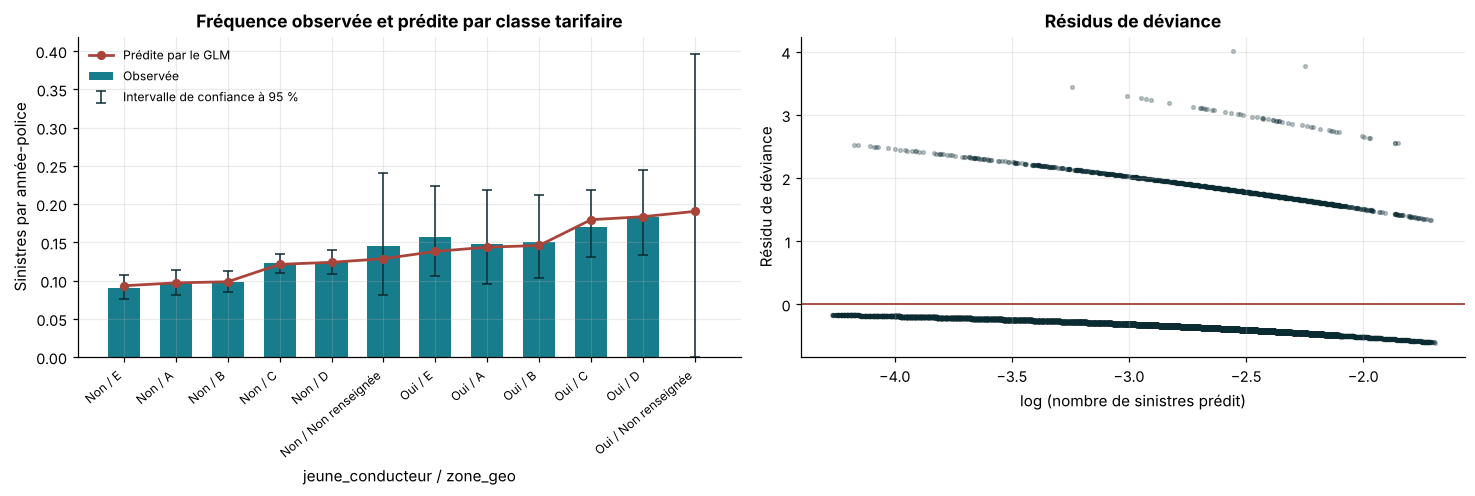


Classes ou la frequence predite est dans l'IC de l'observe : 12 / 12
-> La structure en branches des residus est NORMALE pour une cible de comptage :
   une branche par nombre de sinistres observe (aucun, un, deux...).


In [43]:
titre("DIAGNOSTIC 2 — CALIBRATION PAR CLASSE TARIFAIRE", 2)


def table_classes(df, predictions, variables, cible="nb_sinistres"):
    """Compare le predit et l'observe dans chaque classe tarifaire (combinaison de
    modalites des variables du modele), classees par frequence predite croissante."""
    t = df[variables].astype(str).copy()
    t["pred"] = np.asarray(predictions)
    t["obs"] = df[cible].values
    t["expo"] = df["exposition"].values
    g = t.groupby(variables, observed=True).agg(
        Exposition=("expo", "sum"), Observés=("obs", "sum"), Prédits=("pred", "sum"))
    g["Fréq. observée"] = g["Observés"] / g["Exposition"]
    g["Fréq. prédite"] = g["Prédits"] / g["Exposition"]
    # Intervalle de confiance exact de Poisson : reste valable quand une classe compte
    # tres peu de sinistres, voire aucun
    n_obs = g["Observés"].values.astype(float)
    g["IC bas"] = np.where(n_obs > 0, stats.chi2.ppf(0.025, 2 * np.maximum(n_obs, 1)) / 2, 0.0) / g["Exposition"]
    g["IC haut"] = stats.chi2.ppf(0.975, 2 * (n_obs + 1)) / 2 / g["Exposition"]
    g["Prédit dans l'IC"] = np.where(
        (g["Fréq. prédite"] >= g["IC bas"]) & (g["Fréq. prédite"] <= g["IC haut"]), "Oui", "Non")
    return g.sort_values("Fréq. prédite")


def afficher_classes(g):
    return pd.DataFrame({
        "Exposition": g["Exposition"].map(lambda v: fr(v, 1)),
        "Sinistres observés": g["Observés"].map(fr),
        "Sinistres prédits": g["Prédits"].map(lambda v: fr(v, 1)),
        "Fréq. observée": g["Fréq. observée"].map(lambda v: fr(v, 4)),
        "Fréq. prédite": g["Fréq. prédite"].map(lambda v: fr(v, 4)),
        "IC 95 % de l'observé": [f"[{fr(b, 4)} ; {fr(h, 4)}]"
                                 for b, h in zip(g["IC bas"], g["IC haut"])],
        "Prédit dans l'IC": g["Prédit dans l'IC"],
    }, index=g.index)


def tracer_classes(ax, g, titre_graph):
    x = np.arange(len(g))
    ax.bar(x, g["Fréq. observée"], color=PALETTE["petrole"], width=0.62, label="Observée")
    ax.errorbar(x, g["Fréq. observée"],
                yerr=[g["Fréq. observée"] - g["IC bas"], g["IC haut"] - g["Fréq. observée"]],
                fmt="none", ecolor=PALETTE["encre"], capsize=3, lw=1,
                label="Intervalle de confiance à 95 %")
    ax.plot(x, g["Fréq. prédite"], marker="o", ms=5, color=PALETTE["brique"], lw=1.8,
            label="Prédite par le GLM")
    ax.set_xticks(x)
    ax.set_xticklabels([" / ".join(map(str, i)) if isinstance(i, tuple) else str(i)
                        for i in g.index], rotation=40, ha="right", fontsize=8)
    # Une classe tres peu exposee a un intervalle demesure : on borne l'axe pour garder
    # les autres classes lisibles
    ax.set_ylim(0, 2.2 * max(g["Fréq. observée"].max(), g["Fréq. prédite"].max()))
    ax.set_title(titre_graph)
    ax.set_ylabel("Sinistres par année-police")
    ax.legend(frameon=False, fontsize=8, loc="upper left")


calib = table_classes(base_tarif, pred_nb, vars_freq)
display(afficher_classes(calib))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))
tracer_classes(axes[0], calib, "Fréquence observée et prédite par classe tarifaire")
axes[0].set_xlabel(" / ".join(vars_freq))

res_dev = glm_freq.resid_deviance
axes[1].scatter(np.log(pred_nb.clip(lower=1e-6)), res_dev, s=6, alpha=0.25,
                color=PALETTE["encre"])
axes[1].axhline(0, color=PALETTE["brique"], lw=1.2)
axes[1].set_title("Résidus de déviance")
axes[1].set_xlabel("log (nombre de sinistres prédit)")
axes[1].set_ylabel("Résidu de déviance")
plt.tight_layout()
sauver_fig("4_2_diagnostics_frequence")

n_ok = int((calib["Prédit dans l'IC"] == "Oui").sum())
print(f"\nClasses ou la frequence predite est dans l'IC de l'observe : {n_ok} / {len(calib)}")
print("-> La structure en branches des residus est NORMALE pour une cible de comptage :")
print("   une branche par nombre de sinistres observe (aucun, un, deux...).")

### 4.2.7 Une interaction améliorerait-elle le modèle ?

Le modèle retenu est **multiplicatif** : il suppose que la surfréquence d'un
conducteur novice est la même dans toutes les zones. Une interaction lèverait cette
hypothèse — un novice pourrait être plus pénalisé en zone urbaine dense. On la teste
plutôt que de la supposer absente.

In [44]:
titre("TEST D'INTERACTION ENTRE LES VARIABLES RETENUES", 2)
if len(vars_freq) == 2:
    f_inter = f"nb_sinistres ~ C({vars_freq[0]}) * C({vars_freq[1]})"
    glm_inter = smf.glm(f_inter, data=base_tarif, family=families.Poisson(links.Log()),
                        offset=np.log(base_tarif["exposition"])).fit()
    lr_inter = 2 * (glm_inter.llf - glm_freq.llf)
    ddl_inter = int(glm_inter.df_model - glm_freq.df_model)
    p_inter = 1 - stats.chi2.cdf(lr_inter, ddl_inter)
    print(f"Interaction testee   : {vars_freq[0]} x {vars_freq[1]}")
    print(f"AIC sans interaction : {glm_freq.aic:.1f}")
    print(f"AIC avec interaction : {glm_inter.aic:.1f}")
    print(f"Rapport de vraisemblance : {lr_inter:.2f}, ddl = {ddl_inter}, p-value = {p_inter:.3f}")
    if p_inter >= 0.05:
        print("\n-> L'interaction n'est pas significative : la structure multiplicative du")
        print("   tarif est validee, pas seulement supposee.")
    else:
        print("\n-> L'interaction est significative : la structure multiplicative est a revoir.")
else:
    print("Le modele ne comporte pas exactement deux variables : test sans objet.")


------------------------------------------------------------------------------
TEST D'INTERACTION ENTRE LES VARIABLES RETENUES
------------------------------------------------------------------------------
Interaction testee   : jeune_conducteur x zone_geo
AIC sans interaction : 9634.5
AIC avec interaction : 9639.9
Rapport de vraisemblance : 4.62, ddl = 5, p-value = 0.463

-> L'interaction n'est pas significative : la structure multiplicative du
   tarif est validee, pas seulement supposee.


## 4.3 GLM de coût moyen — tous sinistres

| Élément | Choix |
|---|---|
| **Variable cible** | `montant` — coût individuel de chaque sinistre, quel que soit son montant |
| **Unité d'observation** | le sinistre, et non le contrat |
| **Loi** | à déterminer : Gamma ou log-normale |
| **Fonction de lien** | Logarithmique |
| **Offset** | aucun — le coût d'un sinistre ne dépend pas de l'exposition |

**Pourquoi pas d'offset ici.** L'exposition gouverne le *nombre* de sinistres, pas
leur *coût*. Un contrat exposé six mois n'a pas de sinistres deux fois moins chers.
C'est la différence essentielle avec le modèle de fréquence.

**Les sinistres de montant nul.** Les lois de coût exigent une cible strictement
positive. Les sinistres déclarés sans suite restent comptés en fréquence ; le coût
moyen modélisé sur les montants positifs est donc multiplié par la **part de sinistres
à montant positif**, pour que fréquence × coût redonne bien la charge.

In [45]:
titre("CONSTRUCTION DE LA BASE DE COUT")

CARACS = ["id_police", "tr_age", "tr_anciennete", "jeune_conducteur", "sexe", "zone_geo",
          "usage_vehicule", "classe_vehicule", "carburant", "type_couverture",
          "tr_bonus", "tr_age_vehicule", "tr_puissance"]

sin_carac = sinistres.merge(contrats[CARACS], on="id_police", how="inner")
sin_carac["annee"] = sin_carac["date_sin"].dt.year
cout_tous = sin_carac[sin_carac["montant"] > 0].copy()

print(f"Sinistres rattaches a un contrat      : {fr(len(sin_carac))}")
print(f"   dont montant strictement positif   : {fr(len(cout_tous))}")
print(f"   dont montant nul (sans suite)      : {fr((sin_carac['montant'] == 0).sum())}")
print(f"Part de sinistres a montant positif   : {pct(len(cout_tous) / len(sin_carac), 2)}")
print(f"\nStatistiques du cout (montants positifs) :")
print(cout_tous["montant"].describe().to_string())
print(f"Coefficient d'asymetrie : {fr(stats.skew(cout_tous['montant']), 2)}")


CONSTRUCTION DE LA BASE DE COUT
Sinistres rattaches a un contrat      : 1 327
   dont montant strictement positif   : 1 320
   dont montant nul (sans suite)      : 7
Part de sinistres a montant positif   : 99,47 %

Statistiques du cout (montants positifs) :
count     1 320.000
mean      7 213.141
std      24 748.529
min          98.150
25%         497.625
50%         849.790
75%       1 579.257
max     429 207.490
Coefficient d'asymetrie : 8,41


### 4.3.1 Choix de la loi

Deux lois usuelles pour un montant positif et asymétrique sont mises en concurrence :
la **Gamma** (dont l'exponentielle est un cas particulier) et la **log-normale**.

**Précaution de comparaison.** On ne peut pas comparer directement l'AIC d'un modèle
Gamma sur `y` et celui d'une régression sur `log(y)` : les deux ne portent pas sur la
même variable. Pour une comparaison valide, on recalcule la **log-vraisemblance de
chaque modèle sur l'échelle d'origine**, en appliquant au modèle log-normal la
correction du jacobien `-Σ log(yᵢ)`.

**Retour à l'échelle d'origine.** La régression log-normale modélise `log(montant)` :
`exp(Xβ)` estime la médiane du montant, pas sa moyenne. On applique donc le **facteur
de lissage de Duan** :

$$\widehat{\mathbb{E}}[Y \mid X] = \exp(X\hat\beta) \times \frac{1}{n}\sum_{i=1}^{n} \exp(\hat\varepsilon_i)$$

In [46]:
def deviance_gamma_obs(y, mu):
    """Contribution de chaque sinistre a la deviance de la loi Gamma."""
    y, mu = np.asarray(y, dtype=float), np.asarray(mu, dtype=float)
    return 2 * ((y - mu) / mu - np.log(y / mu))


def deviance_gamma(y, mu):
    """Deviance de la loi Gamma, calculee explicitement."""
    return float(np.sum(deviance_gamma_obs(y, mu)))


def ajuster_cout(df, variables, loi, cible="montant"):
    """Ajuste un modele de cout et renvoie un dictionnaire homogene pour les deux lois.

    L'AIC est toujours exprime sur l'echelle du montant d'origine, ce qui le rend
    comparable d'une loi a l'autre. `lissage` est le facteur de Duan (1 pour la Gamma).
    """
    y = df[cible].values
    if loi == "Gamma":
        m = smf.glm(formule_glm(cible, variables), data=df,
                    family=families.Gamma(links.Log())).fit()
        mu = m.fittedvalues.values
        phi = float(m.scale)
        ll = float(np.sum(stats.gamma.logpdf(y, a=1.0 / phi, scale=mu * phi)))
        lissage = 1.0
        ecart = deviance_gamma(y, mu)            # sert au test F
        dispersion = phi
    elif loi == "Log-normale":
        m = smf.ols(formule_glm("_logy", variables), data=df.assign(_logy=np.log(y))).fit()
        s2 = float(np.sum(m.resid ** 2) / len(y))
        ll = float(np.sum(stats.norm.logpdf(np.log(y), loc=m.fittedvalues.values,
                                            scale=np.sqrt(s2))) - np.sum(np.log(y)))
        lissage = float(np.mean(np.exp(m.resid)))
        mu = np.exp(m.fittedvalues.values) * lissage
        ecart = float(np.sum(m.resid ** 2))      # somme des carres des residus
        dispersion = ecart / m.df_resid
    else:
        raise ValueError(loi)
    k = int(m.df_model) + 2                      # coefficients + constante + dispersion
    return {"loi": loi, "modele": m, "variables": list(variables), "lissage": lissage,
            "mu": mu, "logvrais": ll, "parametres": k, "aic": -2 * ll + 2 * k,
            "ecart": ecart, "dispersion": dispersion, "ddl_resid": int(m.df_resid)}


def predire_cout(mc, df):
    """Predit l'ESPERANCE du montant d'un sinistre, quelle que soit la loi du modele."""
    if mc["loi"] == "Log-normale":
        return np.exp(mc["modele"].predict(df).values) * mc["lissage"]
    return mc["modele"].predict(df).values


titre("COMPARAISON DES LOIS DE COUT", 2)
VARS_COUT = ["jeune_conducteur", "zone_geo", "classe_vehicule", "carburant",
             "tr_age_vehicule", "tr_puissance", "type_couverture", "usage_vehicule",
             "tr_bonus"]
LOIS = ["Gamma", "Log-normale"]
modeles_lois = {loi: ajuster_cout(cout_tous, VARS_COUT, loi) for loi in LOIS}
tab_lois_cout = pd.DataFrame([{
    "Loi": loi, "Log-vraisemblance": round(mc["logvrais"], 1), "Paramètres": mc["parametres"],
    "AIC": round(mc["aic"], 1), "Facteur de lissage": round(mc["lissage"], 3),
    "Coût moyen prédit": fr(mc["mu"].mean()),
} for loi, mc in modeles_lois.items()]).sort_values("AIC")
tab_lois_cout["ΔAIC"] = (tab_lois_cout["AIC"] - tab_lois_cout["AIC"].min()).round(1)
exporter_table(tab_lois_cout, "4_3_comparaison_lois_cout", index=False)
display(tab_lois_cout)
print(f"Cout moyen observe : {fr(cout_tous['montant'].mean())}")
print(f"\nLoi au plus faible AIC : {tab_lois_cout.iloc[0]['Loi']}")
print(f"Dispersion estimee de la Gamma : {fr(modeles_lois['Gamma']['dispersion'], 2)} "
      f"(soit un coefficient de variation de "
      f"{fr(np.sqrt(modeles_lois['Gamma']['dispersion']), 2)})")


------------------------------------------------------------------------------
COMPARAISON DES LOIS DE COUT
------------------------------------------------------------------------------


,Loi,Log-vraisemblance,Paramètres,AIC,Facteur de lissage,Coût moyen prédit,ΔAIC
1,Log-normale,-11 804.700,33,23 675.400,5.412,6 996,0.000
0,Gamma,-12 961.500,33,25 988.900,1.000,7 381,2 313.500


Cout moyen observe : 7 213

Loi au plus faible AIC : Log-normale
Dispersion estimee de la Gamma : 9,09 (soit un coefficient de variation de 3,01)


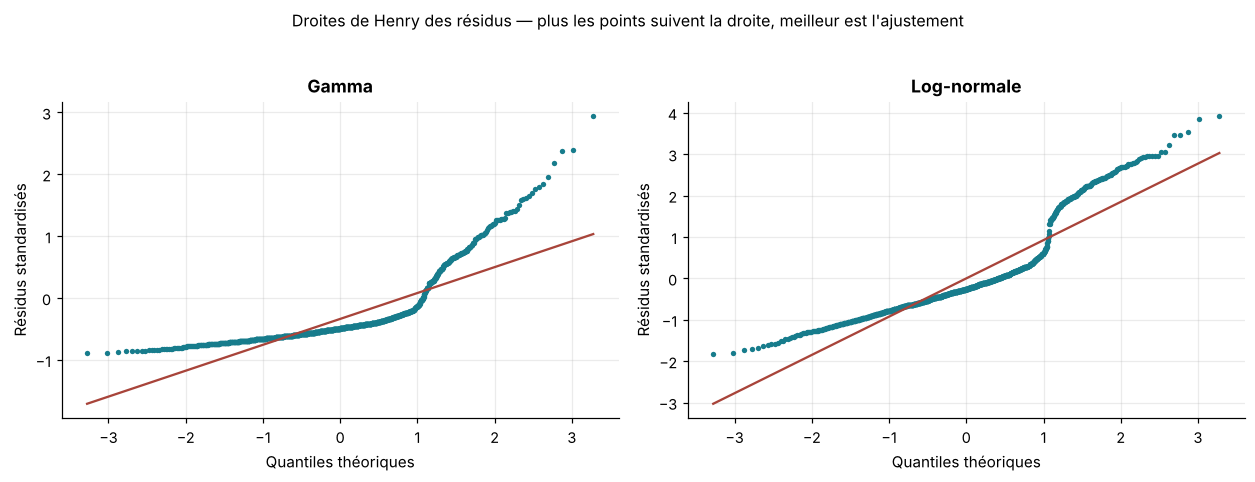

In [47]:
# Diagnostic graphique de l'ajustement des deux lois
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
for ax, loi in zip(axes, LOIS):
    mc = modeles_lois[loi]
    m = mc["modele"]
    if loi == "Log-normale":
        resid = m.resid / np.sqrt(np.sum(m.resid ** 2) / len(m.resid))
    else:
        resid = m.resid_deviance / np.sqrt(m.scale)
    stats.probplot(resid, dist="norm", plot=ax)
    ax.set_title(f"{loi}")
    ax.get_lines()[0].set_markerfacecolor(PALETTE["petrole"])
    ax.get_lines()[0].set_markeredgecolor("none")
    ax.get_lines()[0].set_markersize(3.5)
    ax.get_lines()[1].set_color(PALETTE["brique"])
    ax.set_xlabel("Quantiles théoriques")
    ax.set_ylabel("Résidus standardisés")
plt.suptitle("Droites de Henry des résidus — plus les points suivent la droite, "
             "meilleur est l'ajustement", y=1.03, fontsize=10.5)
plt.tight_layout()
sauver_fig("4_3_qqplots_lois_cout")

**Lecture.** L'AIC désigne nettement la log-normale (plus de 2 300 points d'écart). Mais
les droites de Henry montrent qu'**aucune des deux lois n'ajuste réellement les
données** : les résidus dessinent un S avec une rupture nette, signature des deux
populations de sinistres relevées au §2.1. Deux chiffres mesurent ce défaut :

- la Gamma estime une dispersion de 9,09, soit un coefficient de variation de 3,0 — à
  titre de repère, la loi exponentielle correspond à 1 ;
- la log-normale a besoin d'un facteur de lissage de 5,4 pour retrouver le coût moyen :
  `exp(Xβ)` décrit le sinistre courant, et c'est ce facteur, identique pour tous, qui
  porte l'essentiel du coût.

On ne tranche donc pas ici. Les deux lois sont conservées comme candidates, et
départagées sur des données qu'elles n'ont pas vues (§5 et §6).

### 4.3.2 Sélection des variables du modèle de coût

La sélection suit deux étapes, appliquées à l'identique aux deux lois :

1. **élimination descendante par l'AIC**, comme pour la fréquence ;
2. **test de Fisher de retrait** de chaque variable restante, au seuil de 5 % : une
   variable n'est conservée que si son retrait dégrade significativement l'ajustement.
   Le test de Fisher est celui qui convient quand la dispersion est estimée, ce qui est
   le cas des deux lois.

In [48]:
def ajusteur_cout(df, loi):
    """Fabrique la fonction d'ajustement utilisee par la selection descendante."""
    def ajuste(vars_):
        mc = ajuster_cout(df, vars_, loi)
        return mc, mc["aic"]
    return ajuste


def tests_de_retrait(df, variables, loi):
    """Test de Fisher du retrait de chaque variable du modele de cout."""
    complet = ajuster_cout(df, variables, loi)
    lignes = []
    for v in variables:
        reduit = ajuster_cout(df, [x for x in variables if x != v], loi)
        ddl = reduit["ddl_resid"] - complet["ddl_resid"]
        f_stat = ((reduit["ecart"] - complet["ecart"]) / ddl) / complet["dispersion"]
        lignes.append({"Variable testée": v, "Statistique F": round(f_stat, 2), "ddl": ddl,
                       "p-value": round(float(1 - stats.f.cdf(f_stat, ddl, complet["ddl_resid"])), 4)})
    return pd.DataFrame(lignes)


def selectionner_cout(df, loi, variables=None, verbeux=True):
    """Selection complete : AIC descendant, puis tests de Fisher au seuil de 5 %."""
    variables = list(variables if variables is not None else VARS_COUT)
    _, retenues = selection_descendante(ajusteur_cout(df, loi), variables, verbeux=verbeux)
    if verbeux:
        print(f"   retenues par l'AIC : {retenues if retenues else 'aucune'}")
    while retenues:
        tests = tests_de_retrait(df, retenues, loi)
        pire = tests.sort_values("p-value", ascending=False).iloc[0]
        if verbeux:
            display(tests)
        if pire["p-value"] < 0.05:
            break
        retenues = [v for v in retenues if v != pire["Variable testée"]]
        if verbeux:
            print(f"   retrait de {pire['Variable testée']} (p-value {pire['p-value']:.3f})")
    return retenues


vars_cout = {}
modeles_cout = {}
for loi in LOIS:
    titre(f"SELECTION DES VARIABLES — COUT, LOI {loi.upper()}")
    vars_cout[loi] = selectionner_cout(cout_tous, loi)
    modeles_cout[loi] = ajuster_cout(cout_tous, vars_cout[loi], loi)
    print(f"\nVariables RETENUES : {vars_cout[loi] if vars_cout[loi] else 'AUCUNE (modele reduit a la constante)'}")
    print(f"Variables ECARTEES : {[v for v in VARS_COUT if v not in vars_cout[loi]]}")


SELECTION DES VARIABLES — COUT, LOI GAMMA


,Étape,Variable retirée,Variables restantes,AIC
0,0,—,9,25 988.900
1,1,tr_puissance,8,25 937.100
2,2,classe_vehicule,7,25 917.300
3,3,type_couverture,6,25 908.500


   retenues par l'AIC : ['jeune_conducteur', 'zone_geo', 'carburant', 'tr_age_vehicule', 'usage_vehicule', 'tr_bonus']


,Variable testée,Statistique F,ddl,p-value
0,jeune_conducteur,6.360,1,0.012
1,zone_geo,2.200,5,0.052
2,carburant,0.850,4,0.495
3,tr_age_vehicule,0.420,4,0.792
4,usage_vehicule,3.150,2,0.043
5,tr_bonus,0.440,5,0.818


   retrait de tr_bonus (p-value 0.818)


,Variable testée,Statistique F,ddl,p-value
0,jeune_conducteur,6.570,1,0.011
1,zone_geo,2.320,5,0.041
2,carburant,0.950,4,0.432
3,tr_age_vehicule,0.390,4,0.818
4,usage_vehicule,3.100,2,0.045


... (7 outputs left out)

,Variable testée,Statistique F,ddl,p-value
0,tr_puissance,2.470,4,0.043
1,usage_vehicule,2.380,2,0.093


   retrait de usage_vehicule (p-value 0.093)


,Variable testée,Statistique F,ddl,p-value
0,tr_puissance,2.460,4,0.044



Variables RETENUES : ['tr_puissance']
Variables ECARTEES : ['jeune_conducteur', 'zone_geo', 'classe_vehicule', 'carburant', 'tr_age_vehicule', 'type_couverture', 'usage_vehicule', 'tr_bonus']


In [49]:
for loi in LOIS:
    titre(f"COEFFICIENTS DU MODELE DE COUT — LOI {loi.upper()}", 2)
    mc = modeles_cout[loi]
    nom = "4_3_coefficients_cout_" + ("gamma" if loi == "Gamma" else "lognormale")
    coefs = table_coefficients(mc["modele"], nom)
    display(coefs)
    hors_cste = coefs.iloc[1:]
    if len(hors_cste):
        print(f"Coefficients significatifs a 5 % (hors constante) : "
              f"{int((hors_cste['Significatif à 5 %'] == 'Oui').sum())} sur {len(hors_cste)}")
        print(f"Rapport entre le coefficient le plus eleve et le plus faible : "
              f"{fr(max(1.0, hors_cste['Coef. multiplicatif exp(β)'].max()) / min(1.0, hors_cste['Coef. multiplicatif exp(β)'].min()), 2)}")
    if loi == "Log-normale":
        print(f"Facteur de lissage de Duan : {mc['lissage']:.4f}")
    print(f"Cout moyen predit : {fr(mc['mu'].mean())}   (observe : {fr(cout_tous['montant'].mean())}, "
          f"ecart {pct(mc['mu'].mean() / cout_tous['montant'].mean() - 1, 2)})")


------------------------------------------------------------------------------
COEFFICIENTS DU MODELE DE COUT — LOI GAMMA
------------------------------------------------------------------------------


,Coefficient β,Erreur-type,p-value,Coef. multiplicatif exp(β),IC 95 % bas,IC 95 % haut,Significatif à 5 %
Intercept,9.244,0.296,0.000,10 345.734,5 791.190,18 482.249,Oui
jeune_conducteur : Oui,0.622,0.239,0.009,1.863,1.165,2.978,Oui
zone_geo : B,-0.036,0.308,0.906,0.964,0.528,1.763,Non
zone_geo : C,-0.591,0.276,0.032,0.554,0.322,0.952,Oui
zone_geo : D,-0.520,0.295,0.078,0.594,0.333,1.061,Non
zone_geo : E,-0.905,0.332,0.006,0.404,0.211,0.776,Oui
zone_geo : Non renseignée,-0.678,0.825,0.411,0.508,0.101,2.557,Non
usage_vehicule : Privé,0.022,0.218,0.921,1.022,0.667,1.565,Non
usage_vehicule : Professionnel,-0.623,0.286,0.030,0.536,0.306,0.940,Oui


Coefficients significatifs a 5 % (hors constante) : 4 sur 8
Rapport entre le coefficient le plus eleve et le plus faible : 4,61
Cout moyen predit : 7 378   (observe : 7 213, ecart 2,28 %)

------------------------------------------------------------------------------
COEFFICIENTS DU MODELE DE COUT — LOI LOG-NORMALE
------------------------------------------------------------------------------


,Coefficient β,Erreur-type,p-value,Coef. multiplicatif exp(β),IC 95 % bas,IC 95 % haut,Significatif à 5 %
Intercept,7.422,0.102,0.000,1 672.968,1 371.027,2 041.406,Oui
tr_puissance : 6-7 CV,-0.337,0.122,0.006,0.714,0.563,0.907,Oui
tr_puissance : 8-9 CV,-0.361,0.129,0.005,0.697,0.541,0.897,Oui
tr_puissance : 10-11 CV,-0.323,0.150,0.032,0.724,0.539,0.973,Oui
tr_puissance : 12 CV et +,-0.381,0.198,0.055,0.683,0.463,1.008,Non


Coefficients significatifs a 5 % (hors constante) : 3 sur 4
Rapport entre le coefficient le plus eleve et le plus faible : 1,46
Facteur de lissage de Duan : 5.6703
Cout moyen predit : 7 172   (observe : 7 213, ecart -0,57 %)


**Lecture.** Les deux lois ne retiennent pas les mêmes variables : la Gamma garde le
statut de novice, la zone et l'usage du véhicule ; la log-normale, la seule puissance
fiscale. L'explication est mécanique — la Gamma modélise directement la moyenne, tirée
par les sinistres lourds, alors que la log-normale modélise le logarithme, dominé par
les sinistres courants. Mais la conséquence est gênante : **la segmentation du coût
dépend de la loi choisie**.

Les coefficients de la Gamma sont de grande amplitude et très imprécis : la zone E
ressort à 0,40 avec un intervalle de 0,21 à 0,78, le conducteur novice à 1,86 avec un
intervalle de 1,17 à 2,98. Aux tests de Fisher, les p-values sont comprises entre
0,008 et 0,044 : significatives, mais sans marge. De tels écarts reposent sur la
position de quelques dizaines de sinistres lourds ; la partie E vérifie s'ils se
retrouvent sur d'autres échantillons.

## 4.4 Prime pure modélisée et récapitulatif

La prime pure d'un contrat est le produit de ses deux briques :

$$\text{Prime pure} = \underbrace{\hat f(X)}_{\text{GLM de fréquence}} \times \underbrace{\hat c(X)}_{\text{modèle de coût}} \times \underbrace{p_+}_{\text{part de montants positifs}}$$

Le produit de deux modèles estimés séparément ne redonne pas exactement la charge
observée. On applique donc un **coefficient de recalage** unique, qui ramène la somme
des primes au niveau de la charge de l'échantillon de calibration — sans modifier les
écarts relatifs entre assurés.

In [50]:
APPROCHES = ["1. Prime uniforme", "2. Fréquence × coût moyen",
             "3. Fréquence × coût Gamma", "4. Fréquence × coût log-normal"]


def calibrer_tarif(base_calib, sinistres_calib):
    """Calibre toutes les briques tarifaires sur un echantillon de calibration.

    `sinistres_calib` doit contenir les seuls sinistres de cet echantillon : c'est ce qui
    garantit qu'aucune information de l'echantillon de test n'entre dans le tarif.
    """
    positifs = sinistres_calib[sinistres_calib["montant"] > 0]
    m = {"freq": ajuster_frequence(base_calib, vars_freq)[0],
         "part_positifs": len(positifs) / len(sinistres_calib),
         "cout_moyen_positifs": float(positifs["montant"].mean()),
         "cout_gamma": ajuster_cout(positifs, vars_cout["Gamma"], "Gamma"),
         "cout_ln": ajuster_cout(positifs, vars_cout["Log-normale"], "Log-normale"),
         "pp_uniforme": float(base_calib["charge_totale"].sum() / base_calib["exposition"].sum()),
         "recalage": {a: 1.0 for a in APPROCHES}}
    brutes = appliquer_tarif(m, base_calib)
    charge = base_calib["charge_totale"].sum()
    expo = base_calib["exposition"].values
    m["recalage"] = {a: float(charge / (brutes[a].values * expo).sum()) for a in APPROCHES}
    return m


def appliquer_tarif(m, df):
    """Calcule la prime pure annuelle de chaque contrat selon les quatre constructions."""
    # Frequence annualisee (offset neutre : on veut une frequence par annee-police)
    f = m["freq"].predict(df, offset=np.zeros(len(df))).values
    pos = m["part_positifs"]
    p = pd.DataFrame(index=df.index)
    p[APPROCHES[0]] = m["pp_uniforme"]
    p[APPROCHES[1]] = f * m["cout_moyen_positifs"] * pos
    p[APPROCHES[2]] = f * predire_cout(m["cout_gamma"], df) * pos
    p[APPROCHES[3]] = f * predire_cout(m["cout_ln"], df) * pos
    for a in APPROCHES:
        p[a] = p[a] * m["recalage"][a]
    return p


titre("PRIME PURE MODELISEE SUR LE PORTEFEUILLE COMPLET")
modeles_complet = calibrer_tarif(base_tarif, sin_carac)
primes_complet = appliquer_tarif(modeles_complet, base_tarif)
expo_c = base_tarif["exposition"].values
tab_pp = pd.DataFrame([{
    "Construction": a,
    "Coefficient de recalage": fr(modeles_complet["recalage"][a], 3),
    "Prime pure moyenne": fr(np.average(primes_complet[a], weights=expo_c)),
    "Minimum": fr(primes_complet[a].min()), "Maximum": fr(primes_complet[a].max()),
    "Rapport max / min": fr(primes_complet[a].max() / primes_complet[a].min(), 2),
    "Charge collectée / observée": pct((primes_complet[a].values * expo_c).sum()
                                       / base_tarif["charge_totale"].sum(), 2),
} for a in APPROCHES])
exporter_table(tab_pp, "4_4_prime_pure_modelisee", index=False)
display(tab_pp)
print("-> Apres recalage, chaque construction collecte exactement la charge observee.")
print("   Elles ne different que par la REPARTITION de cette charge entre assures.")


PRIME PURE MODELISEE SUR LE PORTEFEUILLE COMPLET


,Construction,Coefficient de recalage,Prime pure moyenne,Minimum,Maximum,Rapport max / min,Charge collectée / observée
0,1. Prime uniforme,"1,000",826,826,826,"1,00","100,00 %"
1,2. Fréquence × coût moyen,"1,000",826,669,1 366,"2,04","100,00 %"
2,3. Fréquence × coût Gamma,"0,974",826,203,2 740,"13,52","100,00 %"
3,4. Fréquence × coût log-normal,"1,007",826,605,1 809,"2,99","100,00 %"


-> Apres recalage, chaque construction collecte exactement la charge observee.
   Elles ne different que par la REPARTITION de cette charge entre assures.


In [51]:
recap = pd.DataFrame([
    {"Modèle": "Fréquence — tous sinistres", "Variable cible": "nb_sinistres (comptage)",
     "Variables explicatives": ", ".join(vars_freq), "Loi": "Poisson", "Lien": "log",
     "Offset": "log(exposition)", "Sélection": "AIC (élimination descendante)",
     "Validation": "Conservation du total, calibration par classe, test hors échantillon (§5)"},
    {"Modèle": "Coût — tous sinistres (Gamma)", "Variable cible": "montant du sinistre (> 0)",
     "Variables explicatives": ", ".join(vars_cout["Gamma"]) or "aucune", "Loi": "Gamma",
     "Lien": "log", "Offset": "aucun", "Sélection": "AIC, puis test de Fisher à 5 %",
     "Validation": "Droite de Henry, stabilité de la sélection et test hors échantillon (§5, §6)"},
    {"Modèle": "Coût — tous sinistres (log-normale)", "Variable cible": "log du montant (> 0)",
     "Variables explicatives": ", ".join(vars_cout["Log-normale"]) or "aucune",
     "Loi": "Log-normale", "Lien": "log (correction de Duan)", "Offset": "aucun",
     "Sélection": "AIC, puis test de Fisher à 5 %",
     "Validation": "Droite de Henry, stabilité de la sélection et test hors échantillon (§5, §6)"},
])
exporter_table(recap, "4_4_recapitulatif_modeles", index=False)
with pd.option_context("display.max_colwidth", 60):
    display(recap)

,Modèle,Variable cible,Variables explicatives,Loi,Lien,Offset,Sélection,Validation
0,Fréquence — tous sinistres,nb_sinistres (comptage),"jeune_conducteur, zone_geo",Poisson,log,log(exposition),AIC (élimination descendante),"Conservation du total, calibration par classe, test hors..."
1,Coût — tous sinistres (Gamma),montant du sinistre (> 0),"jeune_conducteur, zone_geo, usage_vehicule",Gamma,log,aucun,"AIC, puis test de Fisher à 5 %","Droite de Henry, stabilité de la sélection et test hors ..."
2,Coût — tous sinistres (log-normale),log du montant (> 0),tr_puissance,Log-normale,log (correction de Duan),aucun,"AIC, puis test de Fisher à 5 %","Droite de Henry, stabilité de la sélection et test hors ..."


### Ce qu'il faut retenir de la partie D

- **Fréquence** : la loi de Poisson est retenue après test (dispersion de 0,997 ; la
  binomiale négative dégrade l'AIC). Deux variables survivent à la sélection : le
  statut de conducteur novice (coefficient 1,48) et la zone géographique.
  L'interaction entre les deux est rejetée : le tarif multiplicatif est validé.
- **Colinéarité tranchée** : âge et ancienneté du permis portent la même information ;
  l'indicatrice « conducteur novice » les résume avec le meilleur AIC.
- **Coût moyen, tous sinistres confondus** : aucune des deux lois n'ajuste une
  distribution qui mêle deux populations. Les variables retenues diffèrent selon la
  loi, et les coefficients sont imprécis.
- **Prime pure** : fréquence × coût, recalée pour collecter exactement la charge.
  Quatre constructions sont prêtes pour la comparaison du §6.

---
# §5 — Partie E · Séparation Train / Test

> **Ce que demande l'énoncé (point E)**
> *Approche 1 — Séparation aléatoire* : X % en apprentissage, Y % en test.
> *Approche 2 — Séparation temporelle* : années antérieures à N en apprentissage,
> année N+1 en test.

Un modèle doit être estimé sur des données, puis évalué sur d'**autres** données :
sinon l'évaluation mesure sa capacité à retrouver ce qu'on lui a appris, pas à prédire.
Les modèles spécifiés dans la partie D sont donc **réestimés sur un échantillon
d'apprentissage**, puis confrontés à un échantillon de test.

**Les deux approches sont mises en œuvre.** Elles ne répondent pas à la même question,
et c'est précisément ce qui rend leur combinaison utile :

| Approche | Question à laquelle elle répond |
|---|---|
| Temporelle | Le tarif calibré sur une période tiendra-t-il sur la suivante ? |
| Aléatoire | Le tarif tient-il sur des assurés qu'il n'a jamais vus ? |

## 5.1 Approche temporelle — un obstacle et son contournement

### L'obstacle

La formulation littérale de l'énoncé — « années antérieures à N en apprentissage,
année N+1 en test » — suppose **plusieurs années de souscription**. Or le §1.4 a
montré que toutes les dates d'effet se situent en 2023.

In [52]:
titre("VERIFICATION : COMBIEN D'ANNEES DE SOUSCRIPTION ?", 2)
print("Repartition des dates d'effet par annee :")
print(contrats["date_effet"].dt.year.value_counts().sort_index().to_string())
print("\nRepartition des dates de survenance des sinistres par annee :")
print(sinistres["date_sin"].dt.year.value_counts().sort_index().to_string())
print("\n-> UNE SEULE annee de souscription (2023), mais DEUX annees de survenance")
print("   (2023 et 2024). Un contrat souscrit en cours d'annee 2023 reste en effet")
print("   expose une partie de 2024.")
print("\n   La separation par annee de SOUSCRIPTION est donc impossible.")
print("   En revanche, la separation par annee de SURVENANCE est parfaitement")
print("   realisable, et c'est elle qui a du sens pour valider un tarif : on calibre")
print("   sur ce qui s'est passe en 2023, on verifie sur ce qui s'est passe en 2024.")


------------------------------------------------------------------------------
VERIFICATION : COMBIEN D'ANNEES DE SOUSCRIPTION ?
------------------------------------------------------------------------------
Repartition des dates d'effet par annee :
date_effet
2023    19981

Repartition des dates de survenance des sinistres par annee :
date_sin
2023    876
2024    451

-> UNE SEULE annee de souscription (2023), mais DEUX annees de survenance
   (2023 et 2024). Un contrat souscrit en cours d'annee 2023 reste en effet
   expose une partie de 2024.

   La separation par annee de SOUSCRIPTION est donc impossible.
   En revanche, la separation par annee de SURVENANCE est parfaitement
   realisable, et c'est elle qui a du sens pour valider un tarif : on calibre
   sur ce qui s'est passe en 2023, on verifie sur ce qui s'est passe en 2024.


### Le contournement : découpage par période de survenance

L'exposition de chaque contrat est **scindée** au 1er janvier 2024, et les sinistres
sont affectés à la période où ils sont survenus. Un contrat prenant effet le
1er septembre 2023 pour une durée de 0,8 année contribue ainsi pour 0,33 année-police
à 2023 (N) et 0,47 année-police à 2024 (N+1).

C'est le découpage dit « par exercice de survenance », usuel en assurance non-vie.

In [53]:
def decouper_par_periode(contrats_df, sinistres_df, debut, fin):
    """Restreint contrats et sinistres a une fenetre temporelle.

    L'exposition est recalculee au prorata de l'intersection entre la periode de
    couverture du contrat et la fenetre ; les sinistres sont filtres sur leur date
    de survenance. Seuls les contrats reellement exposes sur la fenetre sont conserves.
    """
    d = contrats_df.copy()
    debut_contrat = d["date_effet"]
    fin_contrat = debut_contrat + pd.to_timedelta(d["exposition"] * 365.25, unit="D")

    debut_eff = debut_contrat.clip(lower=debut)
    fin_eff = fin_contrat.clip(upper=fin)
    d["exposition"] = ((fin_eff - debut_eff).dt.total_seconds()
                       / (365.25 * 24 * 3600)).clip(lower=0)
    d = d[d["exposition"] > 0].copy()

    s = sinistres_df[(sinistres_df["date_sin"] >= debut)
                     & (sinistres_df["date_sin"] < fin)
                     & (sinistres_df["id_police"].isin(set(d["id_police"])))].copy()

    agg = s.groupby("id_police").agg(
        nb_sinistres=("id_sinistre", "size"), charge_totale=("montant", "sum"))
    d = d.merge(agg, on="id_police", how="left")
    for c in ["nb_sinistres", "charge_totale"]:
        d[c] = d[c].fillna(0)
    d["nb_sinistres"] = d["nb_sinistres"].astype(int)
    return d


train_temp = decouper_par_periode(contrats, sinistres,
                                  pd.Timestamp("2023-01-01"), DATE_CUT)
test_temp = decouper_par_periode(contrats, sinistres,
                                 DATE_CUT, pd.Timestamp("2025-01-01"))

titre("DECOUPAGE TEMPOREL PAR EXERCICE DE SURVENANCE")
print(f"TRAIN (survenance 2023, N)   : {fr(len(train_temp))} contrats exposes, "
      f"{fr(train_temp['exposition'].sum(), 1)} annees-police, "
      f"{fr(train_temp['nb_sinistres'].sum())} sinistres")
print(f"TEST  (survenance 2024, N+1) : {fr(len(test_temp))} contrats exposes, "
      f"{fr(test_temp['exposition'].sum(), 1)} annees-police, "
      f"{fr(test_temp['nb_sinistres'].sum())} sinistres")

expo_recomposee = train_temp["exposition"].sum() + test_temp["exposition"].sum()
print(f"\nControle de conservation de l'exposition :")
print(f"   exposition train + test = {fr(expo_recomposee, 1)}")
print(f"   exposition totale       = {fr(contrats['exposition'].sum(), 1)}")
assert abs(expo_recomposee - contrats["exposition"].sum()) < 1.0
print("   [OK] L'exposition se conserve : aucune annee-police perdue ni comptee deux fois.")

nb_recompose = train_temp["nb_sinistres"].sum() + test_temp["nb_sinistres"].sum()
print(f"\n   sinistres train + test  = {fr(nb_recompose)}  (total : {fr(len(sinistres))})")
assert nb_recompose == len(sinistres)
print("   [OK] Tous les sinistres sont affectes a une periode et une seule.")


DECOUPAGE TEMPOREL PAR EXERCICE DE SURVENANCE
TRAIN (survenance 2023, N)   : 19 981 contrats exposes, 7 583,7 annees-police, 876 sinistres
TEST  (survenance 2024, N+1) : 11 588 contrats exposes, 3 948,3 annees-police, 451 sinistres

Controle de conservation de l'exposition :
   exposition train + test = 11 532,0
   exposition totale       = 11 532,0
   [OK] L'exposition se conserve : aucune annee-police perdue ni comptee deux fois.

   sinistres train + test  = 1 327  (total : 1 327)
   [OK] Tous les sinistres sont affectes a une periode et une seule.


### La limite de cette approche, énoncée franchement

Une **même police alimente les deux échantillons** : celle qui prend effet en
septembre 2023 est présente en 2023 et en 2024. Le test ne porte donc pas sur des
assurés inconnus du modèle, mais sur une **nouvelle période d'observation des mêmes
assurés**.

Ce dispositif valide donc la **stabilité temporelle** du tarif — ce qui est exactement
ce qu'un assureur veut savoir avant de déposer un tarif pour l'exercice suivant —
mais **pas** sa capacité à généraliser à de nouveaux souscripteurs. D'où la seconde
approche.

## 5.2 Approche aléatoire — 80 % / 20 %

Trois précautions méthodologiques :

1. **Le tirage porte sur la police, jamais sur la ligne de sinistre.** Répartir les
   sinistres au hasard placerait deux sinistres d'un même contrat de part et d'autre
   de la frontière : le modèle verrait en apprentissage une information sur un contrat
   qu'il est censé découvrir en test. C'est une fuite d'information classique.
2. **Le tirage est stratifié sur la présence de sinistre.** Avec seulement 6,4 % de
   contrats sinistrés, un tirage simple pourrait produire des taux sensiblement
   différents entre les deux échantillons.
3. **La graine aléatoire est fixée** pour que le résultat soit reproductible.

In [54]:
titre("DECOUPAGE ALEATOIRE 80 / 20 STRATIFIE")

base_split = base_tarif.copy()
base_split["a_sinistre"] = (base_split["nb_sinistres"] > 0).astype(int)

indices_train = []
generateur = np.random.default_rng(GRAINE)
for strate, sous_base in base_split.groupby("a_sinistre"):
    idx = sous_base.index.to_numpy().copy()   # copie : to_numpy() renvoie un tableau en lecture seule
    generateur.shuffle(idx)
    n_tr = int(round(PART_TRAIN * len(idx)))
    indices_train.extend(idx[:n_tr].tolist())
    print(f"Strate « {'avec' if strate else 'sans'} sinistre » : {fr(len(idx))} contrats "
          f"-> {fr(n_tr)} en train, {fr(len(idx) - n_tr)} en test")

masque_train = base_split.index.isin(indices_train)
train_alea = base_split[masque_train].drop(columns="a_sinistre").copy()
test_alea = base_split[~masque_train].drop(columns="a_sinistre").copy()

print(f"\nTRAIN : {fr(len(train_alea))} contrats, "
      f"{fr(train_alea['exposition'].sum(), 1)} annees-police, "
      f"{fr(train_alea['nb_sinistres'].sum())} sinistres")
print(f"TEST  : {fr(len(test_alea))} contrats, "
      f"{fr(test_alea['exposition'].sum(), 1)} annees-police, "
      f"{fr(test_alea['nb_sinistres'].sum())} sinistres")

assert set(train_alea["id_police"]) & set(test_alea["id_police"]) == set()
print("\n[OK] Aucune police n'appartient aux deux echantillons : pas de fuite d'information.")

# Sinistres rattaches a chaque echantillon d'apprentissage et de test
DISPOSITIFS = {
    "Temporel : train N (2023) / test N+1 (2024)": {
        "train": train_temp, "test": test_temp,
        "sin_train": sin_carac[sin_carac["annee"] == 2023],
        "sin_test": sin_carac[sin_carac["annee"] == 2024]},
    "Aléatoire : train 80 % / test 20 %": {
        "train": train_alea, "test": test_alea,
        "sin_train": sin_carac[sin_carac["id_police"].isin(set(train_alea["id_police"]))],
        "sin_test": sin_carac[sin_carac["id_police"].isin(set(test_alea["id_police"]))]},
}
for nom, dsp in DISPOSITIFS.items():
    assert len(dsp["sin_train"]) == dsp["train"]["nb_sinistres"].sum()
    assert len(dsp["sin_test"]) == dsp["test"]["nb_sinistres"].sum()
print("[OK] Les sinistres de chaque echantillon reconcilient avec les contrats.")


DECOUPAGE ALEATOIRE 80 / 20 STRATIFIE
Strate « sans sinistre » : 18 709 contrats -> 14 967 en train, 3 742 en test
Strate « avec sinistre » : 1 272 contrats -> 1 018 en train, 254 en test

TRAIN : 15 985 contrats, 9 221,3 annees-police, 1 067 sinistres
TEST  : 3 996 contrats, 2 310,7 annees-police, 260 sinistres

[OK] Aucune police n'appartient aux deux echantillons : pas de fuite d'information.
[OK] Les sinistres de chaque echantillon reconcilient avec les contrats.


## 5.3 Contrôle de représentativité

Un découpage n'est exploitable que si les deux échantillons sont comparables. On
vérifie la structure de risque, puis la structure des variables tarifaires. La colonne
« Plus gros sinistre » est ajoutée parce que, dans une approche où tous les sinistres
sont modélisés ensemble, la présence ou l'absence de quelques sinistres lourds suffit à
déplacer le coût moyen d'un échantillon.

In [55]:
def profil_echantillon(df, sin, nom):
    """Resume les indicateurs de risque d'un echantillon."""
    e, n, c = df["exposition"].sum(), df["nb_sinistres"].sum(), df["charge_totale"].sum()
    return {
        "Échantillon": nom,
        "Contrats": fr(len(df)),
        "Exposition": fr(e, 1),
        "Sinistres": fr(n),
        "Fréquence": fr(n / e, 4),
        "Coût moyen": fr(c / n) if n else "n.d.",
        "Prime pure": fr(c / e),
        "Plus gros sinistre": fr(sin["montant"].max()),
    }


titre("REPRESENTATIVITE DES ECHANTILLONS")
D_T, D_A = list(DISPOSITIFS.values())
comparatif = pd.DataFrame([
    profil_echantillon(base_tarif, sin_carac, "Portefeuille complet"),
    profil_echantillon(D_T["train"], D_T["sin_train"], "Train temporel (2023)"),
    profil_echantillon(D_T["test"], D_T["sin_test"], "Test temporel (2024)"),
    profil_echantillon(D_A["train"], D_A["sin_train"], "Train aléatoire (80 %)"),
    profil_echantillon(D_A["test"], D_A["sin_test"], "Test aléatoire (20 %)"),
])
exporter_table(comparatif, "5_3_representativite_echantillons", index=False)
display(comparatif)

# Test formel : les frequences train et test sont-elles compatibles ?
def test_frequences(df1, df2, nom1, nom2):
    """Test du rapport de vraisemblance de l'egalite de deux frequences poissoniennes.

    Sous H0 les deux echantillons partagent la meme frequence lambda ; sous H1 chacun a
    la sienne. La statistique 2*(ll_H1 - ll_H0) suit asymptotiquement un chi2 a 1 ddl.
    """
    n1, e1 = df1["nb_sinistres"].sum(), df1["exposition"].sum()
    n2, e2 = df2["nb_sinistres"].sum(), df2["exposition"].sum()
    lam = (n1 + n2) / (e1 + e2)
    stat = 2 * (n1 * np.log(n1 / e1) + n2 * np.log(n2 / e2) - (n1 + n2) * np.log(lam))
    p = 1 - stats.chi2.cdf(stat, 1)
    print(f"{nom1} ({fr(n1 / e1, 4)}) vs {nom2} ({fr(n2 / e2, 4)}) : "
          f"chi2 = {stat:.2f}, p-value = {p:.3f} -> "
          f"{'ECART SIGNIFICATIF' if p < 0.05 else 'ecart non significatif'}")


print("\nTest d'egalite des frequences entre echantillons :")
test_frequences(train_temp, test_temp, "Train temporel", "Test temporel")
test_frequences(train_alea, test_alea, "Train aleatoire", "Test aleatoire")


REPRESENTATIVITE DES ECHANTILLONS


,Échantillon,Contrats,Exposition,Sinistres,Fréquence,Coût moyen,Prime pure,Plus gros sinistre
0,Portefeuille complet,19 981,"11 532,0",1 327,"0,1151",7 175,826,429 207
1,Train temporel (2023),19 981,"7 583,7",876,"0,1155",7 057,815,429 207
2,Test temporel (2024),11 588,"3 948,3",451,"0,1142",7 405,846,316 919
3,Train aléatoire (80 %),15 985,"9 221,3",1 067,"0,1157",7 370,853,429 207
4,Test aléatoire (20 %),3 996,"2 310,7",260,"0,1125",6 377,718,191 501



Test d'egalite des frequences entre echantillons :
Train temporel (0,1155) vs Test temporel (0,1142) : chi2 = 0.04, p-value = 0.847 -> ecart non significatif
Train aleatoire (0,1157) vs Test aleatoire (0,1125) : chi2 = 0.16, p-value = 0.685 -> ecart non significatif


In [56]:
# Comparaison de la structure des variables tarifaires
titre("STRUCTURE DES VARIABLES TARIFAIRES DANS CHAQUE ECHANTILLON", 2)
for v in ["jeune_conducteur", "zone_geo"]:
    struct = pd.DataFrame({
        "Train temporel": train_temp.groupby(v, observed=True)["exposition"].sum()
        / train_temp["exposition"].sum(),
        "Test temporel": test_temp.groupby(v, observed=True)["exposition"].sum()
        / test_temp["exposition"].sum(),
        "Train aléatoire": train_alea.groupby(v, observed=True)["exposition"].sum()
        / train_alea["exposition"].sum(),
        "Test aléatoire": test_alea.groupby(v, observed=True)["exposition"].sum()
        / test_alea["exposition"].sum(),
    })
    print(f"\n--- Répartition de l'exposition par {v} ---")
    display(struct.map(lambda x: pct(x)))


------------------------------------------------------------------------------
STRUCTURE DES VARIABLES TARIFAIRES DANS CHAQUE ECHANTILLON
------------------------------------------------------------------------------

--- Répartition de l'exposition par jeune_conducteur ---


,Train temporel,Test temporel,Train aléatoire,Test aléatoire
jeune_conducteur,,,,
Non,"89,7 %","89,5 %","89,8 %","88,9 %"
Oui,"10,3 %","10,5 %","10,2 %","11,1 %"



--- Répartition de l'exposition par zone_geo ---


,Train temporel,Test temporel,Train aléatoire,Test aléatoire
zone_geo,,,,
A,"14,7 %","14,1 %","14,6 %","14,1 %"
B,"19,7 %","20,2 %","19,5 %","21,2 %"
C,"30,2 %","30,3 %","30,4 %","29,6 %"
D,"19,4 %","19,4 %","19,5 %","19,1 %"
E,"15,0 %","15,1 %","15,0 %","14,9 %"
Non renseignée,"1,0 %","1,0 %","1,0 %","1,0 %"


**Lecture.** Les fréquences des échantillons d'apprentissage et de test ne diffèrent pas
significativement, et la structure des variables tarifaires est la même à moins de deux
points près. En revanche, **le coût moyen varie sensiblement d'un échantillon à
l'autre** — de 6 377 à 7 405 — sans que la structure du portefeuille l'explique : c'est
l'effet des sinistres lourds, dont le plus gros n'est pas le même partout. Le test
aléatoire affiche ainsi une prime pure de 718, contre 853 pour son apprentissage.

## 5.4 La sélection de variables se retrouve-t-elle sur l'apprentissage seul ?

La partie D a choisi les variables sur le portefeuille complet. Pour que la validation
soit honnête, il faut vérifier que ce choix ne dépend pas des données de test : on
**rejoue toute la procédure de sélection sur chaque échantillon d'apprentissage** et on
compare les variables retenues.

In [57]:
titre("STABILITE DE LA SELECTION DE VARIABLES")
jeux_selection = {
    "Portefeuille complet": (base_tarif, sin_carac),
    "Train temporel (2023)": (D_T["train"], D_T["sin_train"]),
    "Train aléatoire (80 %)": (D_A["train"], D_A["sin_train"]),
}
SPEC_D = {"Fréquence (Poisson)": vars_freq, "Coût (Gamma)": vars_cout["Gamma"],
          "Coût (log-normale)": vars_cout["Log-normale"]}
selections = {mod: {} for mod in SPEC_D}
for nom, (b, s) in jeux_selection.items():
    pos = s[s["montant"] > 0]
    _, selections["Fréquence (Poisson)"][nom] = selection_descendante(
        ajusteur_frequence(b), vars_depart, verbeux=False)
    selections["Coût (Gamma)"][nom] = selectionner_cout(pos, "Gamma", verbeux=False)
    selections["Coût (log-normale)"][nom] = selectionner_cout(pos, "Log-normale", verbeux=False)

# Une specification est CONFIRMEE si toutes les variables retenues au §4 sont de nouveau
# retenues sur chacun des deux echantillons d'apprentissage.
apprentissages = [n for n in jeux_selection if n != "Portefeuille complet"]
confirme = {mod: bool(SPEC_D[mod]) and all(set(SPEC_D[mod]) <= set(selections[mod][n])
                                           for n in apprentissages) for mod in SPEC_D}
tab_stab = pd.DataFrame({nom: {mod: ", ".join(selections[mod][nom]) or "aucune" for mod in SPEC_D}
                         for nom in jeux_selection})
tab_stab["Variables du §4 confirmées"] = ["Oui" if confirme[mod] else "Non" for mod in tab_stab.index]
tab_stab.index.name = "Modèle"
exporter_table(tab_stab, "5_4_stabilite_selection")
with pd.option_context("display.max_colwidth", 60):
    display(tab_stab)

for mod in SPEC_D:
    print(f"{mod:<22} : variables du §4 "
          f"{'CONFIRMEES sur les deux apprentissages' if confirme[mod] else 'NON confirmees sur les deux apprentissages'}")


STABILITE DE LA SELECTION DE VARIABLES


,Portefeuille complet,Train temporel (2023),Train aléatoire (80 %),Variables du §4 confirmées
Modèle,,,,
Fréquence (Poisson),"jeune_conducteur, zone_geo","jeune_conducteur, zone_geo","jeune_conducteur, zone_geo, carburant, tr_age_vehicule",Oui
Coût (Gamma),"jeune_conducteur, zone_geo, usage_vehicule",aucune,usage_vehicule,Non
Coût (log-normale),tr_puissance,aucune,tr_puissance,Non


Fréquence (Poisson)    : variables du §4 CONFIRMEES sur les deux apprentissages
Coût (Gamma)           : variables du §4 NON confirmees sur les deux apprentissages
Coût (log-normale)     : variables du §4 NON confirmees sur les deux apprentissages


**Lecture.** Pour la **fréquence**, les deux variables du §4 sont retenues sur les trois
jeux de données. L'apprentissage aléatoire en ajoute deux (carburant, âge du véhicule),
que ni le portefeuille complet ni l'apprentissage temporel ne confirment : le noyau du
modèle est stable.

Pour le **coût**, la sélection ne se retrouve pas. Sur l'apprentissage temporel, aucune
variable n'est retenue, quelle que soit la loi ; sur l'apprentissage aléatoire, la
Gamma ne garde que l'usage du véhicule. **Les variables de coût choisies au §4 dépendent
donc de l'échantillon** — ce que laissait craindre l'imprécision du coût moyen mesurée
au §2.2.

La validation est conduite avec les spécifications du §4, pour juger les modèles tels
qu'ils ont été définis.

## 5.5 Validation hors échantillon du modèle de fréquence

Le GLM de fréquence est réestimé sur chaque échantillon d'apprentissage, puis appliqué
à l'échantillon de test correspondant. Trois contrôles : le **niveau** (nombre de
sinistres prédit contre observé), le **gain de déviance** par rapport à un modèle sans
aucune variable, et la **calibration par classe tarifaire**.


VALIDATION HORS ECHANTILLON — FREQUENCE


,Dispositif,Sinistres prédits / observés,Ratio,Déviance sans variable,Déviance du GLM,Gain de déviance [IC 95 %],Probabilité d'un gain positif,Classes où le prédit est dans l'IC
0,Temporel : train N (2023) / test N+1 (2024),"456,5 / 451","1,012","2 734,8","2 723,6","11,2 [-3,8 ; 27,0]","92,5 %",12 / 12
1,Aléatoire : train 80 % / test 20 %,"267,9 / 260","1,031","1 420,9","1 414,9","6,0 [-5,7 ; 17,4]","85,5 %",11 / 12


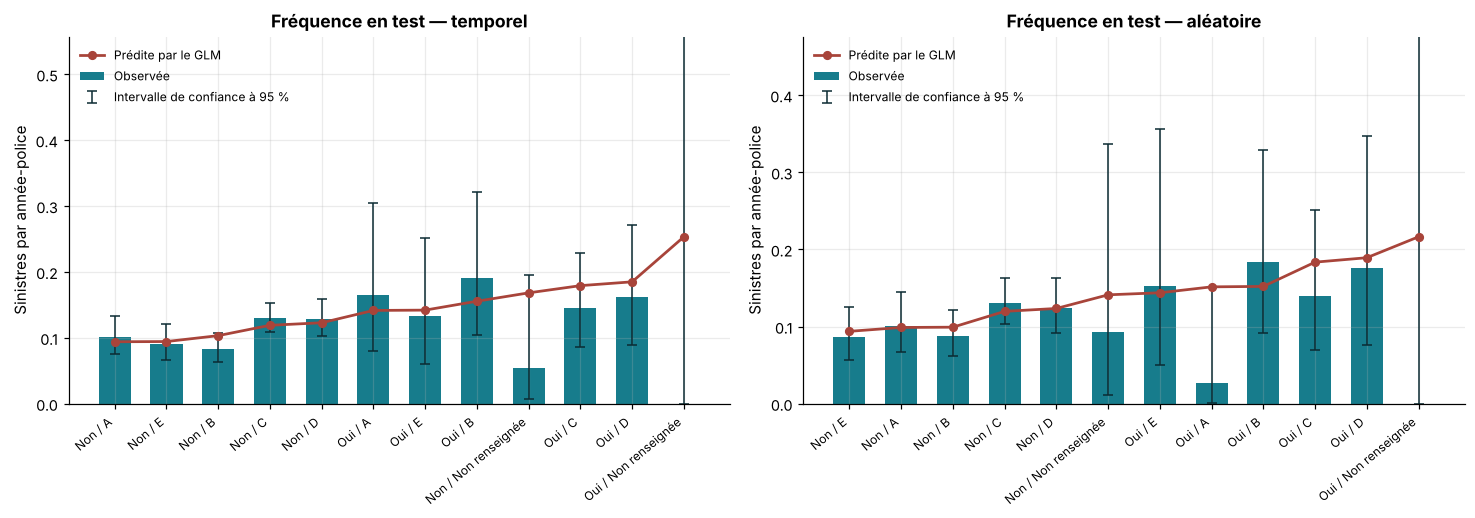

In [58]:
def deviance_poisson_obs(observes, predits):
    """Contribution de chaque contrat a la deviance de Poisson."""
    o = np.asarray(observes, dtype=float)
    p = np.clip(np.asarray(predits, dtype=float), 1e-10, None)
    terme = np.where(o > 0, o * np.log(np.where(o > 0, o, 1.0) / p), 0.0)
    return 2 * (terme - (o - p))


def gain_bootstrap(gains, n_boot=2000, graine=GRAINE):
    """Somme des gains individuels, IC bootstrap a 95 % et probabilite d'un gain positif."""
    g = np.asarray(gains, dtype=float)
    gen = np.random.default_rng(graine)
    sommes = g[gen.integers(0, len(g), (n_boot, len(g)))].sum(axis=1)
    bas, haut = np.percentile(sommes, [2.5, 97.5])
    return float(g.sum()), float(bas), float(haut), float((sommes > 0).mean())


titre("VALIDATION HORS ECHANTILLON — FREQUENCE")
lignes_vf, classes_test = [], {}
for nom, dsp in DISPOSITIFS.items():
    tr, te = dsp["train"], dsp["test"]
    m_f, _ = ajuster_frequence(tr, vars_freq)
    pred = m_f.predict(te, offset=np.log(te["exposition"]))
    freq_train = tr["nb_sinistres"].sum() / tr["exposition"].sum()
    pred_nul = freq_train * te["exposition"]
    dev_m = deviance_poisson_obs(te["nb_sinistres"], pred)
    dev_0 = deviance_poisson_obs(te["nb_sinistres"], pred_nul)
    gain, g_bas, g_haut, g_proba = gain_bootstrap(dev_0 - dev_m)
    classes_test[nom] = table_classes(te, pred, vars_freq)
    n_dans_ic = int((classes_test[nom]["Prédit dans l'IC"] == "Oui").sum())
    lignes_vf.append({
        "Dispositif": nom,
        "Sinistres prédits / observés": f"{fr(pred.sum(), 1)} / {fr(te['nb_sinistres'].sum())}",
        "Ratio": fr(pred.sum() / te["nb_sinistres"].sum(), 3),
        "Déviance sans variable": fr(dev_0.sum(), 1), "Déviance du GLM": fr(dev_m.sum(), 1),
        "Gain de déviance [IC 95 %]": f"{fr(gain, 1)} [{fr(g_bas, 1)} ; {fr(g_haut, 1)}]",
        "Probabilité d'un gain positif": pct(g_proba),
        "Classes où le prédit est dans l'IC": f"{n_dans_ic} / {len(classes_test[nom])}",
    })
tab_vf = pd.DataFrame(lignes_vf)
exporter_table(tab_vf, "5_5_validation_frequence", index=False)
with pd.option_context("display.max_colwidth", 60):
    display(tab_vf)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
for ax, (nom, g) in zip(axes, classes_test.items()):
    tracer_classes(ax, g, f"Fréquence en test — {nom.split(' : ')[0].lower()}")
plt.tight_layout()
sauver_fig("5_5_frequence_test_par_classe")

**Lecture.** Le nombre de sinistres est prédit à 1 % près en séparation temporelle et à
3 % près en séparation aléatoire. Le GLM fait mieux que la fréquence moyenne sur les
deux tests (gains de déviance de 11,2 et 6,0), et la fréquence prédite tombe dans
l'intervalle de confiance de l'observé dans 12 classes sur 12 et 11 sur 12. Pris
isolément, chaque test reste toutefois trop petit — 451 et 260 sinistres — pour que ce
gain soit établi à 95 % : le §6.5 reprend la question avec davantage de données.

Sur le graphique, la classe « novice, zone non renseignée » ne compte que quelques
années-police : sa barre d'erreur dépasse le cadre.

### Ce qu'il faut retenir de la partie E

- La séparation par **année de souscription** est impossible : le portefeuille ne
  compte qu'un seul millésime. Elle est faite par **année de survenance** — N = 2023 en
  apprentissage, N+1 = 2024 en test — en scindant l'exposition au 1er janvier 2024.
- La séparation aléatoire porte sur les polices (80 % / 20 %), avec stratification.
- Les deux découpages sont **conservatifs** : exposition et sinistres se recomposent
  exactement.
- Les fréquences sont comparables entre apprentissage et test ; le coût moyen, lui,
  varie d'un échantillon à l'autre.
- La sélection de variables est **confirmée pour la fréquence, pas pour le coût**.
- Le GLM de fréquence prédit correctement le niveau sur les deux tests.

---
# §6 — Partie F · Comparaison des approches de pricing

> **Ce que demande l'énoncé (point F)**
> Comparer les résultats selon plusieurs approches, comparer les primes obtenues et
> analyser les écarts.

## 6.1 Les approches mises en concurrence

L'énoncé propose de comparer des approches qui diffèrent par le traitement des
sinistres graves. Dans cette variante, **il n'y a pas de sinistres graves à traiter à
part** : toutes les approches utilisent l'ensemble des sinistres. Ce qui les distingue,
c'est le **degré de segmentation** du tarif — de l'absence totale de segmentation à
la segmentation simultanée de la fréquence et du coût.

| # | Approche | Formule | Ce qui est segmenté |
|---|---|---|---|
| 1 | **Prime uniforme** | charge / exposition | Rien : même prime pour tous. Sert de référence |
| 2 | **Fréquence × coût moyen** | `f(X) × c̄` | La fréquence seule ; le coût moyen est commun à tous |
| 3 | **Fréquence × coût Gamma** | `f(X) × c_Gamma(X)` | La fréquence et le coût (GLM Gamma) |
| 4 | **Fréquence × coût log-normal** | `f(X) × c_LN(X)` | La fréquence et le coût (régression log-normale) |

Les quatre approches collectent la même charge sur l'échantillon d'apprentissage
(recalage du §4.4). La question est donc uniquement : **laquelle répartit le mieux
cette charge entre les assurés ?**

## 6.2 Métriques de comparaison

Chaque approche est calibrée sur l'échantillon d'apprentissage, puis évaluée contrat
par contrat sur l'échantillon de test, en comparant la **charge prédite**
(prime × exposition) à la **charge réellement observée** :

| Métrique | Définition | Lecture |
|---|---|---|
| **R²** | part de la variance de la charge expliquée | 0 = pas mieux que la moyenne du test ; peut être négatif |
| **RMSE** | racine de l'erreur quadratique moyenne | sensible aux gros sinistres |
| **MAE** | erreur absolue moyenne | moins sensible aux gros sinistres |
| **RATIO** | charge prédite / charge observée | 1 = le tarif collecte exactement la charge |
| **Gini** | capacité du tarif à ordonner le risque | 0 = aucun pouvoir de classement |

In [59]:
def gini_discrimination(primes, charges_observees, expo):
    """Indice de Gini mesurant la capacite du tarif a ORDONNER le risque reel.

    On classe les contrats par prime predite croissante, puis on trace la part cumulee
    de charge REELLEMENT survenue contre la part cumulee d'exposition. Un tarif sans
    pouvoir predictif donne 0 ; un tarif parfait s'approche de 1.

    Les contrats de meme prime sont regroupes avant le calcul : le resultat ne depend
    donc pas de l'ordre dans lequel des contrats ex aequo se presentent.
    """
    t = pd.DataFrame({"p": np.round(np.asarray(primes, dtype=float), 6),
                      "c": np.asarray(charges_observees, dtype=float),
                      "e": np.asarray(expo, dtype=float)}).groupby("p").sum().sort_index()
    if t["c"].sum() <= 0 or len(t) < 2:
        return 0.0
    x = np.concatenate([[0], np.cumsum(t["e"]) / t["e"].sum()])
    y = np.concatenate([[0], np.cumsum(t["c"]) / t["c"].sum()])
    aire = float(np.sum((x[1:] - x[:-1]) * (y[1:] + y[:-1]) / 2))
    return 1 - 2 * aire


def metriques(primes, df_test):
    """Calcule les metriques de comparaison d'un tarif sur un echantillon de test."""
    expo = df_test["exposition"].values
    obs = df_test["charge_totale"].values
    pred = np.asarray(primes, dtype=float) * expo
    sse = float(np.sum((obs - pred) ** 2))
    sst = float(np.sum((obs - obs.mean()) ** 2))
    return {"R2": 1 - sse / sst, "RMSE": np.sqrt(sse / len(obs)),
            "MAE": float(np.mean(np.abs(obs - pred))),
            "RATIO": float(pred.sum() / obs.sum()),
            "Gini": gini_discrimination(primes, obs, expo),
            "Prime moyenne": float(np.average(primes, weights=expo))}


titre("CALIBRATION SUR CHAQUE ECHANTILLON D'APPRENTISSAGE")
modeles_dsp, primes_test = {}, {}
for nom, dsp in DISPOSITIFS.items():
    m = calibrer_tarif(dsp["train"], dsp["sin_train"])
    modeles_dsp[nom] = m
    primes_test[nom] = appliquer_tarif(m, dsp["test"])
    print(f"\n{nom}")
    print(f"   prime uniforme (charge / exposition du train) : {fr(m['pp_uniforme'])}")
    print(f"   cout moyen des sinistres positifs            : {fr(m['cout_moyen_positifs'])}")
    print(f"   facteur de lissage de la log-normale          : {fr(m['cout_ln']['lissage'], 3)}")
    print(f"   coefficients de recalage : "
          + " ; ".join(f"{a.split('.')[0]} = {fr(m['recalage'][a], 3)}" for a in APPROCHES[1:]))


CALIBRATION SUR CHAQUE ECHANTILLON D'APPRENTISSAGE

Temporel : train N (2023) / test N+1 (2024)
   prime uniforme (charge / exposition du train) : 815
   cout moyen des sinistres positifs            : 7 081
   facteur de lissage de la log-normale          : 5,696
   coefficients de recalage : 2 = 1,000 ; 3 = 0,973 ; 4 = 1,000

Aléatoire : train 80 % / test 20 %
   prime uniforme (charge / exposition du train) : 853
   cout moyen des sinistres positifs            : 7 411
   facteur de lissage de la log-normale          : 5,866
   coefficients de recalage : 2 = 1,000 ; 3 = 0,978 ; 4 = 1,006


## 6.3 Résultats par approche, selon la séparation Train / Test

Le tableau ci-dessous est construit sur le modèle demandé : **en colonnes les approches
de pricing, en lignes les métriques, regroupées par nature de séparation**.

In [60]:
titre("RESULTATS SUR LES ECHANTILLONS DE TEST")
ORDRE_METRIQUES = ["R2", "RMSE", "MAE", "RATIO", "Gini", "Prime moyenne"]
FORMATS = {"R2": lambda v: fr(v, 4), "RMSE": lambda v: fr(v, 1), "MAE": lambda v: fr(v, 1),
           "RATIO": lambda v: fr(v, 3), "Gini": lambda v: fr(v, 3), "Prime moyenne": fr}

res_num = {}
for nom, dsp in DISPOSITIFS.items():
    for a in APPROCHES:
        res_num[(nom, a)] = metriques(primes_test[nom][a].values, dsp["test"])

lignes, index = [], []
for nom in DISPOSITIFS:
    for met in ORDRE_METRIQUES:
        index.append((nom, met))
        lignes.append({a: FORMATS[met](res_num[(nom, a)][met]) for a in APPROCHES})
tab_res = pd.DataFrame(lignes, index=pd.MultiIndex.from_tuples(index, names=["Rub", "Métrique"]))
exporter_table(tab_res, "6_3_comparaison_approches")
display(tab_res)

for nom, dsp in DISPOSITIFS.items():
    print(f"{nom} : charge observee en test = {fr(dsp['test']['charge_totale'].sum())} "
          f"sur {fr(len(dsp['test']))} contrats")


RESULTATS SUR LES ECHANTILLONS DE TEST


1. Prime uniforme 2. Fréquence × coût moyen 3. Fréquence × coût Gamma 4. Fréquence × coût log-normal
Rub                                         Métrique                                                                                                          
Temporel : train N (2023) / test N+1 (2024) R2                       0,0019                    0,0021                    0,0022                         0,0023
                                            RMSE                    5 232,7                   5 232,3                   5 232,1                        5 231,7
                                            MAE                       537,2                     537,1                     537,2                          536,9
                                            RATIO                     0,964                     0,965                     0,962                          0,965
                                            Gini                      0,000                    -0,025                     0,082                          0,118
                                            Prime moyenne               815                       816                       814                            816
Aléatoire : train 80 % / test 20 %          R2                      -0,0018                   -0,0019                   -0,0052                        -0,0019
                                            RMSE                    5 125,3                   5 125,6                   5 134,1                        5 125,6
                                            MAE                       846,8                     847,0                     857,1                          847,4
                                            RATIO                     1,188                     1,191                     1,210                          1,190
                                            Gini                      0,000                     0,082                     0,152                          0,152
                                            Prime moyenne               853                       855                       868                            854

Temporel : train N (2023) / test N+1 (2024) : charge observee en test = 3 339 584 sur 11 588 contrats
Aléatoire : train 80 % / test 20 % : charge observee en test = 1 657 964 sur 3 996 contrats


**Lecture.** Trois constats.

1. **Les R² sont pratiquement nuls**, et légèrement négatifs en séparation aléatoire.
   Ce n'est pas un défaut propre à ces modèles : à l'échelle d'un contrat, la charge
   est nulle pour plus de neuf contrats sur dix et vaut plusieurs dizaines de milliers
   pour quelques-uns. Aucun tarif ne peut prédire *quel* contrat subira un sinistre
   lourd ; un R² proche de zéro est la norme pour cette cible.
2. **RMSE et MAE sont presque identiques d'une approche à l'autre** : l'écart de RMSE
   ne dépasse pas 9 sur plus de 5 000.
3. **Le RATIO dépend de la séparation, pas de l'approche** : environ 0,96 en temporel
   et 1,19 en aléatoire pour les quatre approches. Le test aléatoire a simplement connu
   des sinistres moins lourds que son apprentissage (§5.3).

Le Gini semble favoriser les approches 3 et 4. Reste à savoir si ces écarts dépassent
le bruit.

## 6.4 Les écarts entre approches sont-ils démontrés ?

Des métriques calculées sur un seul échantillon de test ne suffisent pas à départager
des approches : il faut savoir si les écarts dépassent le bruit. On rééchantillonne
donc les contrats de test (bootstrap, 1 000 tirages) pour obtenir :

- l'intervalle de confiance du **RATIO** et du **Gini** de chaque approche ;
- l'intervalle de confiance de **l'écart de RMSE avec la prime uniforme**. Le tirage
  est commun aux approches comparées (bootstrap apparié), ce qui élimine le bruit qui
  leur est commun : si l'intervalle contient 0, l'approche ne fait pas mieux que
  l'absence de segmentation, au sens de cette métrique.

In [61]:
titre("INTERVALLES DE CONFIANCE BOOTSTRAP (1 000 tirages)", 2)
N_BOOT = 1000
lignes_ic = []
for nom, dsp in DISPOSITIFS.items():
    te = dsp["test"]
    expo = te["exposition"].values
    obs = te["charge_totale"].values
    gen = np.random.default_rng(GRAINE)
    tirages = gen.integers(0, len(te), (N_BOOT, len(te)))
    err2_ref = (obs - primes_test[nom][APPROCHES[0]].values * expo) ** 2
    for a in APPROCHES:
        p = primes_test[nom][a].values
        pred = p * expo
        ratios = pred[tirages].sum(axis=1) / obs[tirages].sum(axis=1)
        err2 = (obs - pred) ** 2
        d_rmse = np.sqrt(err2[tirages].mean(axis=1)) - np.sqrt(err2_ref[tirages].mean(axis=1))
        ginis = (np.array([gini_discrimination(p[i], obs[i], expo[i]) for i in tirages])
                 if a != APPROCHES[0] else np.zeros(N_BOOT))
        ic_r, ic_g, ic_d = (np.percentile(v, [2.5, 97.5]) for v in (ratios, ginis, d_rmse))
        lignes_ic.append({
            "Rub": nom, "Approche": a,
            "RATIO [IC 95 %]": f"{fr(res_num[(nom, a)]['RATIO'], 3)} [{fr(ic_r[0], 3)} ; {fr(ic_r[1], 3)}]",
            "1 dans l'IC": "Oui" if ic_r[0] <= 1 <= ic_r[1] else "Non",
            "Gini [IC 95 %]": ("—" if a == APPROCHES[0] else
                               f"{fr(res_num[(nom, a)]['Gini'], 3)} [{fr(ic_g[0], 3)} ; {fr(ic_g[1], 3)}]"),
            "Classement démontré": ("—" if a == APPROCHES[0] else ("Oui" if ic_g[0] > 0 else "Non")),
            "Écart de RMSE avec l'approche 1 [IC 95 %]": ("—" if a == APPROCHES[0] else
                f"{fr(res_num[(nom, a)]['RMSE'] - res_num[(nom, APPROCHES[0])]['RMSE'], 1)} "
                f"[{fr(ic_d[0], 1)} ; {fr(ic_d[1], 1)}]"),
            "Gain de RMSE démontré": ("—" if a == APPROCHES[0] else ("Oui" if ic_d[1] < 0 else "Non")),
        })
tab_ic = pd.DataFrame(lignes_ic)
exporter_table(tab_ic, "6_4_intervalles_de_confiance", index=False)
with pd.option_context("display.max_colwidth", 60):
    display(tab_ic.set_index(["Rub", "Approche"]))


------------------------------------------------------------------------------
INTERVALLES DE CONFIANCE BOOTSTRAP (1 000 tirages)
------------------------------------------------------------------------------


RATIO [IC 95 %] 1 dans l'IC           Gini [IC 95 %] Classement démontré Écart de RMSE avec l'approche 1 [IC 95 %]  \
Rub                                         Approche                                                                                                                                                   
Temporel : train N (2023) / test N+1 (2024) 1. Prime uniforme               0,964 [0,710 ; 1,364]         Oui                        —                   —                                         —   
                                            2. Fréquence × coût moyen       0,965 [0,709 ; 1,367]         Oui  -0,025 [-0,262 ; 0,219]                 Non                         -0,5 [-4,2 ; 2,2]   
                                            3. Fréquence × coût Gamma       0,962 [0,706 ; 1,363]         Oui   0,082 [-0,087 ; 0,267]                 Non                        -0,7 [-10,4 ; 6,7]   
                                            4. Fréquence × coût log-normal  0,965 [0,708 ; 1,366]         Oui   0,118 [-0,170 ; 0,381]                 Non                         -1,1 [-4,7 ; 2,1]   
Aléatoire : train 80 % / test 20 %          1. Prime uniforme               1,188 [0,819 ; 1,791]         Oui                        —                   —                                         —   
                                            2. Fréquence × coût moyen       1,191 [0,821 ; 1,794]         Oui   0,082 [-0,105 ; 0,304]                 Non                          0,3 [-3,8 ; 3,5]   
                                            3. Fréquence × coût Gamma       1,210 [0,831 ; 1,823]         Oui    0,152 [0,015 ; 0,258]                 Oui                          8,7 [3,6 ; 18,6]   
                                            4. Fréquence × coût log-normal  1,190 [0,820 ; 1,797]         Oui   0,152 [-0,083 ; 0,360]                 Non                          0,2 [-3,7 ; 5,2]   

                                                                           Gain de RMSE démontré  
Rub                                         Approche                                              
Temporel : train N (2023) / test N+1 (2024) 1. Prime uniforme                                  —  
                                            2. Fréquence × coût moyen                        Non  
                                            3. Fréquence × coût Gamma                        Non  
                                            4. Fréquence × coût log-normal                   Non  
Aléatoire : train 80 % / test 20 %          1. Prime uniforme                                  —  
                                            2. Fréquence × coût moyen                        Non  
                                            3. Fréquence × coût Gamma                        Non  
                                            4. Fréquence × coût log-normal                   Non

**Lecture.** Aucun écart n'est démontré sur ces métriques.

- Le RATIO a un intervalle de confiance très large — de 0,71 à 1,37 en temporel, de
  0,82 à 1,79 en aléatoire — qui contient 1 dans tous les cas : ni le 0,96 ni le 1,19
  ne signalent une erreur de niveau.
- Aucune approche n'obtient un gain de RMSE démontré par rapport à la prime uniforme.
  L'approche 3 fait même significativement **moins bien** en séparation aléatoire
  (écart de + 8,7, intervalle de 3,6 à 18,6).
- Le Gini ne se distingue de zéro que dans un cas sur six (approche 3, test
  aléatoire), et ce résultat ne se retrouve pas sur le test temporel.

Mesurées sur la charge totale, les approches sont donc indiscernables : le signal est
noyé par quelques sinistres lourds. Il faut une mesure plus fine.

## 6.5 Chaque brique améliore-t-elle la prédiction de sa propre cible ?

Les métriques précédentes portent sur la charge totale d'un contrat, dominée par
quelques sinistres lourds. Pour départager les approches, on juge donc chaque brique
sur **ce qu'elle est censée prédire** :

- le GLM de fréquence, sur le **nombre de sinistres**, par la déviance de Poisson ;
- les modèles de coût, sur le **montant des sinistres**, par la déviance Gamma — mesure
  d'écart relative, moins dominée par les montants extrêmes que l'erreur quadratique.

Dans chaque cas, on mesure le **gain de déviance par rapport à l'absence de
segmentation** (fréquence moyenne, ou coût moyen, identiques pour tous).

Pour disposer de plus de sinistres en test que dans une séparation unique, on procède
par **validation croisée en 5 blocs** : le portefeuille est partagé en cinq groupes de
polices ; chaque groupe sert de test à son tour, les modèles étant réestimés sur les
quatre autres. Chaque contrat est ainsi prédit une fois, par un modèle qui ne l'a pas vu.

In [62]:
titre("VALIDATION CROISEE EN 5 BLOCS — GAIN DE CHAQUE BRIQUE SUR SA CIBLE")
K_BLOCS = 5
gen = np.random.default_rng(GRAINE)
bloc_police = pd.Series(gen.permutation(len(base_tarif)) % K_BLOCS,
                        index=base_tarif["id_police"].values)
base_cv = base_tarif.assign(bloc=bloc_police.values)
sin_cv = sin_carac.assign(bloc=sin_carac["id_police"].map(bloc_police).values)

gains_cv = {mod: [] for mod in SPEC_D}
primes_cv = pd.DataFrame(index=base_tarif.index, columns=APPROCHES, dtype=float)
for k in range(K_BLOCS):
    tr, te = base_cv[base_cv["bloc"] != k], base_cv[base_cv["bloc"] == k]
    s_tr = sin_cv[sin_cv["bloc"] != k]
    s_te = sin_cv[(sin_cv["bloc"] == k) & (sin_cv["montant"] > 0)]
    m = calibrer_tarif(tr, s_tr)
    primes_cv.loc[te.index, APPROCHES] = appliquer_tarif(m, te)[APPROCHES].values

    # Frequence : GLM contre frequence moyenne de l'apprentissage
    pred = m["freq"].predict(te, offset=np.log(te["exposition"])).values
    pred_nul = tr["nb_sinistres"].sum() / tr["exposition"].sum() * te["exposition"].values
    gains_cv["Fréquence (Poisson)"].append(deviance_poisson_obs(te["nb_sinistres"], pred_nul)
                                           - deviance_poisson_obs(te["nb_sinistres"], pred))
    # Cout : modele contre cout moyen de l'apprentissage
    y_te = s_te["montant"].values
    cout_nul = np.full(len(y_te), m["cout_moyen_positifs"])
    for mod, mc in [("Coût (Gamma)", m["cout_gamma"]), ("Coût (log-normale)", m["cout_ln"])]:
        gains_cv[mod].append(deviance_gamma_obs(y_te, cout_nul)
                             - deviance_gamma_obs(y_te, predire_cout(mc, s_te)))

SEUIL_CONFIANCE = 0.90    # probabilite minimale d'un gain positif pour retenir une segmentation
lignes_cv, proba_gain = [], {}
for mod in SPEC_D:
    g = np.concatenate(gains_cv[mod])
    gain, g_bas, g_haut, g_proba = gain_bootstrap(g)
    proba_gain[mod] = g_proba
    lignes_cv.append({
        "Brique": mod, "Variables": ", ".join(SPEC_D[mod]) or "aucune",
        "Observations prédites hors bloc": fr(len(g)),
        "Gain de déviance [IC 95 %]": f"{fr(gain, 1)} [{fr(g_bas, 1)} ; {fr(g_haut, 1)}]",
        "Probabilité d'un gain positif": pct(g_proba),
        f"Gain établi (seuil {pct(SEUIL_CONFIANCE, 0)})": "Oui" if g_proba >= SEUIL_CONFIANCE else "Non",
    })
tab_cv = pd.DataFrame(lignes_cv)
exporter_table(tab_cv, "6_5_validation_croisee_briques", index=False)
with pd.option_context("display.max_colwidth", 60):
    display(tab_cv)

titre("VALIDATION CROISEE EN 5 BLOCS — METRIQUES PAR APPROCHE", 2)
res_cv = {a: metriques(primes_cv[a].values.astype(float), base_tarif) for a in APPROCHES}
res_cv[APPROCHES[0]]["Gini"] = 0.0     # une prime uniforme ne classe pas les contrats
tab_res_cv = pd.DataFrame(
    [{a: FORMATS[met](res_cv[a][met]) for a in APPROCHES} for met in ORDRE_METRIQUES],
    index=pd.MultiIndex.from_tuples([("Validation croisée : 5 blocs", met) for met in ORDRE_METRIQUES],
                                    names=["Rub", "Métrique"]))
exporter_table(tab_res_cv, "6_5_validation_croisee_approches")
display(tab_res_cv)


VALIDATION CROISEE EN 5 BLOCS — GAIN DE CHAQUE BRIQUE SUR SA CIBLE


,Brique,Variables,Observations prédites hors bloc,Gain de déviance [IC 95 %],Probabilité d'un gain positif,Gain établi (seuil 90 %)
0,Fréquence (Poisson),"jeune_conducteur, zone_geo",19 981,"23,8 [-2,9 ; 51,3]","96,0 %",Oui
1,Coût (Gamma),"jeune_conducteur, zone_geo, usage_vehicule",1 320,"29,6 [-152,3 ; 194,6]","65,4 %",Non
2,Coût (log-normale),tr_puissance,1 320,"5,6 [-62,5 ; 68,0]","57,8 %",Non



------------------------------------------------------------------------------
VALIDATION CROISEE EN 5 BLOCS — METRIQUES PAR APPROCHE
------------------------------------------------------------------------------


1. Prime uniforme 2. Fréquence × coût moyen 3. Fréquence × coût Gamma 4. Fréquence × coût log-normal
Rub                          Métrique                                                                                                          
Validation croisée : 5 blocs R2                       0,0006                    0,0009                    0,0001                         0,0009
                             RMSE                    6 613,6                   6 612,5                   6 615,1                        6 612,6
                             MAE                       890,4                     889,6                     893,1                          890,1
                             RATIO                     1,000                     1,000                     1,001                          1,001
                             Gini                      0,000                     0,031                     0,162                          0,096
                             Prime moyenne               826                       826                       826                            826

**Lecture.** Le contraste entre les deux briques est net.

- **Fréquence** : le gain de déviance est de 23,8, positif avec une probabilité de
  96 %. Segmenter par le statut de novice et la zone améliore bien la prédiction du
  nombre de sinistres sur des contrats que le modèle n'a pas vus.
- **Coût** : les gains (29,6 pour la Gamma, 5,6 pour la log-normale) sont noyés dans
  des intervalles qui vont de valeurs franchement négatives à franchement positives.
  La probabilité d'un gain positif n'est que de 65 % et 58 %.

Les métriques par approche confirment le §6.3 : R² nuls, RMSE et MAE identiques à
quelques unités près. L'approche 2 a les meilleurs RMSE et MAE, l'approche 3 les moins
bons — mais ces écarts restent dans le bruit.

## 6.6 Comparaison des primes obtenues

Les quatre approches sont maintenant appliquées au portefeuille complet (calibration
du §4.4) pour comparer les primes elles-mêmes : dispersion, puis effet sur des profils
types.


DISPERSION DES PRIMES PAR APPROCHE — PORTEFEUILLE COMPLET


,Approche,Prime pure moyenne,Écart-type,Minimum,Maximum,Rapport max / min,Classes tarifaires distinctes
0,1. Prime uniforme,826,0,826,826,"1,00",1
1,2. Fréquence × coût moyen,826,153,669,1 366,"2,04",12
2,3. Fréquence × coût Gamma,826,471,203,2 740,"13,52",36
3,4. Fréquence × coût log-normal,826,194,605,1 809,"2,99",60


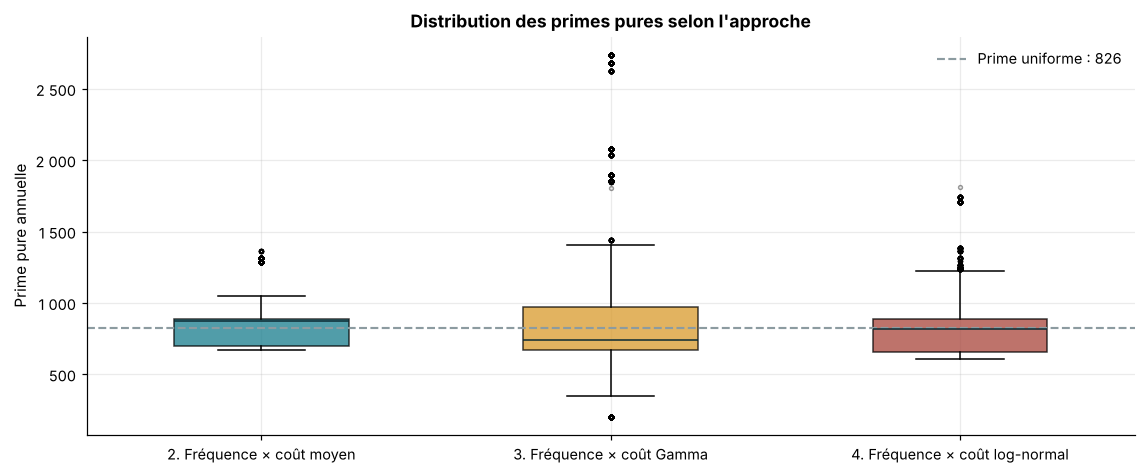

In [63]:
titre("DISPERSION DES PRIMES PAR APPROCHE — PORTEFEUILLE COMPLET")
tab_disp = pd.DataFrame([{
    "Approche": a,
    "Prime pure moyenne": fr(np.average(primes_complet[a], weights=expo_c)),
    "Écart-type": fr(primes_complet[a].std()),
    "Minimum": fr(primes_complet[a].min()), "Maximum": fr(primes_complet[a].max()),
    "Rapport max / min": fr(primes_complet[a].max() / primes_complet[a].min(), 2),
    "Classes tarifaires distinctes": int(primes_complet[a].round(4).nunique()),
} for a in APPROCHES])
exporter_table(tab_disp, "6_6_dispersion_primes", index=False)
display(tab_disp)

fig, ax = plt.subplots(figsize=(10.5, 4.4))
donnees_box = [primes_complet[a].values for a in APPROCHES[1:]]
bp = ax.boxplot(donnees_box, patch_artist=True, widths=0.5, showfliers=True,
                flierprops={"markersize": 2.5, "alpha": 0.4})
for boite, couleur in zip(bp["boxes"], [PALETTE["petrole"], PALETTE["ambre"], PALETTE["brique"]]):
    boite.set_facecolor(couleur); boite.set_alpha(0.75)
for mediane in bp["medians"]:
    mediane.set_color(PALETTE["encre"])
ax.axhline(modeles_complet["pp_uniforme"], color=PALETTE["gris"], linestyle="--", lw=1.4,
           label=f"Prime uniforme : {fr(modeles_complet['pp_uniforme'])}")
ax.set_xticks(range(1, len(APPROCHES)))
ax.set_xticklabels(APPROCHES[1:])
ax.set_ylabel("Prime pure annuelle")
ax.set_title("Distribution des primes pures selon l'approche")
ax.legend(frameon=False)
axe_fr(ax)
plt.tight_layout()
sauver_fig("6_6_distribution_primes")

In [64]:
titre("PRIMES PAR PROFIL TYPE")
PROFILS = [
    ("Novice, zone D, usage privé, 6-7 CV",
     {"jeune_conducteur": "Oui", "zone_geo": "D", "usage_vehicule": "Privé", "tr_puissance": "6-7 CV"}),
    ("Novice, zone A, usage privé, 6-7 CV",
     {"jeune_conducteur": "Oui", "zone_geo": "A", "usage_vehicule": "Privé", "tr_puissance": "6-7 CV"}),
    ("Confirmé, zone D, usage privé, 6-7 CV",
     {"jeune_conducteur": "Non", "zone_geo": "D", "usage_vehicule": "Privé", "tr_puissance": "6-7 CV"}),
    ("Confirmé, zone A, usage privé, 6-7 CV",
     {"jeune_conducteur": "Non", "zone_geo": "A", "usage_vehicule": "Privé", "tr_puissance": "6-7 CV"}),
    ("Confirmé, zone E, usage professionnel, 6-7 CV",
     {"jeune_conducteur": "Non", "zone_geo": "E", "usage_vehicule": "Professionnel", "tr_puissance": "6-7 CV"}),
    ("Confirmé, zone A, usage privé, 1-5 CV",
     {"jeune_conducteur": "Non", "zone_geo": "A", "usage_vehicule": "Privé", "tr_puissance": "1-5 CV"}),
]
# Chaque profil est represente par un contrat reel du portefeuille qui en a les
# caracteristiques : la prime affichee est donc celle d'un assure existant. Les quatre
# caracteristiques fixees sont celles qu'utilisent les modeles compares.
lignes_profils = []
for libelle, crit in PROFILS:
    masque = np.ones(len(base_tarif), dtype=bool)
    for k, v in crit.items():
        masque &= (base_tarif[k].astype(str) == v).values
    lignes_profils.append(base_tarif[masque].iloc[[0]].assign(Profil=libelle))
profils = pd.concat(lignes_profils, ignore_index=True)
primes_profils = appliquer_tarif(modeles_complet, profils)

aff_profils = pd.DataFrame({"Profil": profils["Profil"]})
for a in APPROCHES:
    aff_profils[a] = primes_profils[a].map(fr)
exporter_table(aff_profils, "6_6_primes_profils_types", index=False)
with pd.option_context("display.max_colwidth", 60):
    display(aff_profils)

for a in APPROCHES[1:]:
    rapport = primes_profils.loc[0, a] / primes_profils.loc[3, a]
    print(f"{a:<34} : novice zone D / confirme zone A = {fr(rapport, 2)}")


PRIMES PAR PROFIL TYPE


,Profil,1. Prime uniforme,2. Fréquence × coût moyen,3. Fréquence × coût Gamma,4. Fréquence × coût log-normal
0,"Novice, zone D, usage privé, 6-7 CV",826,1 316,2 080,1 245
1,"Novice, zone A, usage privé, 6-7 CV",826,1 031,2 740,975
2,"Confirmé, zone D, usage privé, 6-7 CV",826,889,754,841
3,"Confirmé, zone A, usage privé, 6-7 CV",826,696,993,658
4,"Confirmé, zone E, usage professionnel, 6-7 CV",826,669,203,633
5,"Confirmé, zone A, usage privé, 1-5 CV",826,696,993,922


2. Fréquence × coût moyen          : novice zone D / confirme zone A = 1,89
3. Fréquence × coût Gamma          : novice zone D / confirme zone A = 2,09
4. Fréquence × coût log-normal     : novice zone D / confirme zone A = 1,89


**Lecture.** Les quatre approches collectent la même charge, mais la répartissent très
différemment.

- L'approche 2 fait varier la prime du simple au double, sur 12 classes.
- L'approche 3 l'étend de 1 à 13,5. Un conducteur confirmé de zone E en usage
  professionnel paierait 203, un novice de zone A 2 740 — davantage qu'un novice de
  zone D (2 080), alors que la zone A est l'une de celles où la fréquence est la plus
  basse. Ce renversement vient entièrement du modèle de coût, dont le §5.4 a montré
  qu'il ne se retrouve pas d'un échantillon à l'autre.
- L'approche 4 fait dépendre la prime de la puissance fiscale : à profil identique,
  922 pour 1-5 CV contre 658 pour 6-7 CV.

## 6.7 Choix de l'approche

La règle de décision est fixée avant de regarder le résultat. **Une segmentation n'est
retenue que si elle satisfait deux conditions** :

1. ses variables, choisies au §4, sont **confirmées** par la sélection rejouée sur
   chacun des deux échantillons d'apprentissage (§5.4) ;
2. elle améliore la prédiction de sa propre cible en validation croisée, avec une
   **probabilité de gain positif d'au moins 90 %** (§6.5).

Le seuil de 90 % est un choix assumé : avec environ 1 300 sinistres, exiger davantage
conduirait à ne jamais rien segmenter, exiger moins reviendrait à tarifer du bruit.
À défaut, la brique reste **mutualisée** — même valeur pour tous.

In [65]:
titre("CHOIX DE L'APPROCHE")
valide = {mod: confirme[mod] and proba_gain[mod] >= SEUIL_CONFIANCE for mod in SPEC_D}
tab_regle = pd.DataFrame([{
    "Brique": mod, "Variables du §4": ", ".join(SPEC_D[mod]) or "aucune",
    "Confirmées sur les deux apprentissages (§5.4)": "Oui" if confirme[mod] else "Non",
    "Probabilité d'un gain positif (§6.5)": pct(proba_gain[mod]),
    "Segmentation retenue": "Oui" if valide[mod] else "Non",
} for mod in SPEC_D])
exporter_table(tab_regle, "6_7_regle_de_decision", index=False)
with pd.option_context("display.max_colwidth", 60):
    display(tab_regle)

if not valide["Fréquence (Poisson)"]:
    APPROCHE_RETENUE = APPROCHES[0]
elif valide["Coût (Gamma)"]:
    APPROCHE_RETENUE = APPROCHES[2]
elif valide["Coût (log-normale)"]:
    APPROCHE_RETENUE = APPROCHES[3]
else:
    APPROCHE_RETENUE = APPROCHES[1]

criteres = []
for a in APPROCHES:
    criteres.append({
        "Approche": a,
        "RATIO (aléatoire / temporel)": " / ".join(
            fr(res_num[(nom, a)]["RATIO"], 3) for nom in reversed(list(DISPOSITIFS))),
        "RMSE en validation croisée": fr(res_cv[a]["RMSE"], 1),
        "MAE en validation croisée": fr(res_cv[a]["MAE"], 1),
        "Rapport max / min des primes": fr(primes_complet[a].max() / primes_complet[a].min(), 2),
        "Décision": "RETENUE" if a == APPROCHE_RETENUE else "Écartée",
    })
tab_choix = pd.DataFrame(criteres)
exporter_table(tab_choix, "6_7_criteres_de_choix", index=False)
with pd.option_context("display.max_colwidth", 60):
    display(tab_choix)

print(f"\nAPPROCHE RETENUE : {APPROCHE_RETENUE}")


CHOIX DE L'APPROCHE


,Brique,Variables du §4,Confirmées sur les deux apprentissages (§5.4),Probabilité d'un gain positif (§6.5),Segmentation retenue
0,Fréquence (Poisson),"jeune_conducteur, zone_geo",Oui,"96,0 %",Oui
1,Coût (Gamma),"jeune_conducteur, zone_geo, usage_vehicule",Non,"65,4 %",Non
2,Coût (log-normale),tr_puissance,Non,"57,8 %",Non


,Approche,RATIO (aléatoire / temporel),RMSE en validation croisée,MAE en validation croisée,Rapport max / min des primes,Décision
0,1. Prime uniforme,"1,188 / 0,964","6 613,6","890,4","1,00",Écartée
1,2. Fréquence × coût moyen,"1,191 / 0,965","6 612,5","889,6","2,04",RETENUE
2,3. Fréquence × coût Gamma,"1,210 / 0,962","6 615,1","893,1","13,52",Écartée
3,4. Fréquence × coût log-normal,"1,190 / 0,965","6 612,6","890,1","2,99",Écartée



APPROCHE RETENUE : 2. Fréquence × coût moyen


**Décision.** Seule la segmentation de la fréquence satisfait les deux conditions. Les
deux segmentations du coût échouent sur l'une et l'autre : variables non confirmées,
gain non établi. **L'approche retenue est l'approche 2 : fréquence modélisée par GLM,
multipliée par un coût moyen commun à tous.**

Ce choix n'affirme pas que le coût est le même pour tous les profils. Il dit que,
**lorsque tous les sinistres sont modélisés ensemble, les données ne permettent pas
d'établir comment il varie** : le coût moyen repose sur trop peu de sinistres lourds
pour être découpé par profil. Le tarif mutualise ce qu'il ne sait pas mesurer.

### Ce qu'il faut retenir de la partie F

- Quatre approches sont comparées, de la prime uniforme à la segmentation conjointe de
  la fréquence et du coût. Toutes utilisent l'ensemble des sinistres.
- Sur la charge totale (R², RMSE, MAE, RATIO), **aucune approche ne se distingue** des
  autres, quelle que soit la séparation : les intervalles de confiance se recouvrent.
- Jugée sur sa propre cible, la **fréquence** est validée (gain positif à 96 %) ; le
  **coût** ne l'est pas (65 % et 58 %).
- **Approche retenue : fréquence × coût moyen.** Elle écarte une segmentation du coût
  qui aurait étendu les primes de 1 à 13,5 sur une base non vérifiée.

---
# §7 — Tarif final, synthèse et limites

## 7.1 Tarif final

Les échantillons de test ont servi à choisir l'approche. Le tarif final est ensuite
**recalibré sur l'ensemble des données**, comme il est d'usage : une fois l'approche
validée, il n'y a aucune raison de se priver d'une partie des observations pour
estimer les coefficients.

In [66]:
titre("TARIF FINAL — CALIBRATION SUR LE PORTEFEUILLE COMPLET")
print(f"Approche retenue : {APPROCHE_RETENUE}\n")
prime_finale = primes_complet[APPROCHE_RETENUE]
pp_final = float(np.average(prime_finale, weights=expo_c))

# Grille tarifaire : une prime pure par classe (combinaison des variables du tarif)
vars_tarif = list(vars_freq)
if APPROCHE_RETENUE == APPROCHES[2]:
    vars_tarif += [v for v in vars_cout["Gamma"] if v not in vars_tarif]
elif APPROCHE_RETENUE == APPROCHES[3]:
    vars_tarif += [v for v in vars_cout["Log-normale"] if v not in vars_tarif]
grille = base_tarif[vars_tarif].astype(str).assign(
    prime=prime_finale.values, expo=expo_c, nb=base_tarif["nb_sinistres"].values,
    charge=base_tarif["charge_totale"].values)
g_tarif = grille.groupby(vars_tarif).agg(
    Contrats=("prime", "size"), Exposition=("expo", "sum"), Sinistres=("nb", "sum"),
    Charge=("charge", "sum"), Prime=("prime", "mean"))
g_tarif["Prime pure du tarif"] = g_tarif["Prime"]
g_tarif["Coefficient / prime moyenne"] = g_tarif["Prime"] / pp_final
g_tarif["Prime pure observée"] = g_tarif["Charge"] / g_tarif["Exposition"]
aff_grille = pd.DataFrame({
    "Contrats": g_tarif["Contrats"].map(fr),
    "Exposition": g_tarif["Exposition"].map(lambda v: fr(v, 1)),
    "Sinistres": g_tarif["Sinistres"].map(fr),
    "Prime pure du tarif": g_tarif["Prime pure du tarif"].map(fr),
    "Coefficient / prime moyenne": g_tarif["Coefficient / prime moyenne"].map(lambda v: fr(v, 2)),
    "Prime pure observée": g_tarif["Prime pure observée"].map(fr),
}, index=g_tarif.index)
exporter_table(aff_grille, "7_1_grille_tarifaire")
display(aff_grille)

print(f"\nPrime pure moyenne du tarif : {fr(pp_final)} par annee-police")
print(f"Charge collectee / charge observee : "
      f"{pct((prime_finale.values * expo_c).sum() / base_tarif['charge_totale'].sum(), 2)}")
print(f"Prime la plus basse : {fr(prime_finale.min())}   Prime la plus haute : {fr(prime_finale.max())}   "
      f"Rapport : {fr(prime_finale.max() / prime_finale.min(), 2)}")
print("\n-> La colonne « Prime pure observee » n'est PAS une cible a reproduire classe par")
print("   classe : elle depend des quelques sinistres lourds tombes dans chaque classe.")
print("   L'ecart avec le tarif mesure precisement ce que l'approche mutualise.")


TARIF FINAL — CALIBRATION SUR LE PORTEFEUILLE COMPLET
Approche retenue : 2. Fréquence × coût moyen



Contrats Exposition Sinistres Prime pure du tarif Coefficient / prime moyenne Prime pure observée
jeune_conducteur zone_geo                                                                                                        
Non              A                 2 595    1 502,8       145                 696                        0,84               1 072
                 B                 3 601    2 071,9       203                 707                        0,86               1 065
                 C                 5 414    3 122,4       382                 870                        1,05                 642
                 D                 3 445    1 992,7       247                 889                        1,08                 679
                 E                 2 673    1 540,1       140                 669                        0,81                 298
                 Non renseignée      182      102,9        15                 922                        1,12                 783
Oui              A                   301      168,8        25               1 031                        1,25                 392
                 B                   379      219,0        33               1 047                        1,27                 363
                 C                   627      364,8        62               1 288                        1,56               1 982
                 D                   415      246,0        45               1 316                        1,59               2 341
                 E                   331      191,3        30                 991                        1,20               1 888
                 Non renseignée       18        9,3         0               1 366                        1,65                   0


Prime pure moyenne du tarif : 826 par annee-police
Charge collectee / charge observee : 100,00 %
Prime la plus basse : 669   Prime la plus haute : 1 366   Rapport : 2,04

-> La colonne « Prime pure observee » n'est PAS une cible a reproduire classe par
   classe : elle depend des quelques sinistres lourds tombes dans chaque classe.
   L'ecart avec le tarif mesure precisement ce que l'approche mutualise.


## 7.2 Du tarif pur au tarif commercial

La prime pure couvre l'espérance des sinistres. La prime payée par l'assuré y ajoute
un chargement de sécurité, les frais de gestion, la marge et la taxe. Les taux retenus
sont des hypothèses de travail, regroupées ici pour être modifiables.

In [67]:
titre("DU TARIF PUR AU TARIF COMMERCIAL")

TAUX_SECURITE = 0.05     # chargement de sécurité (contrainte de risque de ruine)
FRAIS_GESTION = 0.12     # frais de gestion des sinistres et des contrats
TAUX_MARGE = 0.05        # rémunération des fonds propres immobilisés
TAUX_TAXE = 0.18         # taxe sur les conventions d'assurance


def prime_commerciale(prime_pure):
    """Applique les chargements successifs a une prime pure."""
    inventaire = prime_pure * (1 + TAUX_SECURITE) / (1 - FRAIS_GESTION)
    return inventaire, inventaire / (1 - TAUX_MARGE) * (1 + TAUX_TAXE)


p = pp_final
p_sec = p * (1 + TAUX_SECURITE)
p_inv, p_ttc = prime_commerciale(p)
tab_com = pd.DataFrame([
    ("Prime pure", p, "Espérance des pertes (tarif final, §7.1)"),
    (f"+ chargement de sécurité ({pct(TAUX_SECURITE, 0)})", p_sec,
     "Couvre l'écart défavorable autour de l'espérance"),
    (f"= Prime d'inventaire (frais {pct(FRAIS_GESTION, 0)})", p_inv, "Intègre les frais de gestion"),
    (f"+ marge bénéficiaire ({pct(TAUX_MARGE, 0)})", p_inv / (1 - TAUX_MARGE),
     "Rémunère les fonds propres immobilisés"),
    (f"= Prime commerciale TTC (taxe {pct(TAUX_TAXE, 0)})", p_ttc,
     "Montant effectivement payé par l'assuré"),
], columns=["Étape", "Montant", "Nature"])
tab_com["Montant"] = tab_com["Montant"].map(fr)
exporter_table(tab_com, "7_2_passage_tarif_commercial", index=False)
display(tab_com)

print(f"\nRapport prime commerciale / prime pure : {fr(p_ttc / p, 2)}")
print(f"La prime pure represente {pct(p / p_ttc)} de la prime payee par l'assure.")

# Application aux profils types
pp_profils = primes_profils[APPROCHE_RETENUE]
aff_com = pd.DataFrame({"Profil": profils["Profil"], "Prime pure": pp_profils.map(fr)})
aff_com["Prime d'inventaire"] = prime_commerciale(pp_profils)[0].map(fr)
aff_com["Prime commerciale TTC"] = prime_commerciale(pp_profils)[1].map(fr)
exporter_table(aff_com, "7_2_tarif_commercial_profils", index=False)
with pd.option_context("display.max_colwidth", 60):
    display(aff_com)


DU TARIF PUR AU TARIF COMMERCIAL


,Étape,Montant,Nature
0,Prime pure,826,"Espérance des pertes (tarif final, §7.1)"
1,+ chargement de sécurité (5 %),867,Couvre l'écart défavorable autour de l'espérance
2,= Prime d'inventaire (frais 12 %),985,Intègre les frais de gestion
3,+ marge bénéficiaire (5 %),1 037,Rémunère les fonds propres immobilisés
4,= Prime commerciale TTC (taxe 18 %),1 224,Montant effectivement payé par l'assuré



Rapport prime commerciale / prime pure : 1,48
La prime pure represente 67,5 % de la prime payee par l'assure.


,Profil,Prime pure,Prime d'inventaire,Prime commerciale TTC
0,"Novice, zone D, usage privé, 6-7 CV",1 316,1 571,1 951
1,"Novice, zone A, usage privé, 6-7 CV",1 031,1 230,1 527
2,"Confirmé, zone D, usage privé, 6-7 CV",889,1 061,1 317
3,"Confirmé, zone A, usage privé, 6-7 CV",696,830,1 031
4,"Confirmé, zone E, usage professionnel, 6-7 CV",669,798,991
5,"Confirmé, zone A, usage privé, 1-5 CV",696,830,1 031


**Une hypothèse à relire.** Le chargement de sécurité de 5 % est une hypothèse de
travail. Il mérite d'être rapproché du §3.2 : la prime pure elle-même n'est connue qu'à
± 19 % près. Dans une approche où les sinistres lourds restent dans le coût moyen,
c'est au chargement de sécurité — ou à la réassurance — de couvrir cette incertitude ;
son niveau devrait être discuté en conséquence.

## 7.3 Synthèse des résultats

In [68]:
titre("SYNTHESE DES RESULTATS")
coef_f = np.exp(glm_freq.params)
synthese = pd.DataFrame([
    {"Domaine": "Données", "Résultat": f"{fr(len(base_tarif))} contrats, {fr(expo_tot, 1)} années-police, "
                                       f"{fr(len(sinistres))} sinistres, charge {fr(charge_tot)}"},
    {"Domaine": "Montants", "Résultat": f"Aucun seuil de gravité ; coût moyen {fr(y_m.mean())}, "
                                        f"IC 95 % [{fr(ic_moy[0])} ; {fr(ic_moy[1])}], médiane {fr(np.median(y_m))}"},
    {"Domaine": "Prime pure", "Résultat": f"{fr(freq_glob, 4)} × {fr(cout_glob)} = {fr(pp_glob)} par année-police"},
    {"Domaine": "Fréquence", "Résultat": f"Poisson, lien log, offset log(exposition) ; variables : {', '.join(vars_freq)}"},
    {"Domaine": "Fréquence", "Résultat": "Coefficient conducteur novice : "
                                         f"{fr(coef_f.get('C(jeune_conducteur)[T.Oui]', np.nan), 2)}"},
    {"Domaine": "Coût", "Résultat": f"Gamma : {', '.join(vars_cout['Gamma']) or 'aucune variable'} ; "
                                    f"log-normale : {', '.join(vars_cout['Log-normale']) or 'aucune variable'}"},
    {"Domaine": "Coût", "Résultat": "Variables confirmées sur les deux apprentissages : "
                                    f"Gamma {'oui' if confirme['Coût (Gamma)'] else 'non'}, "
                                    f"log-normale {'oui' if confirme['Coût (log-normale)'] else 'non'}"},
    {"Domaine": "Validation croisée", "Résultat": "Probabilité d'un gain positif : " + " ; ".join(
        f"{mod} {pct(proba_gain[mod])}" for mod in SPEC_D)},
    {"Domaine": "Validation", "Résultat": "RATIO de l'approche retenue : " + " ; ".join(
        f"{nom.split(' : ')[0].lower()} {fr(res_num[(nom, APPROCHE_RETENUE)]['RATIO'], 3)}" for nom in DISPOSITIFS)},
    {"Domaine": "Approche retenue", "Résultat": APPROCHE_RETENUE},
    {"Domaine": "Tarif final", "Résultat": f"Prime pure moyenne {fr(pp_final)} ; de {fr(prime_finale.min())} "
                                           f"à {fr(prime_finale.max())} selon la classe"},
    {"Domaine": "Tarif commercial", "Résultat": f"Prime commerciale TTC moyenne {fr(p_ttc)}"},
])
exporter_table(synthese, "7_3_resultats_cles", index=False)
with pd.option_context("display.max_colwidth", 120):
    display(synthese)


SYNTHESE DES RESULTATS


,Domaine,Résultat
0,Données,"19 981 contrats, 11 532,0 années-police, 1 327 sinistres, charge 9 521 346"
1,Montants,"Aucun seuil de gravité ; coût moyen 7 213, IC 95 % [5 964 ; 8 681], médiane 850"
2,Prime pure,"0,1151 × 7 175 = 826 par année-police"
3,Fréquence,"Poisson, lien log, offset log(exposition) ; variables : jeune_conducteur, zone_geo"
4,Fréquence,"Coefficient conducteur novice : 1,48"
5,Coût,"Gamma : jeune_conducteur, zone_geo, usage_vehicule ; log-normale : tr_puissance"
6,Coût,"Variables confirmées sur les deux apprentissages : Gamma non, log-normale non"
7,Validation croisée,"Probabilité d'un gain positif : Fréquence (Poisson) 96,0 % ; Coût (Gamma) 65,4 % ; Coût (log-normale) 57,8 %"
8,Validation,"RATIO de l'approche retenue : temporel 0,965 ; aléatoire 1,191"
9,Approche retenue,2. Fréquence × coût moyen


## 7.4 Limites

1. **Le coût moyen repose sur peu de sinistres lourds.** 1 % des sinistres porte
   26,7 % de la charge, 10 % en portent 80,4 %. Le coût moyen n'est connu qu'à environ
   ± 19 % près, et la prime pure avec lui. C'est la limite centrale de cette approche,
   et elle explique les trois suivantes.
2. **Aucune segmentation du coût n'a pu être validée.** Le tarif retenu ne différencie
   les assurés que par la fréquence, dans un rapport de 1 à 2. Si le coût dépend
   réellement du profil, ce tarif fait payer trop cher certains assurés et pas assez
   d'autres, sans que l'étude puisse dire lesquels.
3. **La puissance de la validation est limitée.** Les tests comptent 451 et 260
   sinistres ; l'intervalle de confiance du RATIO va de 0,71 à 1,37 dans le meilleur
   des cas. La validation écarte une erreur grossière de niveau, elle ne garantit pas
   la précision du tarif.
4. **Le seuil de décision est conventionnel.** La segmentation de la fréquence est
   retenue avec une probabilité de gain de 96 % ; un seuil de 97,5 % l'aurait écartée
   elle aussi.
5. **Une seule année de souscription.** La séparation temporelle est faite par année
   de survenance, et les mêmes polices figurent en apprentissage et en test.
6. **Deux particularités de la source.** La sinistralité est indépendante de la
   garantie souscrite (§1.4.1), et un sinistre sur cinq est encore ouvert, son montant
   étant une évaluation (§2.3).
7. **Les chargements commerciaux sont des hypothèses**, non des paramètres estimés.

## 7.5 Pistes pour aller plus loin

- **Traiter à part les sinistres lourds** — par un seuil de gravité, un écrêtement ou
  un modèle dédié. C'est la réponse usuelle à la limite n° 1 : elle rend au coût moyen
  des sinistres courants la stabilité qui lui manque ici, et permet de poser
  séparément la question de la répartition des sinistres lourds.
- **Allonger l'historique.** Plusieurs années de souscription donneraient davantage de
  sinistres lourds, et une vraie séparation temporelle par millésime.
- **Crédibiliser les coefficients** de fréquence des classes peu exposées, plutôt que
  de les reprendre tels que le GLM les estime.

---
# §8 — Fichiers produits

In [69]:
titre("FICHIERS PRODUITS")
fichiers_tables = sorted(TABLES.glob("*.xlsx"))
fichiers_figures = sorted(FIGURES.glob("*.png"))
print(f"Tableaux exportes ({len(fichiers_tables)}) dans {TABLES.parent.name}/tables/ :")
for f in fichiers_tables:
    print(f"   {f.name}")
print(f"\nFigures exportees ({len(fichiers_figures)}) dans {FIGURES.parent.name}/figures/ :")
for f in fichiers_figures:
    print(f"   {f.name}")

# Export de la base de tarification finale, avec les primes des quatre approches
base_finale = base_tarif[["id_police", "exposition", "tr_age", "tr_anciennete",
                          "jeune_conducteur", "zone_geo", "usage_vehicule", "tr_puissance",
                          "nb_sinistres", "charge_totale"]].copy()
for a in APPROCHES:
    base_finale[f"prime_{a.split('.')[0]}"] = primes_complet[a].round(2).values
base_finale["prime_retenue"] = prime_finale.round(2).values
exporter_table(base_finale, "8_base_tarification_finale", index=False)
print(f"\nBase de tarification finale exportee : {fr(len(base_finale))} contrats, "
      f"{base_finale.shape[1]} colonnes.")

titre("FIN DE L'ETUDE")
print("Toutes les etapes demandees par l'enonce ont ete traitees :")
print("   A - Fiabilisation et preparation des donnees          -> §1")
print("   B - Montants de sinistres (sans seuil de gravite)     -> §2")
print("   C - Approche Frequence x Cout                         -> §3")
print("   D - Modelisation GLM                                  -> §4")
print("   E - Separation Train / Test (les deux approches)      -> §5")
print("   F - Comparaison des approches de pricing              -> §6")


FICHIERS PRODUITS
Tableaux exportes (34) dans outputs_classique/tables/ :
   1_1_dictionnaire_variables.xlsx
   1_2_anomalies_numeriques.xlsx
   1_5_tableau_decision.xlsx
   1_8_corrections_appliquees.xlsx
   1_8_journal_fiabilisation.xlsx
   2_2_concentration_charge.xlsx
   2_2_precision_cout_moyen.xlsx
   2_3_sensibilite_sinistres_ouverts.xlsx
   2_4_sensibilite_garanties.xlsx
   3_2_incertitude_prime_pure.xlsx
   3_3_pouvoir_discriminant.xlsx
   4_2_arbitrage_colinearite.xlsx
   4_2_coefficients_frequence.xlsx
   4_2_comparaison_lois_frequence.xlsx
   4_3_coefficients_cout_gamma.xlsx
   4_3_coefficients_cout_lognormale.xlsx
   4_3_comparaison_lois_cout.xlsx
   4_4_prime_pure_modelisee.xlsx
   4_4_recapitulatif_modeles.xlsx
   5_3_representativite_echantillons.xlsx
   5_4_stabilite_selection.xlsx
   5_5_validation_frequence.xlsx
   6_3_comparaison_approches.xlsx
   6_4_intervalles_de_confiance.xlsx
   6_5_validation_croisee_approches.xlsx
   6_5_validation_croisee_briques.xlsx
   6_